# Model B: Market Regime Identification

## Objective

The objective of Model B is to identify persistent market regimes from daily S&P 500 and VIX data using unsupervised learning.

The primary model is a **Gaussian Hidden Markov Model (HMM)**, which is used to classify market conditions into three economically interpretable states:

- **Calm**
- **Transition**
- **Stressed**

A **K-means clustering model** is used as a benchmark. While K-means evaluates how clearly observations separate in feature space, the HMM is the primary regime model because it also captures the **temporal persistence and transition structure** of market states.

The models are estimated using market features derived from:

- VIX level,
- day-over-day VIX change,
- 20-day realized volatility,
- 20-day return skewness,
- and 20-day return kurtosis.

The analysis uses a temporal train/test split, with **2000–2017** used for model estimation and **2018–2025** retained as a held-out period for evaluating regime stability.

## Role in the Overall Project

Model B forms the unsupervised learning component of the project. Its purpose is to convert market conditions into regime information that can subsequently be used as explanatory features in **Model A**, the supervised volatility-forecasting model.

The regime information allows Model A to incorporate not only current market variables, but also information about the broader market state in which those observations occur.

## Model Evaluation

The HMM and K-means solutions are evaluated using several complementary approaches:

- regime interpretability and prevalence,
- train/test regime stability,
- HMM transition probabilities and expected regime duration,
- geometric clustering metrics,
- agreement between HMM and K-means classifications,
- regime-switching frequency,
- and historical validation during the **Global Financial Crisis** and **COVID-19 market shock**.

This combination of diagnostics is intended to assess both the statistical structure and the economic relevance of the identified regimes.

## Outputs

The final Model B outputs include:

1. A full analytical dataset containing the original market features together with HMM regime assignments and posterior probabilities.
2. A compact regime-feature dataset for use in Model A containing:
   - `HMM_State`
   - `Regime`
   - `P_Calm`
   - `P_Transition`
   - `P_Stressed`
   - `Regime_Confidence`
3. A set of saved visualizations documenting regime selection, regime profiles, train/test stability, transition dynamics, K-means benchmarking, and historical stress-period performance.

These outputs provide the bridge between the unsupervised regime-identification stage and the supervised forward-volatility forecasting stage of the project.

----------------------------------------------------------------------

## Section 1 - Environment Setup and Data Loading

This section establishes the computational environment and loads the selected market features produced by Part 0: Feature Engineering.

The preparation process includes:

- **Repository initialization:** Accessing the standardized GitHub project directory within Google Colab.
- **Dependency management:** Installing the required Python libraries from the project's `requirements.txt` file.
- **Library imports:** Loading the packages required for preprocessing, Gaussian Hidden Markov Model (HMM) estimation, K-means clustering, statistical evaluation, and visualization.
- **Dataset loading:** Importing the selected HMM feature dataset from `data/engineered_features/`.
- **Data inspection:** Verifying dataset dimensions, variable types, observation dates, and missing values before model estimation.

The input dataset contains five selected market predictors: VIX level, daily VIX change, 20-day realized volatility, 20-day return skewness, and 20-day return kurtosis.

The variables `Date` and `SP500_Close` are retained as reference fields for temporal alignment, regime interpretation, and visualization.

This section establishes a reproducible modeling environment while ensuring consistency with the validated feature-engineering outputs.

### Section 1.1 - Repository Configuration and Dependencies

In [5]:

# --------------------------------------------------
# 1.1 Environment Setup
# --------------------------------------------------

import sys
import subprocess
from pathlib import Path

# GitHub repository configuration
REPO_URL = "https://github.com/LR-Lemon/Milestone-II.git"
PROJECT_ROOT = Path("/content/Milestone-II")

# Clone repository if it does not already exist
if not (PROJECT_ROOT / ".git").exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
        check=True
    )

# Install project dependencies
requirements_path = PROJECT_ROOT / "requirements.txt"

if not requirements_path.is_file():
    raise FileNotFoundError(
        f"Requirements file not found: {requirements_path}"
    )

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-r",
        str(requirements_path)
    ],
    check=True
)

# Record repository version
git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

# Display environment information
print("Environment setup completed successfully.\n")
print("Project root:", PROJECT_ROOT)
print("Python version:", sys.version.split()[0])
print("Git commit:", git_commit)
print("Requirements file:", requirements_path)

Environment setup completed successfully.

Project root: /content/Milestone-II
Python version: 3.13.16
Git commit: d0ce4796b24640615d3e99e9e3adc82251af78ff
Requirements file: /content/Milestone-II/requirements.txt


### Section 1.2 - Import Required Libraries

In [72]:

# --------------------------------------------------
# 1.2 Import Required Libraries
# --------------------------------------------------

# Numerical computation and data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.collections import LineCollection
import matplotlib.dates as mdates
import matplotlib.transforms as mtransforms
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.gridspec import GridSpec


# Feature preprocessing
from sklearn.preprocessing import StandardScaler

# Unsupervised learning: K-means benchmark
from sklearn.cluster import KMeans

# Clustering evaluation
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Unsupervised learning: Gaussian Hidden Markov Model
from hmmlearn.hmm import GaussianHMM

# Numerical stability for probability calculations
from scipy.special import logsumexp

# Reproducibility
RANDOM_STATE = 42

# --------------------------------------------------
# Standard Market Regime Colors --- for visualizations
# --------------------------------------------------

regime_colors = {
    "Calm": "#6FAE7C",
    "Transition": "#D9A441",
    "Stressed": "#C65A5A"
}

regime_order = ["Calm", "Transition", "Stressed"]

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Model B libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")


Model B libraries imported successfully.
Random state: 42


### Section 1.3 - Load the Selected HMM Dataset

This section loads the selected feature dataset produced by Part 0: Feature Engineering.

The dataset contains five market predictors selected for Gaussian HMM estimation, together with trading dates and S&P 500 closing prices retained for reference.

The initial inspection includes:

- **Dataset dimensions:** Confirming the expected number of observations and variables.
- **Variable structure:** Examining column names and data types.
- **Temporal coverage:** Identifying the first and last trading dates.
- **Data preview:** Inspecting the initial observations to confirm successful loading.

The dataset is loaded without modifying its values. Additional integrity checks and model-specific preprocessing will be performed in the following sections.

In [7]:

# --------------------------------------------------
# 1.3 Load the Selected HMM Dataset
# --------------------------------------------------

# Define dataset path
HMM_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "engineered_features"
    / "market_hmm_features_2000_2025.parquet"
)

# Verify file availability
if not HMM_DATA_PATH.is_file():
    raise FileNotFoundError(
        f"HMM dataset not found: {HMM_DATA_PATH}"
    )

# Load dataset
df = pd.read_parquet(HMM_DATA_PATH)

# Display dataset information
print("Selected HMM Dataset Loaded Successfully\n")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nObservation period:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nFirst five observations:")
display(df.head())

Selected HMM Dataset Loaded Successfully

Dataset shape: (6519, 7)

Columns:
['Date', 'SP500_Close', 'VIX_Level', 'VIX_Change', 'Realized_Vol_20D', 'Return_Skew_20D', 'Return_Kurt_20D']

Data types:
Date                datetime64[ns]
SP500_Close                float64
VIX_Level                  float64
VIX_Change                 float64
Realized_Vol_20D           float64
Return_Skew_20D            float64
Return_Kurt_20D            float64
dtype: object

Observation period:
Start: 2000-02-01 00:00:00
End: 2025-12-31 00:00:00

First five observations:


,Date,SP500_Close,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D
0,2000-02-01,1409.280029,23.45,-1.50,0.263633,-0.523001,0.454056
1,2000-02-02,1409.119995,23.12,-0.33,0.223332,-0.218100,0.560588
2,2000-02-03,1424.969971,22.01,-1.11,0.226596,-0.291496,0.391489
3,2000-02-04,1424.369995,21.54,-0.47,0.226637,-0.275308,0.381911
4,2000-02-07,1424.239990,22.79,1.25,0.204786,-0.503579,0.804882


## Section 2 - HMM Modeling Dataset Preperation


This section prepares the selected market features for unsupervised regime identification using a Gaussian Hidden Markov Model (HMM).

The preparation process includes:

- **Data integrity validation:** Checking missing values, duplicate dates, chronological ordering, and numerical validity.
- **Feature matrix construction:** Separating the five selected HMM predictors from the reference variables.
- **Chronological data splitting:** Dividing the observations into training and testing periods while preserving the temporal structure of financial market data.
- **Feature standardization:** Fitting a StandardScaler on the training observations and applying the same transformation to the testing observations.

The chronological split and training only standardization are intended to limit look ahead bias and allow the fitted HMM to be evaluated on subsequent market observations.


### Section 2.1 - Data Integrity and Feature Validation

Before model estimation, the selected feature dataset is independently validated to confirm that its observations are suitable for statistical modeling.

The checks include missing and infinite values, duplicated trading dates, chronological ordering, and consistency with the five-feature HMM specification.

In [8]:

# --------------------------------------------------
# 2.1 Data Integrity and Feature Validation
# --------------------------------------------------

# Define selected HMM predictors
hmm_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_20D",
    "Return_Skew_20D",
    "Return_Kurt_20D"
]

# Verify expected columns
expected_columns = [
    "Date",
    "SP500_Close"
] + hmm_features

assert df.columns.tolist() == expected_columns, (
    "Dataset columns do not match the expected HMM specification."
)

# Verify dataset dimensions
assert df.shape == (6519, 7), (
    "Unexpected dataset dimensions."
)

# Check missing values
missing_values = df.isna().sum()

# Check non-finite numerical values
numerical_columns = ["SP500_Close"] + hmm_features

infinite_values = pd.Series(
    np.isinf(df[numerical_columns].to_numpy()).sum(axis=0),
    index=numerical_columns
)

# Check date integrity
duplicate_dates = df["Date"].duplicated().sum()
chronological_order = df["Date"].is_monotonic_increasing

# Validate results
assert missing_values.sum() == 0, "Missing values detected."
assert infinite_values.sum() == 0, "Infinite values detected."
assert duplicate_dates == 0, "Duplicate dates detected."
assert chronological_order, "Trading dates are not chronological."

# Display validation summary
print("HMM Dataset Integrity Validation\n")

print("Observations:", len(df))
print("HMM predictors:", len(hmm_features))

print("\nMissing values:")
print(missing_values.to_string())

print("\nInfinite numerical values:")
print(infinite_values.to_string())

print("\nDuplicate trading dates:", duplicate_dates)
print("Chronological ordering:", chronological_order)

print("\nAll HMM dataset integrity checks passed.")

HMM Dataset Integrity Validation

Observations: 6519
HMM predictors: 5

Missing values:
Date                0
SP500_Close         0
VIX_Level           0
VIX_Change          0
Realized_Vol_20D    0
Return_Skew_20D     0
Return_Kurt_20D     0

Infinite numerical values:
SP500_Close         0
VIX_Level           0
VIX_Change          0
Realized_Vol_20D    0
Return_Skew_20D     0
Return_Kurt_20D     0

Duplicate trading dates: 0
Chronological ordering: True

All HMM dataset integrity checks passed.


### Section 2.2 - Chronological Train - Test Split

The validated dataset is divided chronologically into training and testing observations to evaluate the Hidden Markov Model's ability to identify market regimes outside its estimation period.

The preparation includes:

- **Training period (2000–2017):** Allocating the first 4,508 observations (approximately 69.2%) for HMM estimation, state-count exploration, and parameter fitting.
- **Testing period (2018–2025):** Reserving the remaining 2,011 observations (approximately 30.8%) for out-of-sample regime characterization and evaluation.
- **Temporal preservation:** Maintaining the original trading-date ordering without shuffling observations.
- **Reference retention:** Preserving trading dates and S&P 500 closing prices for subsequent regime interpretation and visualization.

This chronological separation allows the HMM to learn latent market characteristics from the 2000–2017 training period and evaluate their persistence and interpretability during the subsequent 2018–2025 testing period.

Model parameters are estimated using training observations only, preventing future testing observations from influencing the estimation process.


In [9]:
# --------------------------------------------------
# 2.2 Chronological Train–Test Split
# --------------------------------------------------

# Preserve the original Model B split
N_TRAIN = 4508

# Split chronologically
df_train = df.iloc[:N_TRAIN].copy()
df_test = df.iloc[N_TRAIN:].copy()

# Construct unscaled HMM feature matrices
X_train = df_train[hmm_features].to_numpy()
X_test = df_test[hmm_features].to_numpy()

# Validate chronological partition
assert len(df_train) == 4508
assert len(df_test) == 2011

assert df_train["Date"].max() < df_test["Date"].min()
assert len(df_train) + len(df_test) == len(df)

# Display split information
print("Chronological Train–Test Split\n")

print(
    f"Training: {len(df_train):,} observations "
    f"({len(df_train) / len(df):.2%})"
)

print(
    f"Testing: {len(df_test):,} observations "
    f"({len(df_test) / len(df):.2%})"
)

print("\nTraining period:")
print(
    df_train["Date"].min().date(),
    "to",
    df_train["Date"].max().date()
)

print("\nTesting period:")
print(
    df_test["Date"].min().date(),
    "to",
    df_test["Date"].max().date()
)

print("\nFeature matrix dimensions:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nChronological split validation passed.")

Chronological Train–Test Split

Training: 4,508 observations (69.15%)
Testing: 2,011 observations (30.85%)

Training period:
2000-02-01 to 2017-12-29

Testing period:
2018-01-02 to 2025-12-31

Feature matrix dimensions:
X_train: (4508, 5)
X_test: (2011, 5)

Chronological split validation passed.


### Section 2.3 - Feature Standardization


The five selected HMM predictors are standardized to ensure that differences in measurement units and numerical magnitudes do not disproportionately influence model estimation.

Standardization is conducted using `StandardScaler`, which transforms each feature by subtracting its training-period mean and dividing by its training-period standard deviation.

The preprocessing procedure includes:

- **Training-based estimation:** Fitting the scaler exclusively on the 2000–2017 training observations.
- **Training transformation:** Standardizing the training feature matrix using the estimated scaling parameters.
- **Testing transformation:** Applying the same training-derived parameters to the 2018–2025 testing observations.
- **Distribution verification:** Confirming that the standardized training predictors have approximately zero means and unit variances.

The testing observations are not used to estimate scaling parameters. Consequently, the standardized testing features may exhibit nonzero means or standard deviations different from one, reflecting differences in market conditions between the two periods.

The resulting feature matrices are used for subsequent Gaussian HMM estimation and K-means benchmarking.

In [10]:

# --------------------------------------------------
# 2.3 Feature Standardization
# --------------------------------------------------

# Initialize scaler
scaler = StandardScaler()

# Fit exclusively on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using training parameters
X_test_scaled = scaler.transform(X_test)

# Summarize standardized training features
scaling_summary = pd.DataFrame({
    "Feature": hmm_features,
    "Training_Mean": X_train_scaled.mean(axis=0),
    "Training_Std": X_train_scaled.std(axis=0),
    "Testing_Mean": X_test_scaled.mean(axis=0),
    "Testing_Std": X_test_scaled.std(axis=0)
})

# Validate transformed matrices
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

assert np.allclose(
    X_train_scaled.mean(axis=0),
    0,
    atol=1e-10
)

assert np.allclose(
    X_train_scaled.std(axis=0),
    1,
    atol=1e-10
)

print("Feature Standardization Summary\n")
display(scaling_summary.round(4))

print("\nAll standardization checks passed.")

Feature Standardization Summary



,Feature,Training_Mean,Training_Std,Testing_Mean,Testing_Std
0,VIX_Level,-0.0,1.0,-0.0117,0.8519
1,VIX_Change,0.0,1.0,0.0030,1.2817
2,Realized_Vol_20D,0.0,1.0,0.0026,1.0549
3,Return_Skew_20D,0.0,1.0,-0.2598,1.0004
4,Return_Kurt_20D,0.0,1.0,0.0026,1.1480



All standardization checks passed.


### Section 2.4 - Summary of HMM Modeling Dataset Preperation

The HMM modeling dataset was validated, partitioned chronologically, and standardized to prepare the selected market indicators for unsupervised regime identification.

**Activities Performed:**

- Validated the selected feature dataset for missing values, infinite values, duplicate trading dates, and chronological consistency.
- Defined the five HMM predictors: VIX level, VIX change, 20-day realized volatility, 20-day return skewness, and 20-day return kurtosis.
- Divided the dataset chronologically into training (2000–2017) and testing (2018–2025) observations.
- Constructed the corresponding five-feature training and testing matrices.
- Fitted `StandardScaler` exclusively on the training observations and applied the same transformation to both periods.
- Verified the numerical integrity and dimensional consistency of the standardized feature matrices.

**Key Observations:**

1. **Dataset Integrity:** All 6,519 observations passed the missing-value, numerical-finiteness, duplicate-date, and chronological-ordering checks.
2. **Chronological Partition:** The training period contains 4,508 observations (69.15%) from February 1, 2000, through December 29, 2017. The testing period contains 2,011 observations (30.85%) from January 2, 2018, through December 31, 2025.
3. **Training Standardization:** All five standardized training predictors have approximately zero means and unit standard deviations.
4. **VIX Change Variability:** The testing-period standard deviation of standardized daily VIX changes is 1.2817, indicating approximately 28.17% greater variability relative to the training-period reference.
5. **Return Distribution Characteristics:** Standardized 20-day return skewness has a testing-period mean of -0.2598, while return kurtosis exhibits a testing-period standard deviation of 1.1480.
6. **Preprocessing Consistency:** The testing data were transformed using training-derived scaling parameters, without fitting the scaler on future observations.

**Implications for Subsequent Modeling**

The validated and standardized feature matrices provide a consistent foundation for Gaussian HMM estimation and K-means benchmarking.

Differences in testing-period feature distributions also highlight the importance of evaluating whether the market regimes identified during training remain economically interpretable in subsequent years.

The chronological split and training-only standardization reduce the risk of look-ahead bias during model preparation. Model estimation, state selection, and out-of-sample regime evaluation are addressed in the following sections.

## Section 3 - HMM State Count Selection and Sensitivity Analysis


This section evaluates alternative Gaussian Hidden Markov Model (HMM) specifications to determine an appropriate number of latent market regimes.

The number of hidden states is a key modeling decision because it determines how market conditions are divided into distinct regimes. Too few states may overlook important differences in market behavior, while too many may produce unnecessarily granular or less interpretable market classifications.

The evaluation process includes:

- **Candidate model estimation:** Fitting Gaussian HMM specifications with 2 to 6 hidden states using the standardized training data from 2000–2017.
- **Multiple initializations:** Estimating each candidate specification using 10 random initializations to reduce sensitivity to local optima.
- **Statistical model selection:** Comparing training log-likelihood and Bayesian Information Criterion (BIC) values across specifications.
- **State prevalence:** Evaluating the proportion of training observations assigned to each hidden state.
- **Economic interpretation:** Examining state-level market characteristics, particularly VIX levels and realized volatility.
- **Sensitivity analysis:** Assessing whether increasing the number of hidden states identifies economically distinct market conditions or subdivides broader regimes.

The final state count is determined by considering statistical fit alongside regime prevalence, stability, and economic interpretability.

Although the six-state specification achieves the lowest BIC among the candidates evaluated in the original analysis, the three-state specification is retained for the primary model because it provides a more parsimonious representation of **Calm, Transition, and Stressed** market conditions.

The subsequent analysis examines the implications of this modeling choice and evaluates whether the broader market-state structure remains interpretable across alternative specifications.

### Section 3.1 - Multiple Initialization HMM Estimation (Helper Function)

Gaussian HMM estimation can be sensitive to initial parameter values because the optimization procedure may converge to different local solutions.

To reduce this sensitivity, each candidate state-count specification is estimated using 10 different random initializations.

The `fit_best_hmm()` helper function:

- Initializes a Gaussian HMM with the specified number of hidden states.
- Fits the model using the standardized training features.
- Evaluates convergence and training log-likelihood.
- Retains the converged initialization with the highest log-likelihood.
- Records the random seed associated with the selected solution.

The same estimation procedure is applied to each candidate model to support a consistent comparison across alternative numbers of hidden states.

In [11]:
# Helper Function 1
def fit_best_hmm(
    X,
    n_components,
    n_init=10,
    covariance_type="full",
    n_iter=1000,
    random_state=42
):
    """
    Fit multiple Gaussian HMM initializations and retain
    the converged model with the highest log-likelihood.
    """

    best_model = None
    best_log_likelihood = -np.inf
    best_seed = None

    for i in range(n_init):

        seed = random_state + i

        model = GaussianHMM(
            n_components=n_components,
            covariance_type=covariance_type,
            n_iter=n_iter,
            random_state=seed
        )

        try:
            model.fit(X)

            log_likelihood = model.score(X)

            if (
                model.monitor_.converged
                and log_likelihood > best_log_likelihood
            ):
                best_model = model
                best_log_likelihood = log_likelihood
                best_seed = seed

        except Exception as e:
            print(
                f"K={n_components}, seed={seed} failed: {e}"
            )

    return best_model, best_log_likelihood, best_seed

### Section 3.2 - Bayesian Information Criterion (BIC) Calculation (Helper Function)

The Bayesian Information Criterion (BIC) is used to evaluate the trade-off between model fit and complexity across candidate Gaussian HMM specifications.

BIC considers two components:

- **Model fit:** Measured using the training-data log-likelihood, with higher values indicating better fit.
- **Model complexity:** Measured by the number of estimated parameters, with more complex models receiving a larger penalty.

The calculation accounts for the estimated initial-state probabilities, state-transition probabilities, state-specific feature means, and full covariance matrices.

A lower BIC indicates a preferred specification under this criterion. However, BIC is considered alongside state prevalence and economic interpretability when selecting the final number of market regimes.

In [12]:
# Helper Function 2
def calculate_hmm_bic(model, X):
    """
    Calculate Bayesian Information Criterion (BIC)
    for a fitted Gaussian HMM with full covariance matrices.
    """

    n_samples, n_features = X.shape
    n_states = model.n_components

    # Initial state probabilities
    n_startprob_params = n_states - 1

    # Transition probabilities
    n_transmat_params = n_states * (n_states - 1)

    # Means
    n_mean_params = n_states * n_features

    # Full covariance matrices
    n_cov_params = (
        n_states
        * n_features
        * (n_features + 1)
        / 2
    )

    n_params = (
        n_startprob_params
        + n_transmat_params
        + n_mean_params
        + n_cov_params
    )

    log_likelihood = model.score(X)

    bic = (
        -2 * log_likelihood
        + n_params * np.log(n_samples)
    )

    return bic

### Section 3.3 - Candidate HMM Estimation

Gaussian Hidden Markov Models with 2 to 6 hidden states are estimated using the standardized training observations from 2000–2017.

The estimation procedure includes:

- **State-count exploration:** Evaluating five candidate specifications with 2, 3, 4, 5, and 6 hidden states.
- **Multiple initializations:** Fitting each specification using 10 random initializations to reduce sensitivity to local optima.
- **Covariance specification:** Using full covariance matrices to allow relationships among the five market predictors to vary across hidden states.
- **Model selection:** Retaining the converged initialization with the highest training log-likelihood for each state count.
- **Statistical comparison:** Calculating the Bayesian Information Criterion (BIC) for each retained model.

The resulting comparison provides evidence about how model fit and complexity change as the number of hidden states increases.

The final state count will also consider economic interpretability and regime characteristics rather than relying exclusively on the lowest BIC.

In [13]:

# --------------------------------------------------
# 3.3 Candidate HMM Estimation
# --------------------------------------------------

candidate_states = range(2, 7)

model_selection_results = []
candidate_models = {}

for k in candidate_states:

    model, log_likelihood, seed = fit_best_hmm(
        X_train_scaled,
        n_components=k,
        n_init=10,
        covariance_type="full",
        n_iter=1000,
        random_state=RANDOM_STATE
    )

    if model is not None:

        bic = calculate_hmm_bic(
            model,
            X_train_scaled
        )

        candidate_models[k] = model

        model_selection_results.append({
            "States": k,
            "Log_Likelihood": log_likelihood,
            "BIC": bic,
            "Best_Seed": seed,
            "Converged": model.monitor_.converged
        })

model_selection_df = pd.DataFrame(
    model_selection_results
)

display(model_selection_df.round(2))


,States,Log_Likelihood,BIC,Best_Seed,Converged
0,2,-22677.09,45715.96,47,True
1,3,-19896.46,40365.04,44,True
2,4,-18168.24,37135.77,47,True
3,5,-16812.84,34668.98,51,True
4,6,-15795.42,32894.96,43,True


**Key Observations:**

- **Improving statistical fit:** Training log-likelihood increases as additional hidden states are introduced, indicating that more complex models capture additional variation in the historical market observations.

- **Declining BIC:** BIC decreases consistently from 45,715.96 for two states to 32,894.96 for six states. Therefore, BIC favors six states among the specifications evaluated, not three.

### Section 3.4 - Model Selection Results and Interpretation

The candidate Gaussian HMM specifications were compared using training log-likelihood and Bayesian Information Criterion (BIC).

All five candidate models, ranging from 2 to 6 hidden states, converged successfully. Training log-likelihood improved with increasing model complexity, while BIC declined consistently across the evaluated specifications.

**Preliminary observations:**

1. **Model Convergence:** All candidate HMM specifications converged successfully.
2. **Statistical Fit:** Training log-likelihood improved from -22,677.09 for the two-state model to -15,795.42 for the six-state model.
3. **BIC Comparison:** BIC declined from 45,715.96 to 32,894.96, indicating that the six-state specification achieved the lowest BIC among the evaluated candidates.
4. **Model Complexity:** The continuing improvement in BIC suggests that additional hidden states capture further structure in the historical market observations.

**Model Selection Considerations**

Although BIC favors the six-state specification, statistical fit alone does not establish whether additional states represent economically distinct and interpretable market conditions.

The primary objective of Model B is to identify meaningful market regimes that can be characterized, compared across time, and incorporated into subsequent volatility forecasting.

Accordingly, the final state-count decision also considers state prevalence, market characteristics, and interpretability. The following analysis examines whether increasing the number of states produces substantively different market conditions or subdivides broader volatility regimes.

### Section 3.5 - State Prevalance Across Candidate HMM Specifications

State prevalence is examined to understand how the candidate Gaussian HMM specifications distribute training observations across their inferred market regimes.

The analysis includes:

- **State assignment:** Predicting the most likely hidden-state sequence for each candidate model using standardized training observations.
- **State frequency:** Calculating the number of observations assigned to each hidden state.
- **State prevalence:** Expressing each state's frequency as a percentage of the training sample.
- **Specification comparison:** Examining whether increasing the number of hidden states produces relatively balanced classifications or introduces states containing very few observations.

A low-prevalence state may represent a rare but economically meaningful market condition rather than an unnecessary regime. Consequently, state prevalence is treated as a diagnostic measure and interpreted alongside the economic characteristics of each state.

The numerical state identifiers are arbitrary and do not yet correspond to the Calm, Transition, or Stressed labels.

In [14]:

# --------------------------------------------------
# 3.5 State Prevalence Across Candidate HMMs
# --------------------------------------------------

state_prevalence_results = []

for k, model in sorted(candidate_models.items()):

    # Predict most likely state sequence
    predicted_states = model.predict(X_train_scaled)

    # Count observations assigned to each state
    state_counts = np.bincount(
        predicted_states,
        minlength=k
    )

    # Calculate prevalence
    state_percentages = (
        state_counts / len(X_train_scaled) * 100
    )

    for state in range(k):
        state_prevalence_results.append({
            "States": k,
            "State_ID": state,
            "Observations": int(state_counts[state]),
            "Prevalence_Pct": state_percentages[state]
        })

# Create prevalence table
state_prevalence_df = pd.DataFrame(
    state_prevalence_results
)

print("State Prevalence Across Candidate HMM Specifications\n")

display(
    state_prevalence_df.round(2)
)

# Summarize smallest state in each specification
prevalence_summary = (
    state_prevalence_df
    .groupby("States")
    .agg(
        Min_State_Share_Pct=("Prevalence_Pct", "min"),
        Max_State_Share_Pct=("Prevalence_Pct", "max"),
        Min_State_Observations=("Observations", "min")
    )
    .reset_index()
)

print("\nState Prevalence Summary:")
display(prevalence_summary.round(2))

State Prevalence Across Candidate HMM Specifications



,States,State_ID,Observations,Prevalence_Pct
0,2,0,1715,38.04
1,2,1,2793,61.96
2,3,0,1602,35.54
3,3,1,1193,26.46
4,3,2,1713,38.00
5,4,0,1329,29.48
6,4,1,512,11.36
7,4,2,1441,31.97
8,4,3,1226,27.20
9,5,0,930,20.63



State Prevalence Summary:


,States,Min_State_Share_Pct,Max_State_Share_Pct,Min_State_Observations
0,2,38.04,61.96,1715
1,3,26.46,38.00,1193
2,4,11.36,31.97,512
3,5,9.29,23.85,419
4,6,7.72,22.09,348


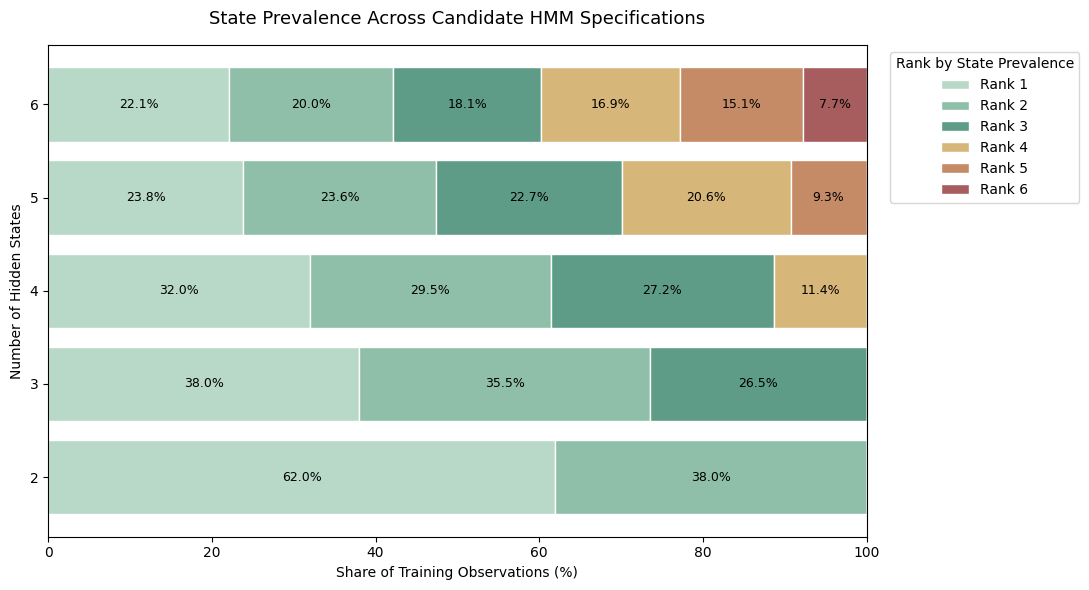

In [15]:

# --------------------------------------------------
# 3.5 Visualize State Prevalence Across Candidate HMMs
# --------------------------------------------------

# Rank states by prevalence within each specification
# State IDs remain arbitrary at this stage.

prevalence_plot_df = state_prevalence_df.copy()

prevalence_plot_df["Prevalence_Rank"] = (
    prevalence_plot_df
    .groupby("States")["Prevalence_Pct"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Prepare percentage distribution by rank
prevalence_pivot = (
    prevalence_plot_df
    .pivot(
        index="States",
        columns="Prevalence_Rank",
        values="Prevalence_Pct"
    )
    .fillna(0)
    .sort_index()
)

# Retain figure for export in Misc
fig_hmm_state_prevalence, ax_hmm_prevalence = plt.subplots(
    figsize=(11, 6)
)

rank_colors = [
    "#B8D8C8",
    "#8FBFA9",
    "#5E9C87",
    "#D7B67A",
    "#C58A66",
    "#A75D5D"
]

left = np.zeros(len(prevalence_pivot))

for i, rank in enumerate(prevalence_pivot.columns):

    values = prevalence_pivot[rank].to_numpy()

    ax_hmm_prevalence.barh(
        prevalence_pivot.index.astype(str),
        values,
        left=left,
        color=rank_colors[i],
        edgecolor="white",
        label=f"Rank {rank}"
    )

    for j, value in enumerate(values):
        if value >= 6:
            ax_hmm_prevalence.text(
                left[j] + value / 2,
                j,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9
            )

    left += values

ax_hmm_prevalence.set_xlim(0, 100)
ax_hmm_prevalence.set_xlabel(
    "Share of Training Observations (%)"
)
ax_hmm_prevalence.set_ylabel(
    "Number of Hidden States"
)

ax_hmm_prevalence.set_title(
    "State Prevalence Across Candidate HMM Specifications",
    fontsize=13,
    pad=15
)

ax_hmm_prevalence.legend(
    title="Rank by State Prevalence",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig_hmm_state_prevalence.tight_layout()
plt.show()


**Key Observations:**
1. Two-state specification: Divides the observations into two broad groups representing 38.04% and 61.96% of the training sample. This may be too coarse to distinguish intermediate market conditions.

2. Three-state specification: Produces shares of 35.54%, 38.00%, and 26.46%. All three states have substantial representation, with at least 1,193 observations per state.

3. Four-state specification: Introduces a smaller state representing 11.36% of observations, indicating greater differentiation among market conditions.

4. Five-state specification: The smallest state's prevalence falls to 9.29%, representing 419 observations.

5. Six-state specification: The smallest state contains 348 observations, or 7.72% of the training sample, suggesting increasingly granular classifications.

### Section 3.6 - Economic Characteristics Across Candidate HMM Specifications

The economic characteristics of the inferred hidden states are examined to assess whether increasing the number of states produces meaningfully different market conditions.

For each candidate HMM specification, the analysis includes:

- **State identification:** Using the fitted HMM to assign training observations to their most likely hidden states.
- **Market uncertainty:** Calculating the average VIX level associated with each state.
- **Realized volatility:** Calculating the average annualized 20-day S&P 500 realized volatility within each state.
- **State prevalence:** Reporting the proportion of training observations assigned to each state.
- **Economic differentiation:** Comparing whether additional states identify distinct market conditions or subdivide broader volatility categories.

The analysis uses the original, unstandardized market variables to preserve their economic interpretation. The state assignments are generated using the standardized training observations.

State identifiers remain arbitrary at this stage and are ordered by their average VIX levels for comparison. The final economic labels are assigned only after selecting the primary HMM specification.

In [16]:

# --------------------------------------------------
# 3.6 Economic Characteristics Across Candidate HMMs
# --------------------------------------------------

economic_characteristics_results = []

for k, model in sorted(candidate_models.items()):

    # Predict hidden states using standardized inputs
    predicted_states = model.predict(X_train_scaled)

    # Preserve original market values for interpretation
    df_candidate = df_train[
        ["VIX_Level", "Realized_Vol_20D"]
    ].copy()

    df_candidate["State_ID"] = predicted_states

    # Summarize each inferred state
    state_summary = (
        df_candidate
        .groupby("State_ID")
        .agg(
            Observations=("VIX_Level", "size"),
            Avg_VIX=("VIX_Level", "mean"),
            Avg_Realized_Vol=("Realized_Vol_20D", "mean")
        )
        .reset_index()
    )

    # Calculate state prevalence
    state_summary["Prevalence_Pct"] = (
        state_summary["Observations"]
        / len(df_train)
        * 100
    )

    # Express realized volatility as a percentage
    state_summary["Avg_Realized_Vol_Pct"] = (
        state_summary["Avg_Realized_Vol"] * 100
    )

    # Add model specification
    state_summary["States"] = k

    # Store results
    economic_characteristics_results.append(
        state_summary[
            [
                "States",
                "State_ID",
                "Observations",
                "Prevalence_Pct",
                "Avg_VIX",
                "Avg_Realized_Vol_Pct"
            ]
        ]
    )

# Combine all candidate model summaries
economic_characteristics_df = pd.concat(
    economic_characteristics_results,
    ignore_index=True
)

# Order states within each specification by average VIX
economic_characteristics_df = (
    economic_characteristics_df
    .sort_values(
        ["States", "Avg_VIX"]
    )
    .reset_index(drop=True)
)

print("Economic Characteristics Across Candidate HMMs\n")

display(economic_characteristics_df.round(2))

Economic Characteristics Across Candidate HMMs



,States,State_ID,Observations,Prevalence_Pct,Avg_VIX,Avg_Realized_Vol_Pct
0,2,1,2793,61.96,14.86,10.88
1,2,0,1715,38.04,28.00,25.24
2,3,0,1602,35.54,13.41,9.31
3,3,2,1713,38.00,19.23,15.49
4,3,1,1193,26.46,29.42,27.02
5,4,0,1329,29.48,12.99,8.84
6,4,3,1226,27.20,18.40,14.27
7,4,2,1441,31.97,22.42,19.03
8,4,1,512,11.36,33.98,33.23
9,5,4,1022,22.67,12.53,8.40


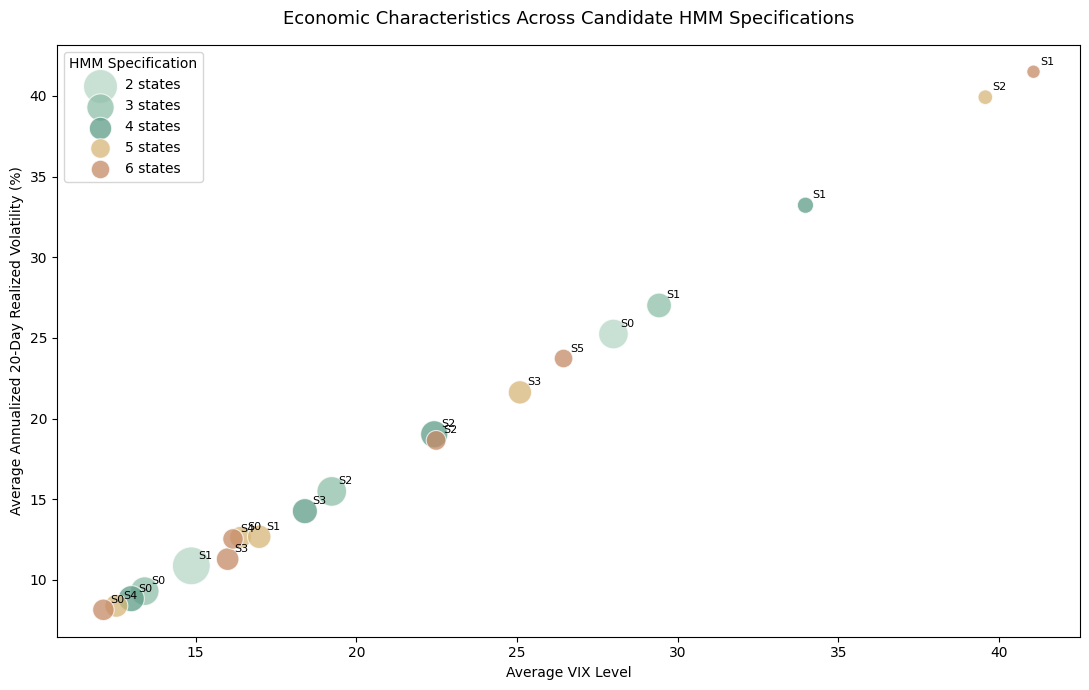

In [17]:

# --------------------------------------------------
# 3.6 Visualize Economic Characteristics Across HMMs
# --------------------------------------------------

# Color palette
state_colors = {
    2: "#B8D8C8",  # Light sage
    3: "#8FBFA9",  # Sage green
    4: "#5E9C87",  # Deep sage
    5: "#D7B67A",  # Warm beige
    6: "#C58A66"   # Terracotta
}

# Retain figure for export in Misc
fig_hmm_economic_characteristics, ax_hmm_economic = plt.subplots(
    figsize=(11, 7)
)

for k in sorted(economic_characteristics_df["States"].unique()):

    subset = economic_characteristics_df[
        economic_characteristics_df["States"] == k
    ]

    ax_hmm_economic.scatter(
        subset["Avg_VIX"],
        subset["Avg_Realized_Vol_Pct"],
        s=subset["Prevalence_Pct"] * 12,
        color=state_colors[k],
        alpha=0.75,
        edgecolors="white",
        linewidths=0.8,
        label=f"{k} states"
    )

    for _, row in subset.iterrows():
        ax_hmm_economic.annotate(
            f"S{int(row['State_ID'])}",
            (
                row["Avg_VIX"],
                row["Avg_Realized_Vol_Pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

ax_hmm_economic.set_title(
    "Economic Characteristics Across Candidate HMM Specifications",
    fontsize=13,
    pad=15
)

ax_hmm_economic.set_xlabel("Average VIX Level")
ax_hmm_economic.set_ylabel(
    "Average Annualized 20-Day Realized Volatility (%)"
)

ax_hmm_economic.legend(
    title="HMM Specification",
    loc="upper left"
)

ax_hmm_economic.grid(False)

fig_hmm_economic_characteristics.tight_layout()
plt.show()


**Key Observations:**

The analysis demonstrates that increasing the number of hidden states produces progressively finer distinctions in market conditions, while the three-state specification provides a clear and economically interpretable classification.

**Key Observations:**

1. **Three-State Economic Differentiation:** The three-state HMM identifies distinct low-, intermediate-, and high-volatility conditions, with average VIX levels of 13.41, 19.23, and 29.42, respectively. Corresponding annualized realized volatilities increase from 9.31% to 15.49% and 27.02%.

2. **Increasing Model Granularity:** The four-, five-, and six-state specifications introduce additional distinctions within intermediate and high-volatility conditions, producing more detailed market classifications.

3. **Overlapping Economic Characteristics:** Higher-state specifications contain some states with similar average VIX and realized volatility. For example, two states in the five-state model exhibit average VIX levels of 16.39 and 16.98, suggesting potential overlap in economic characteristics.

4. **Extreme Market Stress:** The six-state model identifies a high-volatility state with an average VIX of 41.07 and annualized realized volatility of 41.50%, representing 7.72% of training observations. This suggests that additional states may capture meaningful extreme-market conditions.

5. **Three-State Interpretability:** The three-state specification provides a relatively balanced and interpretable representation of Calm, Transition, and Stressed market conditions without introducing additional states with closely related average volatility characteristics.

**Implications for Model Selection**

Although higher-state specifications offer greater statistical fit and potentially more detailed classifications, the three-state HMM provides a better reference for interpreting market conditions and integrating regime information into subsequent forecasting.

The selection prioritizes economic interpretability rather than the lowest BIC. Similarities between higher-state regimes are based on average VIX and realized volatility and do not establish that those states are statistically redundant.


### Section 3.7 - Summary of HMM State Count Selection and Sensitivity Analysis

This section evaluated alternative Gaussian Hidden Markov Model (HMM) specifications to determine an appropriate number of latent market states, considering statistical fit, state prevalence, and economic interpretability.

**Activities Performed:**

- Estimated Gaussian HMM specifications containing 2 to 6 hidden states using the standardized training observations.
- Applied 10 random initializations per specification to reduce sensitivity to local optima.
- Compared training log-likelihood and Bayesian Information Criterion (BIC) across candidate models.
- Examined state frequencies and prevalence to assess how observations were distributed across alternative specifications.
- Compared average VIX levels and annualized 20-day realized volatility across inferred states.
- Developed supporting visualizations to assess state prevalence and economic differentiation.

**Key Observations:**

1. **Model Convergence:** All five candidate HMM specifications converged successfully.

2. **Statistical Model Selection:** BIC decreased consistently as the number of hidden states increased, from 45,715.96 for the two-state model to 32,894.96 for the six-state model. The six-state specification therefore achieved the lowest BIC among the candidates evaluated.

3. **State Prevalence:** The three-state model produced a relatively balanced distribution, with state shares of 35.54%, 38.00%, and 26.46%. Higher-state specifications introduced smaller states, with the six-state model's least prevalent state accounting for 7.72% of training observations.

4. **Economic Differentiation:** The three-state model identified distinct low-, intermediate-, and high-volatility market conditions. Average VIX levels increased from 13.41 to 19.23 and 29.42, while corresponding annualized realized volatility increased from 9.31% to 15.49% and 27.02%.

5. **Higher-State Granularity:** Four-, five-, and six-state specifications generated finer classifications of market conditions. Some additional states exhibited similar average VIX and realized volatility, while others captured more extreme market stress.

6. **Extreme-Stress Identification:** The six-state specification identified a high-volatility state with an average VIX of 41.07 and annualized realized volatility of 41.50%, demonstrating that additional states may capture economically meaningful distinctions.

**Implications for Subsequent Modeling**

Although the six-state specification achieved the lowest BIC, the three-state model was selected as the primary HMM specification to prioritize parsimony and economic interpretability.

The three-state specification provides a clear representation of Calm, Transition, and Stressed market conditions while maintaining substantial observation counts in each regime.

This choice represents an interpretability-driven modeling decision rather than the BIC-optimal specification. Higher-state alternatives may capture additional market structure, particularly during periods of extreme stress.

The following section estimates and characterizes the selected three-state HMM, including regime assignments and their economic interpretation.

## Section 4 - Final Three-State HMM Estimation and Regime Identification

Following the state-count selection and sensitivity analysis, the three-state Gaussian Hidden Markov Model (HMM) is retained as the primary specification for identifying latent equity market regimes.

The model uses five standardized market predictors and parameters estimated exclusively from the 2000–2017 training period.

The analysis includes:

- **Model selection:** Retrieving the selected three-state HMM from the candidate estimation results.
- **State identification:** Assigning training observations to their most likely hidden states.
- **Economic labeling:** Mapping the numerical hidden states to Calm, Transition, and Stressed regimes based on their average VIX levels.
- **Regime characterization:** Evaluating regime prevalence and differences in market uncertainty, realized volatility, skewness, and kurtosis.
- **Visualization:** Examining the historical distribution of identified regimes alongside S&P 500 market movements.

The resulting classifications provide an interpretable representation of changing market conditions. Subsequent sections assess whether the identified regimes remain consistent during the testing period and examine their transition dynamics.

The model's parameters remain fixed when evaluating observations outside the training period.

### Section 4.1 - Retrive the Selected HMM and Identify Training Regimes

The three-state Gaussian Hidden Markov Model (HMM) is retrieved from the candidate models estimated in Section 3.

The analysis includes:

- **Model retrieval:** Selecting the fitted three-state HMM retained during candidate model estimation.
- **Training-state identification:** Applying the fitted HMM to the standardized 2000–2017 training observations to infer the most likely sequence of hidden states.
- **State assignment:** Associating the inferred numerical state identifiers with their corresponding trading dates and original market observations.
- **Initial validation:** Confirming that all training observations receive a valid state assignment and that exactly three states are represented.

The numerical state identifiers are arbitrary at this stage. Economic labels are assigned in the following subsection using average training-period VIX levels.

State assignments are used for historical regime characterization. The distinction between full-sequence state decoding and information available at each trading date will be considered separately when generating filtered probabilities for Model A.

In [18]:
# --------------------------------------------------
# 4.1 Retrieve Selected HMM and Identify Training Regimes
# --------------------------------------------------

# Retrieve previously fitted three-state HMM
hmm_model = candidate_models[3]

# Verify selected model specification
assert hmm_model.n_components == 3
assert hmm_model.covariance_type == "full"
assert hmm_model.monitor_.converged

# Identify the most likely training-state sequence
train_states = hmm_model.predict(X_train_scaled)

# Construct training regime dataset
df_train_regimes = df_train.copy()

df_train_regimes["State_ID"] = train_states

# Validate state assignments
assert len(train_states) == len(df_train)

assert set(np.unique(train_states)) == {0, 1, 2}

assert df_train_regimes["State_ID"].notna().all()

# Display model and assignment information
print("Selected Three-State HMM\n")

print("Number of hidden states:", hmm_model.n_components)
print("Covariance specification:", hmm_model.covariance_type)
print("Model converged:", hmm_model.monitor_.converged)

print("\nTraining state distribution:")
print(
    df_train_regimes["State_ID"]
    .value_counts()
    .sort_index()
)

print("\nTraining regime dataset:")
print("Shape:", df_train_regimes.shape)

print("\nFirst five observations:")
display(
    df_train_regimes[
        ["Date", "SP500_Close", "VIX_Level",
         "Realized_Vol_20D", "State_ID"]
    ].head()
)

Selected Three-State HMM

Number of hidden states: 3
Covariance specification: full
Model converged: True

Training state distribution:
State_ID
0    1602
1    1193
2    1713
Name: count, dtype: int64

Training regime dataset:
Shape: (4508, 8)

First five observations:


,Date,SP500_Close,VIX_Level,Realized_Vol_20D,State_ID
0,2000-02-01,1409.280029,23.45,0.263633,2
1,2000-02-02,1409.119995,23.12,0.223332,2
2,2000-02-03,1424.969971,22.01,0.226596,2
3,2000-02-04,1424.369995,21.54,0.226637,2
4,2000-02-07,1424.239990,22.79,0.204786,2


### Section 4.2 - Economic Regime Labeling

The numerical states identified by the Gaussian HMM are assigned economically interpretable labels based on their average VIX levels during the training period (2000–2017).

The labeling procedure includes:

- **State characterization:** Calculating the average VIX level and annualized 20-day realized volatility for each numerical state.
- **Economic ordering:** Ranking the three states according to their average VIX levels, from lowest to highest.
- **Regime labeling:** Assigning the labels Calm, Transition, and Stressed based on the resulting ordering.
- **Label consistency:** Establishing a fixed mapping that will also be applied to testing-period state assignments.

The VIX is used as the primary labeling criterion because it provides a market-based measure of expected near-term volatility. Realized volatility is examined as a complementary indicator of the economic characteristics of each state.

The labels are descriptive interpretations of the inferred states rather than predefined classes used during model estimation.

In [19]:

# --------------------------------------------------
# 4.2 Economic Regime Labeling
# --------------------------------------------------

# Calculate training-period characteristics by state
state_characteristics = (
    df_train_regimes
    .groupby("State_ID")
    .agg(
        Observations=("VIX_Level", "size"),
        Avg_VIX=("VIX_Level", "mean"),
        Avg_Realized_Vol=("Realized_Vol_20D", "mean")
    )
    .reset_index()
)

# Convert realized volatility to percentage units
state_characteristics["Avg_Realized_Vol_Pct"] = (
    state_characteristics["Avg_Realized_Vol"] * 100
)

# Rank states by average VIX (ascending)
state_characteristics = (
    state_characteristics
    .sort_values("Avg_VIX")
    .reset_index(drop=True)
)

# Assign economic labels
regime_labels = ["Calm", "Transition", "Stressed"]

state_characteristics["Regime"] = regime_labels

# Construct fixed mapping from State_ID to regime label
state_to_regime = dict(
    zip(
        state_characteristics["State_ID"],
        state_characteristics["Regime"]
    )
)

# Apply labels to training observations
df_train_regimes["Regime"] = (
    df_train_regimes["State_ID"].map(state_to_regime)
)

# Validate labeling
assert df_train_regimes["Regime"].notna().all()
assert set(df_train_regimes["Regime"].unique()) == set(regime_labels)

# Display results
print("Training-Based Economic Regime Labeling\n")

display(
    state_characteristics[
        [
            "State_ID",
            "Regime",
            "Observations",
            "Avg_VIX",
            "Avg_Realized_Vol_Pct"
        ]
    ].round(2)
)

print("\nFixed State-to-Regime Mapping:")
print(state_to_regime)

Training-Based Economic Regime Labeling



,State_ID,Regime,Observations,Avg_VIX,Avg_Realized_Vol_Pct
0,0,Calm,1602,13.41,9.31
1,2,Transition,1713,19.23,15.49
2,1,Stressed,1193,29.42,27.02



Fixed State-to-Regime Mapping:
{0: 'Calm', 2: 'Transition', 1: 'Stressed'}


### Section 4.3 - Training Regime Characteristics

The economic characteristics of the three identified market regimes are examined using the original market indicators and their standardized representations.

The analysis includes:

- **Regime prevalence:** Calculating the number and percentage of training observations assigned to each regime.
- **Market uncertainty:** Comparing average VIX levels and daily VIX changes across regimes.
- **Realized volatility:** Evaluating differences in annualized 20-day realized volatility.
- **Return distributions:** Examining average 20-day return skewness and excess kurtosis.
- **Feature visualization:** Comparing standardized market characteristics across Calm, Transition, and Stressed regimes.

The descriptive analysis uses the original feature values to preserve their economic interpretation.

For visualization, regime-level feature means are standardized using the training-period scaling parameters estimated in Section 2.3. This allows the five variables to be compared on a common scale.

These characteristics describe the historical observations associated with each inferred regime; they do not constitute independent evidence of the model's predictive performance.

In [20]:

# --------------------------------------------------
# 4.3 Training Regime Characteristics
# --------------------------------------------------

regime_order = ["Calm", "Transition", "Stressed"]

# Calculate regime-level descriptive statistics
regime_characteristics = (
    df_train_regimes
    .groupby("Regime")
    .agg(
        Observations=("Date", "size"),
        Avg_VIX=("VIX_Level", "mean"),
        Avg_VIX_Change=("VIX_Change", "mean"),
        Avg_Realized_Vol_20D=("Realized_Vol_20D", "mean"),
        Avg_Return_Skew_20D=("Return_Skew_20D", "mean"),
        Avg_Return_Kurt_20D=("Return_Kurt_20D", "mean")
    )
    .reindex(regime_order)
)

# Calculate prevalence
regime_characteristics["Prevalence_Pct"] = (
    regime_characteristics["Observations"]
    / len(df_train_regimes)
    * 100
)

# Express realized volatility as a percentage
regime_characteristics["Avg_Realized_Vol_20D_Pct"] = (
    regime_characteristics["Avg_Realized_Vol_20D"]
    * 100
)

# Arrange columns for reporting
regime_characteristics = regime_characteristics[
    [
        "Observations",
        "Prevalence_Pct",
        "Avg_VIX",
        "Avg_VIX_Change",
        "Avg_Realized_Vol_20D_Pct",
        "Avg_Return_Skew_20D",
        "Avg_Return_Kurt_20D"
    ]
]

# Validate observations
assert regime_characteristics["Observations"].sum() == len(df_train)
assert regime_characteristics.notna().all().all()

print("Training Regime Characteristics\n")
display(regime_characteristics.round(4))

Training Regime Characteristics



,Observations,Prevalence_Pct,Avg_VIX,Avg_VIX_Change,Avg_Realized_Vol_20D_Pct,Avg_Return_Skew_20D,Avg_Return_Kurt_20D
Regime,,,,,,,
Calm,1602,35.5368,13.4101,-0.0058,9.3080,0.2008,0.3846
Transition,1713,37.9991,19.2329,0.0019,15.4896,-0.4937,0.6472
Stressed,1193,26.4641,29.4197,-0.0066,27.0164,0.2846,0.3363


Standardized Market Characteristics by Regime



,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D
Regime,,,,,
Calm,-0.7366,-0.0016,-0.6720,0.3800,-0.0617
Transition,-0.0716,0.0030,-0.0815,-0.7118,0.1245
Stressed,1.0919,-0.0021,1.0195,0.5118,-0.0960


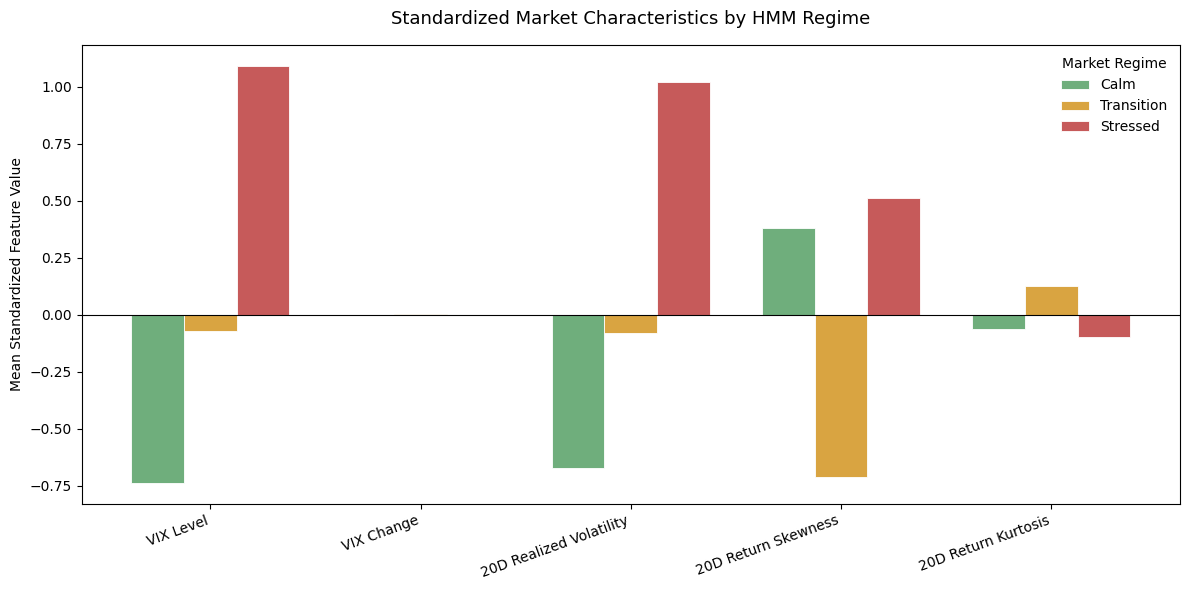

In [21]:

# --------------------------------------------------
# 4.3 Visualize Standardized Regime Characteristics
# --------------------------------------------------

# Calculate mean standardized features for each regime
df_train_standardized = pd.DataFrame(
    X_train_scaled,
    columns=hmm_features,
    index=df_train_regimes.index
)

df_train_standardized["Regime"] = df_train_regimes["Regime"]

standardized_regime_means = (
    df_train_standardized
    .groupby("Regime")[hmm_features]
    .mean()
    .reindex(regime_order)
)

# Validate standardized regime means
assert standardized_regime_means.notna().all().all()

print("Standardized Market Characteristics by Regime\n")
display(standardized_regime_means.round(4))

# --------------------------------------------------
# Visualization
# --------------------------------------------------

feature_labels = [
    "VIX Level",
    "VIX Change",
    "20D Realized Volatility",
    "20D Return Skewness",
    "20D Return Kurtosis"
]

x = np.arange(len(hmm_features))
bar_width = 0.25

# Retain figure for export in Misc
fig_hmm_regime_characteristics, ax_hmm_characteristics = plt.subplots(
    figsize=(12, 6)
)

for i, regime in enumerate(regime_order):

    ax_hmm_characteristics.bar(
        x + (i - 1) * bar_width,
        standardized_regime_means.loc[regime].values,
        width=bar_width,
        color=regime_colors[regime],
        label=regime,
        edgecolor="white",
        linewidth=0.6
    )

# Reference line at the training-period mean
ax_hmm_characteristics.axhline(
    y=0,
    color="black",
    linewidth=0.8
)

# Axis configuration
ax_hmm_characteristics.set_xticks(x)

ax_hmm_characteristics.set_xticklabels(
    feature_labels,
    rotation=20,
    ha="right"
)

ax_hmm_characteristics.set_ylabel(
    "Mean Standardized Feature Value"
)

ax_hmm_characteristics.set_title(
    "Standardized Market Characteristics by HMM Regime",
    fontsize=13,
    pad=15
)

# Regime legend
ax_hmm_characteristics.legend(
    title="Market Regime",
    frameon=False
)

# Remove gridlines
ax_hmm_characteristics.grid(False)

# Improve layout
fig_hmm_regime_characteristics.tight_layout()

plt.show()

**Key Observations:**

1. **Volatility Differentiation:** VIX Level and 20-day Realized Volatility provide the clearest separation between regimes. Calm observations have standardized means of -0.7366 and -0.6720, while Stressed observations have corresponding means of 1.0919 and 1.0195.

2. **Transition Regime Characteristics:** Transition exhibits the most negative average standardized return skewness (-0.7118), indicating a greater tendency toward negatively skewed trailing return distributions relative to the training-period baseline.

3. **Stressed Regime Characteristics:** Stressed observations exhibit the highest average VIX and realized volatility but positive average standardized return skewness (0.5118), demonstrating that elevated volatility does not necessarily coincide with negative average rolling skewness.

4. **VIX Change and Kurtosis:** Both features exhibit comparatively small differences in regime-level standardized means, although they may contribute additional information through their variability and relationships with other predictors.

5. **Multidimensional Market Classification:** The regimes differ not only in market volatility but also in return distribution characteristics, supporting a multidimensional interpretation of the identified states.

**Implications for Subsequent Modeling**

The standardized feature profiles support the economic interpretation of Calm, Transition, and Stressed market regimes. VIX levels and realized volatility provide the strongest descriptive differentiation, while skewness and kurtosis capture additional characteristics of historical return distributions.

These findings motivate further examination of regime persistence, historical market behavior, and the stability of regime characteristics outside the training period.

### Section 4.4 - Historical Market Regime Visualization

The historical distribution of the three inferred HMM regimes is examined alongside movements in the S&P 500 Index during the training period (2000–2017).

The visualization includes:

- **Market performance:** Plotting daily S&P 500 closing values to provide historical market context.
- **Regime identification:** Highlighting observations classified as Calm, Transition, or Stressed using the standardized regime color scheme.
- **Historical interpretation:** Examining whether inferred Stressed conditions align with periods of heightened market uncertainty, including the 2008 Global Financial Crisis.
- **Regime evolution:** Assessing the timing, frequency, and persistence of regime assignments throughout the training period.

The visualization uses the most likely hidden-state sequence inferred from the fitted HMM. These classifications are appropriate for retrospective market analysis but should not be interpreted as real-time state estimates because full-sequence decoding can incorporate later observations.

The corresponding filtered regime probabilities used in Model A are generated and evaluated separately.

/tmp/ipykernel_836/1320233533.py:366: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig_hmm_training_timeline.tight_layout()


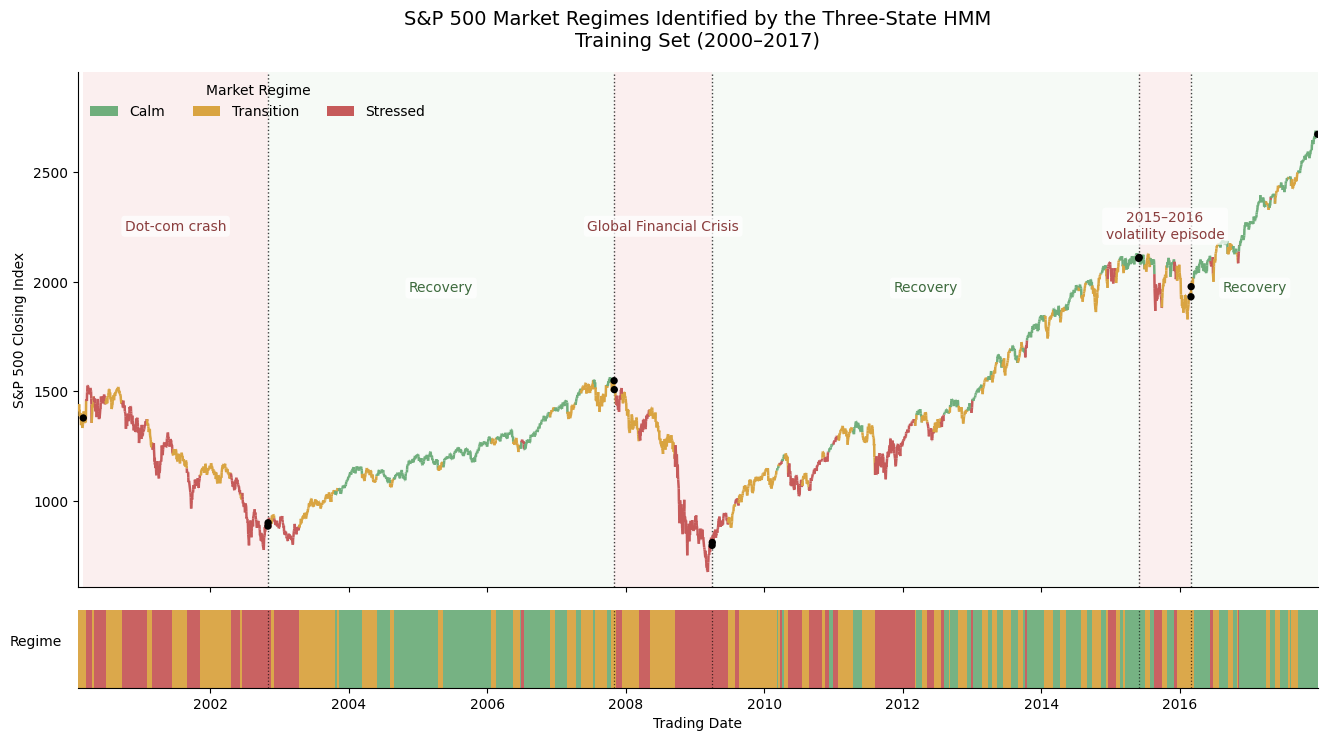

In [22]:
# --------------------------------------------------
# 4.4 Historical Market Regime Visualization — Training Set
# --------------------------------------------------

# --------------------------------------------------
# Prepare chronological plotting dataset
# --------------------------------------------------

df_regime_timeline = (
    df_train_regimes[["Date", "SP500_Close", "Regime"]]
    .sort_values("Date")
    .reset_index(drop=True)
)

# Identify consecutive regime segments
df_regime_timeline["Regime_Segment"] = (
    df_regime_timeline["Regime"]
    .ne(df_regime_timeline["Regime"].shift())
    .cumsum()
)

regime_segments = (
    df_regime_timeline
    .groupby("Regime_Segment")
    .agg(
        Start_Date=("Date", "first"),
        Regime=("Regime", "first")
    )
    .reset_index(drop=True)
)

# Use the next segment's start as its right boundary
segment_starts = regime_segments["Start_Date"].to_list()

segment_ends = segment_starts[1:] + [
    df_regime_timeline["Date"].iloc[-1] + pd.Timedelta(days=1)
]

# --------------------------------------------------
# Define historical market phases
# --------------------------------------------------

# Approximate historical windows used for visual context
# rather than as inputs to HMM estimation.

market_phases = [
    {
        "label": "Dot-com crash",
        "start": "2000-03-01",
        "end": "2002-10-31",
        "phase": "event"
    },
    {
        "label": "Recovery",
        "start": "2002-11-01",
        "end": "2007-10-31",
        "phase": "recovery"
    },
    {
        "label": "Global Financial Crisis",
        "start": "2007-11-01",
        "end": "2009-03-31",
        "phase": "event"
    },
    {
        "label": "Recovery",
        "start": "2009-04-01",
        "end": "2015-05-31",
        "phase": "recovery"
    },
    {
        "label": "2015–2016\nvolatility episode",
        "start": "2015-06-01",
        "end": "2016-02-29",
        "phase": "event"
    },
    {
        "label": "Recovery",
        "start": "2016-03-01",
        "end": "2017-12-31",
        "phase": "recovery"
    }
]

# Historical phase background colors
phase_colors = {
    "event": "#EFB7B7",
    "recovery": "#CFE8CF"
}

phase_alpha = {
    "event": 0.22,
    "recovery": 0.18
}

# --------------------------------------------------
# Prepare regime-colored S&P 500 line
# --------------------------------------------------

x_dates = mdates.date2num(df_regime_timeline["Date"])
y_prices = df_regime_timeline["SP500_Close"].to_numpy()
regimes = df_regime_timeline["Regime"].to_numpy()

points = np.column_stack(
    (x_dates, y_prices)
).reshape(-1, 1, 2)

segments = np.concatenate(
    [points[:-1], points[1:]],
    axis=1
)

# Apply the regime of the starting observation
segment_colors = [
    regime_colors[regime]
    for regime in regimes[:-1]
]

# --------------------------------------------------
# Create two-panel visualization
# --------------------------------------------------

fig_hmm_training_timeline, (
    ax_hmm_price,
    ax_hmm_regime_band
) = plt.subplots(
    2, 1,
    figsize=(16, 8),
    sharex=True,
    gridspec_kw={
        "height_ratios": [4, 0.6],
        "hspace": 0.08
    }
)

# --------------------------------------------------
# Upper panel: historical market phase backgrounds
# --------------------------------------------------

for phase in market_phases:

    start = pd.to_datetime(phase["start"])
    end = pd.to_datetime(phase["end"])

    ax_hmm_price.axvspan(
        start,
        end,
        color=phase_colors[phase["phase"]],
        alpha=phase_alpha[phase["phase"]],
        linewidth=0,
        zorder=0
    )

# Add dotted lines between consecutive phases
for i in range(1, len(market_phases)):

    boundary = pd.to_datetime(
        market_phases[i]["start"]
    )

    ax_hmm_price.axvline(
        boundary,
        color="black",
        linestyle=":",
        linewidth=1.0,
        alpha=0.75,
        zorder=1
    )

# --------------------------------------------------
# Upper panel: regime-colored S&P 500 price line
# --------------------------------------------------

price_collection = LineCollection(
    segments,
    colors=segment_colors,
    linewidths=1.8,
    zorder=3
)

ax_hmm_price.add_collection(price_collection)

ax_hmm_price.set_xlim(
    x_dates.min(),
    x_dates.max()
)

ax_hmm_price.set_ylim(
    y_prices.min() * 0.90,
    y_prices.max() * 1.10
)

# --------------------------------------------------
# Add black dots at historical phase boundaries
# --------------------------------------------------

# Deduplicate boundary observations so each point
# appears only once, even if phases share a boundary.

boundary_points = {}

for phase in market_phases:

    start = pd.to_datetime(phase["start"])
    end = pd.to_datetime(phase["end"])

    phase_data = df_regime_timeline[
        df_regime_timeline["Date"].between(start, end)
    ]

    if phase_data.empty:
        continue

    for row in [phase_data.iloc[0], phase_data.iloc[-1]]:
        boundary_points[row["Date"]] = row["SP500_Close"]

# Plot solid black dots without Start/End captions
ax_hmm_price.scatter(
    list(boundary_points.keys()),
    list(boundary_points.values()),
    s=28,
    color="black",
    edgecolors="none",
    zorder=5
)

# --------------------------------------------------
# Add market phase captions near the chart center
# --------------------------------------------------

text_transform = mtransforms.blended_transform_factory(
    ax_hmm_price.transData,
    ax_hmm_price.transAxes
)

for phase in market_phases:

    start = pd.to_datetime(phase["start"])
    end = pd.to_datetime(phase["end"])

    mid = start + (end - start) / 2

    if phase["phase"] == "event":
        text_color = "#8A3D3D"
        y_pos = 0.70
    else:
        text_color = "#3E6B3E"
        y_pos = 0.58

    ax_hmm_price.text(
        mid,
        y_pos,
        phase["label"],
        transform=text_transform,
        ha="center",
        va="center",
        fontsize=10,
        color=text_color,
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75
        },
        zorder=4
    )

# --------------------------------------------------
# Lower panel: continuous HMM regime timeline
# --------------------------------------------------

for (_, segment), end_date in zip(
    regime_segments.iterrows(),
    segment_ends
):

    ax_hmm_regime_band.axvspan(
        segment["Start_Date"],
        end_date,
        color=regime_colors[segment["Regime"]],
        alpha=0.95,
        linewidth=0
    )

# Mirror market phase dividers in lower panel
for i in range(1, len(market_phases)):

    boundary = pd.to_datetime(
        market_phases[i]["start"]
    )

    ax_hmm_regime_band.axvline(
        boundary,
        color="black",
        linestyle=":",
        linewidth=0.9,
        alpha=0.65
    )

ax_hmm_regime_band.set_ylim(0, 1)
ax_hmm_regime_band.set_yticks([])

ax_hmm_regime_band.set_ylabel(
    "Regime",
    rotation=0,
    labelpad=30
)

# --------------------------------------------------
# Titles, axis labels, and legend
# --------------------------------------------------

ax_hmm_price.set_title(
    "S&P 500 Market Regimes Identified by the Three-State HMM\n"
    "Training Set (2000–2017)",
    fontsize=14,
    pad=18
)

ax_hmm_price.set_ylabel(
    "S&P 500 Closing Index"
)

ax_hmm_regime_band.xaxis.set_major_locator(
    mdates.YearLocator(2)
)

ax_hmm_regime_band.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax_hmm_regime_band.set_xlabel(
    "Trading Date"
)

# Market regime legend only
regime_legend_handles = [
    Patch(
        facecolor=regime_colors[regime],
        label=regime
    )
    for regime in regime_order
]

ax_hmm_price.legend(
    handles=regime_legend_handles,
    title="Market Regime",
    loc="upper left",
    ncol=3,
    frameon=False
)

# --------------------------------------------------
# Final styling
# --------------------------------------------------

for ax in [ax_hmm_price, ax_hmm_regime_band]:

    ax.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

ax_hmm_regime_band.spines["left"].set_visible(False)

fig_hmm_training_timeline.tight_layout()

plt.show()

**Key Observations:**
The historical visualization illustrates how the three-state Gaussian HMM classified market conditions throughout the 2000–2017 training period. Regime-colored S&P 500 movements are presented alongside major historical financial events and subsequent recovery periods.

1. **Dot-Com Crash (2000–2002):** The market downturn coincides with frequent Stressed and Transition classifications, reflecting heightened market uncertainty and volatility during the decline in the S&P 500.

2. **Post-Dot-Com Recovery (2002–2007):** The recovery period is characterized by an increasing presence of Calm conditions, alongside intermittent Transition regimes, as the S&P 500 recovered from its earlier losses.

3. **Global Financial Crisis (2007–2009):** The sharp decline in the S&P 500 coincides with a prolonged concentration of Stressed classifications, demonstrating the HMM's ability to retrospectively distinguish periods of severe market disruption.

4. **Post-Crisis Recovery (2009–2015):** The sustained market recovery exhibits a mixture of Calm and Transition conditions, with occasional Stressed episodes, indicating that favorable market performance does not necessarily imply uninterrupted market stability.

5. **Market Volatility Episode (2015–2016):** The market experienced renewed periods of Transition and Stressed classifications, consistent with increased uncertainty and temporary declines in equity prices.

6. **Regime Persistence and Switching:** The visualization reveals both sustained market conditions and shorter-lived regime changes. The lower regime timeline provides additional visibility into the duration and frequency of these transitions.

**Implications for Subsequent Modeling**

The historical alignment between inferred market regimes and major financial events supports the economic interpretability of the three-state HMM.

However, the regime assignments are derived from retrospective full-sequence decoding and should not be interpreted as real-time market predictions. The historical event and recovery windows are provided exclusively for contextual interpretation and were not used in model estimation.

The following sections examine whether the identified regimes remain consistent during the 2018–2025 testing period and assess their temporal persistence through estimated state-transition probabilities.

## Section 5 - Train-Test Regime Stability

### Section 5.1 - Out of Sample Regime Identification

The fitted three-state Gaussian HMM is applied to the 2018–2025 testing dataset to assess whether the latent market-state structure identified during training remains applicable to subsequent observations.

The procedure includes:

- Applying the training-fitted HMM to the standardized testing feature matrix.
- Inferring the most likely sequence of hidden states without re-estimating model parameters.
- Applying the fixed training-derived mapping from numerical states to Calm, Transition, and Stressed.
- Verifying the completeness and consistency of testing-period state assignments.

The testing observations are treated as a separate sequence for retrospective state decoding. The resulting labels may depend on subsequent observations within that sequence and therefore are not interpreted as real-time signals.

In [23]:

# --------------------------------------------------
# 5.1 Out-of-Sample Regime Identification
# --------------------------------------------------

# Apply the training-fitted HMM to standardized test data
test_states = hmm_model.predict(X_test_scaled)

# Construct test regime dataset
df_test_regimes = df_test.copy()

# Attach inferred numerical states
df_test_regimes["State_ID"] = test_states

# Apply fixed training-derived economic labels
df_test_regimes["Regime"] = (
    df_test_regimes["State_ID"].map(state_to_regime)
)

# Validate assignments
assert len(df_test_regimes) == len(df_test)
assert df_test_regimes["State_ID"].between(0, 2).all()
assert df_test_regimes["Regime"].notna().all()

assert set(df_test_regimes["Regime"].unique()) == set(regime_order)

# Confirm testing coverage
assert df_test_regimes["Date"].min() > df_train_regimes["Date"].max()

print("Out-of-Sample HMM Regime Identification\n")

print("Training observations:", len(df_train_regimes))
print("Testing observations:", len(df_test_regimes))

print("\nTesting period:")
print(
    df_test_regimes["Date"].min().date(),
    "to",
    df_test_regimes["Date"].max().date()
)

print("\nTesting regime distribution:")
print(
    df_test_regimes["Regime"]
    .value_counts()
    .reindex(regime_order)
)

print("\nFirst five testing observations:")
display(
    df_test_regimes[
        [
            "Date",
            "SP500_Close",
            "VIX_Level",
            "Realized_Vol_20D",
            "State_ID",
            "Regime"
        ]
    ].head()
)

Out-of-Sample HMM Regime Identification

Training observations: 4508
Testing observations: 2011

Testing period:
2018-01-02 to 2025-12-31

Testing regime distribution:
Regime
Calm          619
Transition    988
Stressed      404
Name: count, dtype: int64

First five testing observations:


,Date,SP500_Close,VIX_Level,Realized_Vol_20D,State_ID,Regime
4508,2018-01-02,2695.810059,9.77,0.061742,2,Transition
4509,2018-01-03,2713.060059,9.15,0.064050,0,Calm
4510,2018-01-04,2723.989990,9.22,0.061703,0,Calm
4511,2018-01-05,2743.149902,9.22,0.063967,0,Calm
4512,2018-01-08,2747.709961,9.52,0.063913,0,Calm


### Section 5.2 - Training - Testing Regime Prevalance Comparison

The distribution of inferred market regimes is compared between the training (2000–2017) and testing (2018–2025) periods to examine changes in the prevalence of different market conditions.

The analysis includes:

- **Regime frequency:** Calculating the number of observations assigned to each regime in the training and testing periods.
- **Regime prevalence:** Expressing regime frequencies as percentages of their respective samples.
- **Distributional comparison:** Calculating percentage-point changes in regime prevalence between the two periods.
- **Visualization:** Comparing regime distributions using a grouped bar chart with the standardized Calm, Transition, and Stressed color scheme.

Differences in regime prevalence may reflect changing market conditions across periods. However, they do not independently establish whether the underlying regime characteristics or transition dynamics have remained stable.

The following subsection therefore examines the economic characteristics associated with each regime in both periods.

In [24]:

# --------------------------------------------------
# 5.2 Training–Testing Regime Prevalence Comparison
# --------------------------------------------------

regime_prevalence_comparison = pd.DataFrame({
    "Train_Count": (
        df_train_regimes["Regime"]
        .value_counts()
        .reindex(regime_order)
    ),
    "Test_Count": (
        df_test_regimes["Regime"]
        .value_counts()
        .reindex(regime_order)
    )
})

# Calculate prevalence within each period
regime_prevalence_comparison["Train_Pct"] = (
    regime_prevalence_comparison["Train_Count"]
    / len(df_train_regimes)
    * 100
)

regime_prevalence_comparison["Test_Pct"] = (
    regime_prevalence_comparison["Test_Count"]
    / len(df_test_regimes)
    * 100
)

# Calculate percentage-point difference
regime_prevalence_comparison["Change_Pct_Points"] = (
    regime_prevalence_comparison["Test_Pct"]
    - regime_prevalence_comparison["Train_Pct"]
)

# Validate percentages
assert np.isclose(
    regime_prevalence_comparison["Train_Pct"].sum(),
    100
)

assert np.isclose(
    regime_prevalence_comparison["Test_Pct"].sum(),
    100
)

print("Training–Testing Regime Prevalence Comparison\n")
display(regime_prevalence_comparison.round(2))

Training–Testing Regime Prevalence Comparison



,Train_Count,Test_Count,Train_Pct,Test_Pct,Change_Pct_Points
Regime,,,,,
Calm,1602,619,35.54,30.78,-4.76
Transition,1713,988,38.00,49.13,11.13
Stressed,1193,404,26.46,20.09,-6.37


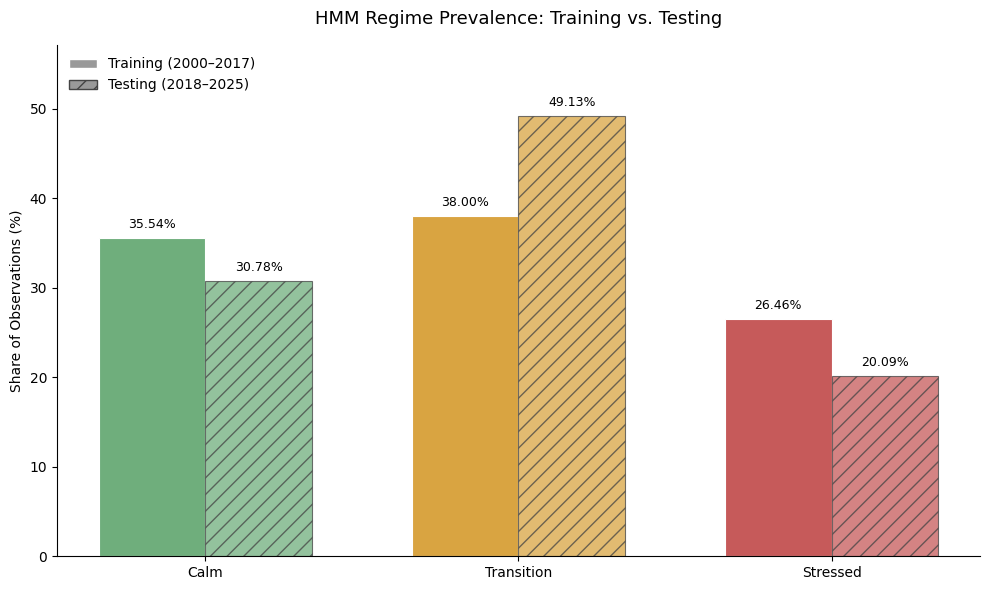

In [25]:

# --------------------------------------------------
# 5.2 Visualize Training–Testing Regime Prevalence
# --------------------------------------------------

x = np.arange(len(regime_order))
bar_width = 0.34

# Retain figure for export in Misc
fig_hmm_regime_prevalence_comparison, ax_hmm_prevalence_compare = (
    plt.subplots(figsize=(10, 6))
)

for i, regime in enumerate(regime_order):

    train_pct = regime_prevalence_comparison.loc[
        regime, "Train_Pct"
    ]

    test_pct = regime_prevalence_comparison.loc[
        regime, "Test_Pct"
    ]

    # Training period
    ax_hmm_prevalence_compare.bar(
        x[i] - bar_width / 2,
        train_pct,
        width=bar_width,
        color=regime_colors[regime],
        edgecolor="white",
        linewidth=0.8
    )

    # Testing period
    ax_hmm_prevalence_compare.bar(
        x[i] + bar_width / 2,
        test_pct,
        width=bar_width,
        color=regime_colors[regime],
        edgecolor="#444444",
        linewidth=0.8,
        hatch="//",
        alpha=0.75
    )

    # Percentage labels
    for position, value in [
        (x[i] - bar_width / 2, train_pct),
        (x[i] + bar_width / 2, test_pct)
    ]:
        ax_hmm_prevalence_compare.text(
            position,
            value + 0.8,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

# Axis formatting
ax_hmm_prevalence_compare.set_xticks(x)
ax_hmm_prevalence_compare.set_xticklabels(regime_order)

ax_hmm_prevalence_compare.set_ylabel(
    "Share of Observations (%)"
)

ax_hmm_prevalence_compare.set_ylim(
    0,
    regime_prevalence_comparison[
        ["Train_Pct", "Test_Pct"]
    ].to_numpy().max() + 8
)

ax_hmm_prevalence_compare.set_title(
    "HMM Regime Prevalence: Training vs. Testing",
    fontsize=13,
    pad=15
)

# Period legend
from matplotlib.patches import Patch

period_legend = [
    Patch(
        facecolor="#999999",
        edgecolor="white",
        label="Training (2000–2017)"
    ),
    Patch(
        facecolor="#999999",
        edgecolor="#444444",
        hatch="//",
        label="Testing (2018–2025)"
    )
]

ax_hmm_prevalence_compare.legend(
    handles=period_legend,
    frameon=False,
    loc="upper left"
)

# Remove gridlines
ax_hmm_prevalence_compare.grid(False)

ax_hmm_prevalence_compare.spines["top"].set_visible(False)
ax_hmm_prevalence_compare.spines["right"].set_visible(False)

fig_hmm_regime_prevalence_comparison.tight_layout()

plt.show()


**Key Observations:**

The comparison reveals changes in the distribution of inferred market regimes between the training (2000–2017) and testing (2018–2025) periods.

1. **Transition Regime:** Its prevalence increased from 38.00% during training to 49.13% during testing, representing an increase of 11.13 percentage points.

2. **Calm Regime:** Its prevalence declined from 35.54% to 30.78%, a decrease of 4.76 percentage points.

3. **Stressed Regime:** Its prevalence declined from 26.46% to 20.09%, a decrease of 6.37 percentage points.

4. **Distributional Shift:** The testing period exhibits a greater concentration of Transition classifications, while both Calm and Stressed conditions occur less frequently relative to the training period.

**Implications for Subsequent Modeling**

The changes in regime prevalence indicate that the distribution of inferred market conditions differs between the training and testing periods.

However, regime frequency alone does not establish changes in overall market volatility or the stability of the underlying state characteristics.

The following analysis therefore compares the economic characteristics of each regime across both periods to assess whether the inferred states retain their interpretation outside the training sample.


### Section 5.3 - Economic Stability of Market Regimes

This subsection examines whether the economic characteristics of the three inferred market regimes remain consistent between the training (2000–2017) and testing (2018–2025) periods.

While the previous analysis identified differences in regime prevalence, those differences do not necessarily indicate changes in the economic meaning of the underlying states.

To evaluate regime stability, we compare the average values of five market characteristics:

- **VIX Level:** Measures expected equity market volatility.
- **VIX Change:** Captures daily changes in implied volatility.
- **20-Day Rolling Annualized Realized Volatility:** Measures historical S&P 500 return volatility over a rolling 20-trading-day window, annualized using the square root of 252 trading days.
- **20-Day Return Skewness:** Describes asymmetry in the distribution of recent returns.
- **20-Day Return Kurtosis:** Describes the tail characteristics of recent returns.

The comparison assesses whether the regimes retain their expected ordering in volatility, particularly whether Calm remains associated with lower volatility, Transition with intermediate volatility, and Stressed with higher volatility.

The testing-period classifications are generated using the training-fitted HMM and the fixed training-derived regime labels.

In [26]:

# --------------------------------------------------
# 5.3 Economic Stability of Market Regimes
# --------------------------------------------------

economic_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_20D",
    "Return_Skew_20D",
    "Return_Kurt_20D"
]

# Training-period economic characteristics
train_economic = (
    df_train_regimes
    .groupby("Regime")[economic_features]
    .mean()
    .reindex(regime_order)
)

# Testing-period economic characteristics
test_economic = (
    df_test_regimes
    .groupby("Regime")[economic_features]
    .mean()
    .reindex(regime_order)
)

# Convert realized volatility to percentage units
train_economic["Realized_Vol_20D"] *= 100
test_economic["Realized_Vol_20D"] *= 100

# Use readable column names
feature_names = {
    "VIX_Level": "Avg_VIX",
    "VIX_Change": "Avg_VIX_Change",
    "Realized_Vol_20D": "Avg_Realized_Vol_Pct",
    "Return_Skew_20D": "Avg_Return_Skew",
    "Return_Kurt_20D": "Avg_Return_Kurt"
}

train_economic = train_economic.rename(columns=feature_names)
test_economic = test_economic.rename(columns=feature_names)

# Assemble comparison table
economic_stability_df = pd.concat(
    {
        "Training": train_economic,
        "Testing": test_economic
    },
    axis=1
)

# Verify completeness
assert not economic_stability_df.isna().any().any()

print("Training–Testing Economic Regime Characteristics\n")

display(economic_stability_df.round(4))

Training–Testing Economic Regime Characteristics



Training                                                                      Testing                                                                    
            Avg_VIX Avg_VIX_Change Avg_Realized_Vol_Pct Avg_Return_Skew Avg_Return_Kurt  Avg_VIX Avg_VIX_Change Avg_Realized_Vol_Pct Avg_Return_Skew Avg_Return_Kurt
Regime                                                                                                                                                              
Calm        13.4101        -0.0058               9.3080          0.2008          0.3846  14.2401        -0.0014               9.6354          0.0933          0.1115
Transition  19.2329         0.0019              15.4896         -0.4937          0.6472  19.5088        -0.0217              15.7165         -0.5477          0.6514
Stressed    29.4197        -0.0066              27.0164          0.2846          0.3363  28.8154         0.0649              28.2890          0.1699          0.6015

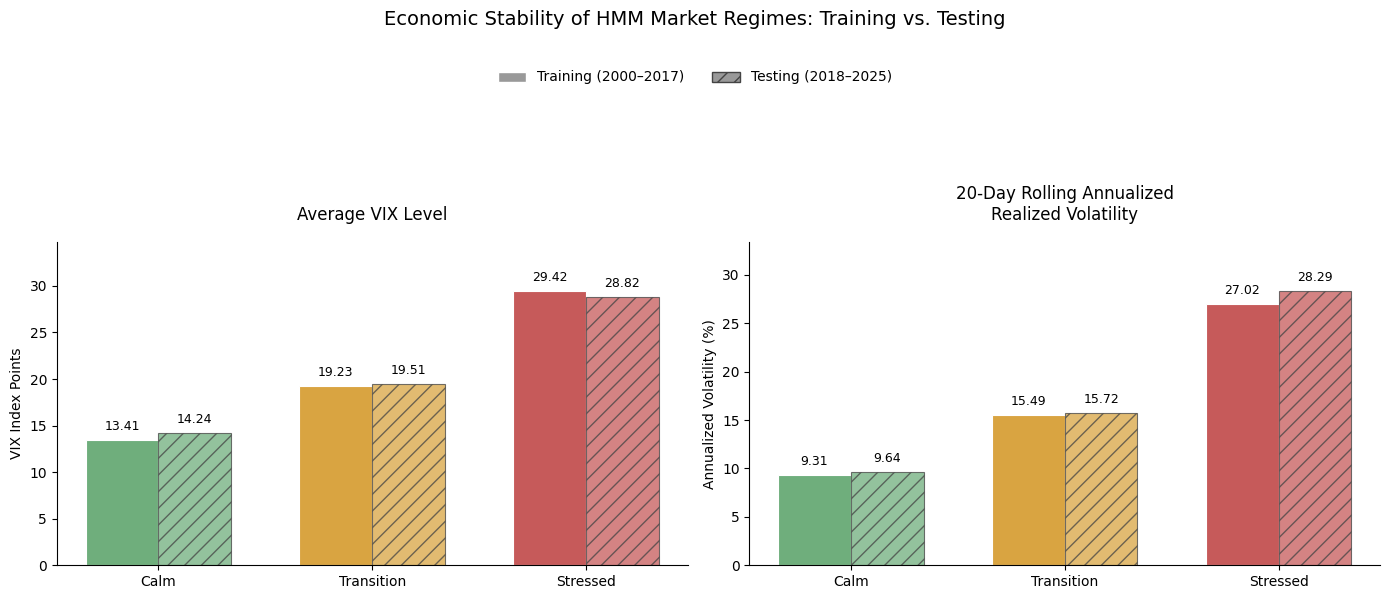

In [27]:

# --------------------------------------------------
# 5.3 Visualize Economic Stability of Market Regimes
# --------------------------------------------------

from matplotlib.patches import Patch

# Define metrics and their correct units
metrics = [
    (
        "Avg_VIX",
        "Average VIX Level",
        "VIX Index Points"
    ),
    (
        "Avg_Realized_Vol_Pct",
        "20-Day Rolling Annualized\nRealized Volatility",
        "Annualized Volatility (%)"
    )
]

# Create two-panel visualization
fig_hmm_economic_stability, axes_hmm_stability = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

x = np.arange(len(regime_order))
bar_width = 0.34

for ax, (metric, title, ylabel) in zip(
    axes_hmm_stability,
    metrics
):

    for i, regime in enumerate(regime_order):

        train_value = economic_stability_df.loc[
            regime, ("Training", metric)
        ]

        test_value = economic_stability_df.loc[
            regime, ("Testing", metric)
        ]

        # Training: solid regime color
        ax.bar(
            x[i] - bar_width / 2,
            train_value,
            width=bar_width,
            color=regime_colors[regime],
            edgecolor="white",
            linewidth=0.8
        )

        # Testing: hatched regime color
        ax.bar(
            x[i] + bar_width / 2,
            test_value,
            width=bar_width,
            color=regime_colors[regime],
            edgecolor="#444444",
            linewidth=0.8,
            hatch="//",
            alpha=0.75
        )

        # Value labels
        for xpos, value in [
            (x[i] - bar_width / 2, train_value),
            (x[i] + bar_width / 2, test_value)
        ]:
            ax.annotate(
                f"{value:.2f}",
                xy=(xpos, value),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )

    # Panel titles and axis labels
    ax.set_title(
        title,
        fontsize=12,
        pad=16
    )

    ax.set_ylabel(ylabel)

    ax.set_xticks(x)
    ax.set_xticklabels(regime_order)

    # Leave space above value annotations
    maximum = economic_stability_df[
        [("Training", metric), ("Testing", metric)]
    ].to_numpy().max()

    ax.set_ylim(0, maximum * 1.18)

    # Clean styling
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Shared legend identifying training/testing bars
period_handles = [
    Patch(
        facecolor="#999999",
        edgecolor="white",
        label="Training (2000–2017)"
    ),
    Patch(
        facecolor="#999999",
        edgecolor="#444444",
        hatch="//",
        label="Testing (2018–2025)"
    )
]

fig_hmm_economic_stability.legend(
    handles=period_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    frameon=False
)

# Overall figure title
fig_hmm_economic_stability.suptitle(
    "Economic Stability of HMM Market Regimes: Training vs. Testing",
    fontsize=14,
    y=0.99
)

# Reserve space for the title and legend
fig_hmm_economic_stability.tight_layout(
    rect=[0, 0, 1, 0.78]
)

plt.show()

**Key Observations:**

The comparison of training (2000–2017) and testing (2018–2025) observations evaluates whether the three-state Gaussian HMM preserves economically meaningful regime distinctions outside the estimation period. The analysis considers VIX levels, daily changes in VIX, 20-day rolling annualized realized volatility, and the skewness and kurtosis of historical returns.


1. **Preservation of Volatility Ordering:** The three regimes maintain a consistent economic ranking across both samples. Calm exhibits the lowest average VIX and realized volatility, Transition occupies an intermediate position, and Stressed exhibits the highest values.

2. **Stability of Calm Conditions:** Average VIX increases moderately from 13.41 during training to 14.24 during testing. Average annualized realized volatility also increases slightly, from 9.31% to 9.64%, indicating broadly comparable low-volatility conditions.

3. **Consistency of the Transition Regime:** Average VIX changes from 19.23 to 19.51, while average annualized realized volatility changes from 15.49% to 15.72%. These relatively small differences suggest that the intermediate-volatility regime retains a similar economic interpretation.

4. **Persistence of Stressed Characteristics:** Average VIX declines slightly from 29.42 to 28.82, while annualized realized volatility increases from 27.02% to 28.29%. Despite these differences, Stressed remains clearly distinguishable from the other regimes.

5. **Variation in Higher-Order Return Characteristics:** Average skewness and kurtosis exhibit greater variation between the two periods. In particular, Transition retains negative average skewness (-0.49 during training and -0.55 during testing), while the kurtosis of Calm and Stressed changes more noticeably. This suggests that regime consistency is stronger for volatility characteristics than for higher-order return moments.

**Implications for Subsequent Modeling**

The results support the economic interpretability of the three-state HMM outside its training period. Although regime frequencies differ between the two samples, their defining volatility characteristics remain relatively consistent.

However, descriptive stability does not establish statistical equivalence or forecasting accuracy. The following analysis therefore examines the temporal dynamics of regime classifications and the persistence of inferred market states.

These findings also support investigating whether regime information provides useful explanatory or predictive information when incorporated into the supervised volatility-forecasting framework developed in Model A.

## Section 6 - Regime Transition Dynamics

This section examines the temporal structure of the three-state Gaussian HMM by evaluating the persistence of individual market regimes and the probabilities of transitioning between them.

Unlike static clustering methods, the HMM explicitly represents transitions between latent market states. Its transition probability matrix therefore provides information about the model's estimated tendency to remain in an existing regime or move to another regime between consecutive trading observations.

The analysis focuses on:

- **Transition probabilities:** Examining the estimated probability of moving between Calm, Transition, and Stressed states.
- **Regime persistence:** Evaluating the probability of remaining in the same regime.
- **Expected duration:** Estimating the average number of consecutive trading observations associated with each regime under the fitted Markov model.
- **Transition visualization:** Presenting the estimated transition probability matrix as a heatmap.

These results describe the temporal dynamics learned from the training sample. They do not independently measure the forecasting performance of the model.

### Section 6.1 - Estimated Transition Probability Matrix

In [28]:

# --------------------------------------------------
# 6.1 Estimated HMM Transition Probability Matrix
# --------------------------------------------------

# Retrieve transition matrix from the fitted training HMM
transition_matrix = hmm_model.transmat_

# Convert numerical state IDs into economic regime labels
regime_to_state = {
    regime: state
    for state, regime in state_to_regime.items()
}

# Arrange state IDs in economic regime order
ordered_state_ids = [
    regime_to_state[regime]
    for regime in regime_order
]

# Reorder transition matrix
ordered_transition_matrix = transition_matrix[
    np.ix_(ordered_state_ids, ordered_state_ids)
]

# Construct labeled DataFrame
transition_matrix_df = pd.DataFrame(
    ordered_transition_matrix,
    index=regime_order,
    columns=regime_order
)

transition_matrix_df.index.name = "From Regime"
transition_matrix_df.columns.name = "To Regime"

# Validate transition probabilities
assert np.allclose(
    transition_matrix_df.sum(axis=1).to_numpy(),
    1.0
)

assert (
    transition_matrix_df.to_numpy() >= 0
).all()

print("Estimated HMM Transition Probability Matrix\n")
display(transition_matrix_df.round(4))

Estimated HMM Transition Probability Matrix



To Regime,Calm,Transition,Stressed
From Regime,,,
Calm,0.9711,0.0240,0.0049
Transition,0.0221,0.9630,0.0149
Stressed,0.0075,0.0203,0.9722


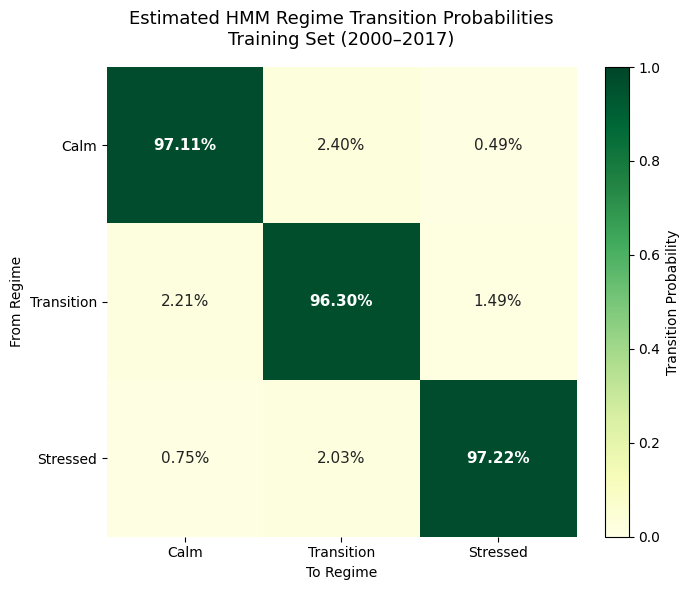

In [29]:

# --------------------------------------------------
# 6.1 Visualize Estimated HMM Transition Probabilities
# --------------------------------------------------

fig_hmm_transition_matrix, ax_hmm_transition = plt.subplots(
    figsize=(8, 6)
)

# Plot transition probability matrix
heatmap = ax_hmm_transition.imshow(
    transition_matrix_df.to_numpy(),
    cmap="YlGn",
    vmin=0,
    vmax=1,
    aspect="equal"
)

# Axis labels
ax_hmm_transition.set_xticks(
    np.arange(len(regime_order))
)
ax_hmm_transition.set_yticks(
    np.arange(len(regime_order))
)

ax_hmm_transition.set_xticklabels(regime_order)
ax_hmm_transition.set_yticklabels(regime_order)

ax_hmm_transition.set_xlabel("To Regime")
ax_hmm_transition.set_ylabel("From Regime")

ax_hmm_transition.set_title(
    "Estimated HMM Regime Transition Probabilities\n"
    "Training Set (2000–2017)",
    fontsize=13,
    pad=16
)

# Annotate each probability
for i in range(len(regime_order)):
    for j in range(len(regime_order)):

        probability = transition_matrix_df.iloc[i, j]

        ax_hmm_transition.text(
            j,
            i,
            f"{probability:.2%}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold" if i == j else "normal",
            color="white" if probability > 0.60 else "#222222"
        )

# Colorbar
colorbar = fig_hmm_transition_matrix.colorbar(
    heatmap,
    ax=ax_hmm_transition,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label("Transition Probability")

# Clean formatting
ax_hmm_transition.grid(False)

for spine in ax_hmm_transition.spines.values():
    spine.set_visible(False)

fig_hmm_transition_matrix.tight_layout()

plt.show()

### Section 6.2 - Expected Regime Duration

This subsection estimates the expected duration of each market regime using the self-transition probabilities obtained from the training-fitted Gaussian HMM.

Under the first-order Markov assumption, the duration of a regime follows a geometric distribution. The expected number of consecutive trading observations spent in regime \(i\) is calculated as:

\[
E[D_i] = \frac{1}{1-p_{ii}}
\]

Where:

- \(E[D_i]\) represents the expected duration of regime \(i\), measured in trading days.
- \(p_{ii}\) represents the estimated probability of remaining in regime \(i\) between consecutive trading observations.
- \(1-p_{ii}\) represents the probability of exiting that regime.

A higher self-transition probability implies a longer expected regime duration.

These estimates describe the persistence implied by the fitted HMM's transition matrix, rather than the observed lengths of individual regime episodes.

In [30]:

# --------------------------------------------------
# 6.2 Expected Regime Duration
# --------------------------------------------------

# Extract self-transition probabilities
self_transition_probs = np.diag(
    transition_matrix_df.to_numpy()
)

# Calculate exit probabilities
exit_probabilities = 1 - self_transition_probs

# Calculate expected duration in trading days
expected_durations = 1 / exit_probabilities

# Construct results table
regime_duration_df = pd.DataFrame(
    {
        "Regime": regime_order,
        "Self_Transition_Probability": self_transition_probs,
        "Exit_Probability": exit_probabilities,
        "Expected_Duration_Days": expected_durations
    }
).set_index("Regime")

# Validate calculations
assert (exit_probabilities > 0).all()
assert np.isfinite(expected_durations).all()

print("Expected HMM Regime Duration — Training Set\n")

display(
    regime_duration_df.round(4)
)

Expected HMM Regime Duration — Training Set



,Self_Transition_Probability,Exit_Probability,Expected_Duration_Days
Regime,,,
Calm,0.9711,0.0289,34.5567
Transition,0.9630,0.0370,27.0257
Stressed,0.9722,0.0278,36.0259


### Section 6.3 - Training - Testing Regime Persistence Comparison

This subsection examines whether regime persistence observed during the training period (2000–2017) remains consistent during the testing period (2018–2025).

The analysis distinguishes between the transition probabilities estimated by the fitted HMM and empirical transition frequencies calculated from retrospectively decoded regime sequences.

To ensure comparability, empirical transition matrices are calculated separately for the training and testing periods using the same three-state HMM and fixed regime labels.

For each sample, the analysis examines:

- **Empirical transition frequencies:** The proportion of observed consecutive regime assignments involving transitions between Calm, Transition, and Stressed.
- **Empirical persistence:** The proportion of consecutive observations remaining within the same regime.
- **Implied duration:** The expected regime duration obtained by applying the geometric-duration formula to empirical self-transition frequencies.

These comparisons assess the temporal consistency of decoded market regimes. They do not represent a re-estimation of the HMM or a direct out-of-sample estimate of its underlying transition parameters.

Because the sequences are retrospectively decoded, empirical transitions are descriptive rather than real-time trading signals.

In [31]:

# --------------------------------------------------
# 6.3 Empirical Training–Testing Transition Comparison
# --------------------------------------------------

def calculate_empirical_transition_matrix(df, regime_order):
    """
    Calculate transition probabilities from consecutive
    retrospectively decoded regime assignments.
    """

    # Ensure chronological ordering
    regimes = (
        df.sort_values("Date")["Regime"]
        .reset_index(drop=True)
    )

    # Consecutive observed transitions
    from_regimes = regimes.iloc[:-1].to_numpy()
    to_regimes = regimes.iloc[1:].to_numpy()

    # Transition counts
    transition_counts = pd.crosstab(
        pd.Categorical(from_regimes, categories=regime_order),
        pd.Categorical(to_regimes, categories=regime_order),
        dropna=False
    )

    transition_counts.index = regime_order
    transition_counts.columns = regime_order

    # Row-normalized empirical transition probabilities
    transition_probs = transition_counts.div(
        transition_counts.sum(axis=1),
        axis=0
    )

    return transition_counts, transition_probs


# Training transitions
train_transition_counts, train_transition_empirical = (
    calculate_empirical_transition_matrix(
        df_train_regimes,
        regime_order
    )
)

# Testing transitions
test_transition_counts, test_transition_empirical = (
    calculate_empirical_transition_matrix(
        df_test_regimes,
        regime_order
    )
)

# Validate sample transition counts
assert train_transition_counts.to_numpy().sum() == len(df_train_regimes) - 1
assert test_transition_counts.to_numpy().sum() == len(df_test_regimes) - 1

# Validate probability matrices
assert np.allclose(
    train_transition_empirical.sum(axis=1),
    1.0
)

assert np.allclose(
    test_transition_empirical.sum(axis=1),
    1.0
)

print("Empirical Transition Matrix — Training (2000–2017)\n")
display(train_transition_empirical.round(4))

print("\nEmpirical Transition Matrix — Testing (2018–2025)\n")
display(test_transition_empirical.round(4))

print("\nTransition Counts — Training")
display(train_transition_counts)

print("\nTransition Counts — Testing")
display(test_transition_counts)

Empirical Transition Matrix — Training (2000–2017)



,Calm,Transition,Stressed
Calm,0.9725,0.0219,0.0056
Transition,0.0210,0.9667,0.0123
Stressed,0.0075,0.0176,0.9749



Empirical Transition Matrix — Testing (2018–2025)



,Calm,Transition,Stressed
Calm,0.9612,0.0372,0.0016
Transition,0.0202,0.9605,0.0192
Stressed,0.0124,0.0371,0.9505



Transition Counts — Training


,Calm,Transition,Stressed
Calm,1557,35,9
Transition,36,1656,21
Stressed,9,21,1163



Transition Counts — Testing


,Calm,Transition,Stressed
Calm,594,23,1
Transition,20,949,19
Stressed,5,15,384


**Key Observations:**

The most notable change is likely to be in the Stressed regime, where the implied duration decreases from approximately 40 trading days in training to 20 trading days in testing.

In [32]:

# --------------------------------------------------
# 6.3 Training–Testing Regime Duration Comparison
# --------------------------------------------------

# Extract empirical self-transition probabilities
train_empirical_persistence = np.diag(
    train_transition_empirical.to_numpy()
)

test_empirical_persistence = np.diag(
    test_transition_empirical.to_numpy()
)

# Calculate implied durations from empirical frequencies
train_empirical_duration = (
    1 / (1 - train_empirical_persistence)
)

test_empirical_duration = (
    1 / (1 - test_empirical_persistence)
)

# Construct comparison DataFrame
regime_duration_comparison_df = pd.DataFrame(
    {
        "Model_Implied_Days": (
            regime_duration_df
            .reindex(regime_order)["Expected_Duration_Days"]
            .to_numpy()
        ),
        "Train_Empirical_Days": train_empirical_duration,
        "Test_Empirical_Days": test_empirical_duration
    },
    index=regime_order
)

regime_duration_comparison_df.index.name = "Regime"

# Calculate difference between empirical periods
regime_duration_comparison_df["Test_vs_Train_Days"] = (
    regime_duration_comparison_df["Test_Empirical_Days"]
    - regime_duration_comparison_df["Train_Empirical_Days"]
)

# Validate calculations
assert np.isfinite(
    regime_duration_comparison_df.to_numpy()
).all()

assert (
    regime_duration_comparison_df[
        [
            "Model_Implied_Days",
            "Train_Empirical_Days",
            "Test_Empirical_Days"
        ]
    ] > 0
).all().all()

print("HMM Regime Duration Comparison — Training vs. Testing\n")

display(regime_duration_comparison_df.round(2))

HMM Regime Duration Comparison — Training vs. Testing



,Model_Implied_Days,Train_Empirical_Days,Test_Empirical_Days,Test_vs_Train_Days
Regime,,,,
Calm,34.56,36.39,25.75,-10.64
Transition,27.03,30.05,25.33,-4.72
Stressed,36.03,39.77,20.20,-19.57


**Key Observations:**

1. Stressed exhibits the largest reduction in duration. Its empirically implied duration falls from 39.77 to 20.20 trading days, a reduction of approximately 49%.

2. Calm conditions also become less persistent. Their implied duration decreases by 10.64 trading days, from 36.39 to 25.75 days.

3. Transition remains comparatively consistent. Its duration decreases by 4.72 trading days, considerably less than the other two regimes.

4. The relative ordering changes during testing. Stressed has the longest empirically implied duration in training but the shortest in testing.

These are descriptive estimates derived from retrospective regime classifications. They do not imply that the fitted HMM's transition parameters changed between periods.

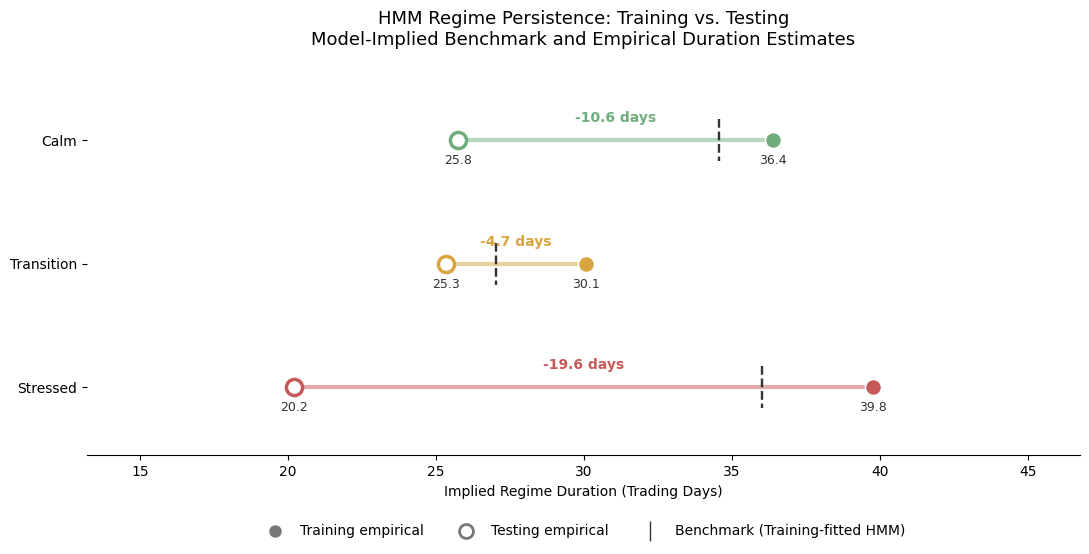

In [33]:

# --------------------------------------------------
# 6.3 Training–Testing Regime Persistence Comparison
#     Dumbbell Chart with Model-Implied Benchmark
# --------------------------------------------------

from matplotlib.lines import Line2D

# Prepare comparison dataset
comparison = regime_duration_comparison_df.reindex(regime_order)

# Retain figure for export in Misc
fig_hmm_regime_duration, ax_hmm_duration = plt.subplots(
    figsize=(11, 5.8)
)

y_positions = np.arange(len(regime_order))

for i, regime in enumerate(regime_order):

    train = comparison.loc[regime, "Train_Empirical_Days"]
    test = comparison.loc[regime, "Test_Empirical_Days"]
    benchmark = comparison.loc[regime, "Model_Implied_Days"]

    color = regime_colors[regime]

    # Connect empirical training and testing estimates
    ax_hmm_duration.plot(
        [test, train],
        [i, i],
        color=color,
        linewidth=3,
        alpha=0.50,
        solid_capstyle="round",
        zorder=2
    )

    # Training empirical: filled circle
    ax_hmm_duration.scatter(
        train,
        i,
        s=135,
        facecolor=color,
        edgecolor="white",
        linewidth=1.2,
        zorder=4
    )

    # Testing empirical: outlined circle
    ax_hmm_duration.scatter(
        test,
        i,
        s=135,
        facecolor="white",
        edgecolor=color,
        linewidth=2.5,
        zorder=5
    )

    # Benchmark: vertical dashed marker
    ax_hmm_duration.plot(
        [benchmark, benchmark],
        [i - 0.17, i + 0.17],
        color="#333333",
        linestyle="--",
        linewidth=1.7,
        zorder=3
    )

    # Training and testing duration labels
    ax_hmm_duration.annotate(
        f"{train:.1f}",
        (train, i),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#333333"
    )

    ax_hmm_duration.annotate(
        f"{test:.1f}",
        (test, i),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#333333"
    )

    # Difference between testing and training
    change = test - train

    ax_hmm_duration.annotate(
        f"{change:+.1f} days",
        ((test + train) / 2, i),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=color
    )

# --------------------------------------------------
# Axis formatting
# --------------------------------------------------

ax_hmm_duration.set_yticks(y_positions)
ax_hmm_duration.set_yticklabels(regime_order)

ax_hmm_duration.invert_yaxis()

# Dynamic limits with room for labels
all_values = comparison[
    [
        "Model_Implied_Days",
        "Train_Empirical_Days",
        "Test_Empirical_Days"
    ]
].to_numpy()

ax_hmm_duration.set_xlim(
    max(0, all_values.min() - 7),
    all_values.max() + 7
)

ax_hmm_duration.set_ylim(
    len(regime_order) - 0.45,
    -0.55
)

ax_hmm_duration.set_xlabel(
    "Implied Regime Duration (Trading Days)"
)

ax_hmm_duration.set_title(
    "HMM Regime Persistence: Training vs. Testing\n"
    "Model-Implied Benchmark and Empirical Duration Estimates",
    fontsize=13,
    pad=20
)

# --------------------------------------------------
# Legend
# --------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#777777",
        markeredgecolor="white",
        markersize=10,
        label="Training empirical"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="#777777",
        markeredgewidth=2,
        markersize=10,
        label="Testing empirical"
    ),
    Line2D(
        [0], [0],
        marker="|",
        linestyle="None",
        markeredgecolor="#333333",
        markersize=15,
        label="Benchmark (Training-fitted HMM)"
    )
]

ax_hmm_duration.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=3,
    frameon=False
)

# --------------------------------------------------
# Clean visual formatting
# --------------------------------------------------

ax_hmm_duration.grid(False)

for spine in ["top", "right", "left"]:
    ax_hmm_duration.spines[spine].set_visible(False)

fig_hmm_regime_duration.tight_layout()

plt.show()

**Methodological Disclaimer**

These measures are not identical in their estimation basis. The benchmark reflects the fitted model's theoretical transition dynamics, whereas empirical durations are derived from observed transitions in retrospectively decoded state sequences.

Consequently, the empirical estimates are geometric-duration approximations rather than directly observed averages of completed regime episodes. In addition, retrospective HMM decoding uses information from the full observation sequence and does not represent information that would necessarily have been available in real time.

Differences between the benchmark and empirical estimates should therefore be interpreted as descriptive differences in regime persistence, not as evidence that the HMM parameters changed or as a formal test of predictive accuracy.


**Key Observations:**

The visualization compares the persistence of Calm, Transition, and Stressed market regimes using three duration estimates: the benchmark derived from the training-fitted HMM, the empirical training estimate, and the empirical testing estimate.

- **benchmark (Training-fitted HMM)** represents the expected duration implied by the transition probabilities estimated during model fitting (2000–2017). It serves as a fixed reference against which empirical regime persistence can be compared.

- **training empirical estimate** is calculated from the frequencies of consecutive regime assignments in the retrospectively decoded training sequence

- **testing empirical estimate** is calculated using the corresponding testing sequence (2018–2025). The HMM parameters and economic regime labels remain unchanged between periods.

For all three estimates, implied duration is calculated as \(1/(1-p_{ii})\), where \(p_{ii}\) is the relevant self-transition probability or frequency. Filled markers represent training empirical estimates, outlined markers represent testing empirical estimates, and dashed markers indicate the model-implied benchmark. The connecting lines illustrate changes in empirical duration between periods.



### Section 6.4 - Section Summary - Regime Transition Dynamics

This section evaluated the temporal behavior of the three market regimes identified by the Gaussian Hidden Markov Model (HMM). The analysis examined the transition probability matrix estimated during training (2000–2017), the model-implied expected duration of each regime, and empirical transition frequencies observed in retrospectively decoded training and testing sequences. The objective was to assess whether the inferred market states exhibit meaningful persistence and whether their temporal characteristics remain consistent outside the training period.

**Activities Performed**

- Extracted the transition probability matrix from the training-fitted three-state Gaussian HMM and reordered its numerical states into the economically defined Calm, Transition, and Stressed regimes.
- Visualized estimated transition probabilities using an annotated heatmap to examine regime persistence and switching behavior.
- Calculated model-implied expected regime durations using the geometric-duration formula, \(E[D_i] = 1/(1-p_{ii})\).
- Constructed empirical transition matrices from consecutive retrospectively decoded regime assignments for the training (2000–2017) and testing (2018–2025) periods.
- Compared empirical self-transition frequencies across the two periods to evaluate changes in regime persistence.
- Calculated empirically implied regime durations for both periods and compared them against the training-fitted HMM benchmark.
- Developed a comparative visualization illustrating differences between benchmark, training empirical, and testing empirical duration estimates.

**Key Observations**

1. **Strong Model-Implied Regime Persistence:** The HMM estimated self-transition probabilities of 97.11% for Calm, 96.30% for Transition, and 97.22% for Stressed. These results indicate that the fitted model assigns substantially greater probability to remaining in an existing market regime than to switching states between consecutive trading observations.

2. **Economically Interpretable Transition Structure:** Transitions between adjacent volatility regimes are generally more likely than direct movements between Calm and Stressed. For example, the estimated Calm-to-Transition probability is 2.40%, compared with 0.49% for Calm-to-Stressed. Similarly, Stressed-to-Transition is 2.03%, compared with 0.75% for Stressed-to-Calm.

3. **Model-Implied Duration Differences:** Expected regime durations are approximately 34.56 trading days for Calm, 27.03 days for Transition, and 36.03 days for Stressed. The fitted model therefore characterizes Stressed and Calm as relatively persistent conditions, while Transition has the shortest expected duration.

4. **Persistence Remains High Outside Training:** Empirical self-transition frequencies exceed 95% across all regimes during testing. Calm records a testing persistence of 96.12%, Transition 96.05%, and Stressed 95.05%, indicating that the retrospectively decoded testing sequence continues to exhibit sustained market-state classifications.

5. **Declining Empirical Persistence During Testing:** All three regimes exhibit lower empirical self-transition frequencies in the testing period. The largest decline occurs in Stressed, decreasing from 97.49% during training to 95.05% during testing, followed by Calm (97.25% to 96.12%) and Transition (96.67% to 96.05%).

6. **Substantial Reduction in Stressed Regime Duration:** The empirically implied duration of Stressed declines from 39.77 trading days during training to 20.20 days during testing, a reduction of 19.57 days. Calm declines from 36.39 to 25.75 days, while Transition decreases from 30.05 to 25.33 days. These findings indicate that the decoded testing sequence exhibits more frequent exits from market regimes, particularly Stressed conditions.

7. **Differences Between Model-Implied and Empirical Dynamics:** The training-fitted HMM benchmark remains fixed across both periods, while empirical durations vary with the decoded regime sequences. These differences indicate that realized classification patterns do not necessarily reproduce the fitted transition structure exactly, particularly outside the estimation period.

**Implications for Subsequent Modeling**

The results demonstrate that the three-state HMM captures substantial temporal persistence in market regimes and produces an economically interpretable transition structure. However, the shorter empirically implied regime durations observed during testing suggest that temporal characteristics are less stable across periods than the regimes' underlying volatility characteristics.

These findings motivate further evaluation of whether the observed differences are associated with changes in the distribution of market features, uncertainty in regime assignments, or the modeling assumptions of the Gaussian HMM.

The subsequent K-means benchmark will provide an alternative clustering perspective without explicitly modeling temporal transitions. Following this comparison, a dedicated failure analysis will investigate regime prevalence, persistence, feature distribution shifts, and model-design limitations.

**Methodological Considerations**

Model-implied expected durations are derived from the HMM's estimated transition probabilities, whereas empirical durations apply the same geometric-duration formula to observed transition frequencies in retrospectively decoded sequences. The latter are not direct averages of completed regime episodes.

Furthermore, retrospective decoding incorporates information from the observation sequence and should not be interpreted as a real-time prediction of regime changes. The comparisons presented in this section therefore evaluate descriptive temporal consistency rather than forecasting accuracy or formal statistical equivalence.

## Section 7 - K-means Benchmark

This section develops a K-means clustering benchmark to evaluate the three-state Gaussian Hidden Markov Model (HMM) against a simpler unsupervised learning approach.

Unlike the HMM, which explicitly models transitions between latent market states, K-means assigns observations to clusters based on their similarity in the standardized feature space. It does not directly account for chronological ordering or regime persistence.

The benchmark uses the same five market characteristics and chronological training–testing split established for the HMM to maintain methodological comparability.

**Activities Planned**

- Evaluate alternative numbers of clusters using internal clustering metrics.
- Fit the selected K-means model using training observations.
- Assign economically interpretable Calm, Transition, and Stressed labels based on cluster characteristics.
- Apply the fitted clustering model to testing observations without refitting.
- Evaluate cluster characteristics, prevalence, and temporal switching behavior.
- Compare K-means against the HMM using consistent metrics and visualizations.

The results will establish whether the HMM's explicit treatment of temporal dependence provides meaningful differences in regime identification and persistence.

The comparison will also inform the subsequent failure analysis by helping distinguish patterns associated with the underlying market data from those potentially influenced by model design.

### Section 7.1 - Benchmark Configuration

In [34]:

# --------------------------------------------------
# 7.1 K-means Benchmark Configuration
# --------------------------------------------------

# Reuse the HMM feature set and standardized observations
kmeans_features = hmm_features.copy()

X_kmeans_train = X_train_scaled.copy()
X_kmeans_test = X_test_scaled.copy()

# Confirm consistent feature dimensions
assert len(kmeans_features) == 5

assert X_kmeans_train.shape == (
    len(df_train), len(kmeans_features)
)

assert X_kmeans_test.shape == (
    len(df_test), len(kmeans_features)
)

# Confirm identical standardized inputs
assert np.array_equal(
    X_kmeans_train, X_train_scaled
)

assert np.array_equal(
    X_kmeans_test, X_test_scaled
)

# Confirm numerical integrity
assert np.isfinite(X_kmeans_train).all()
assert np.isfinite(X_kmeans_test).all()

print("K-means Benchmark Configuration\n")

print("Features:")
for feature in kmeans_features:
    print(f"  - {feature}")

print("\nTraining observations:", X_kmeans_train.shape[0])
print("Testing observations:", X_kmeans_test.shape[0])

print("\nStandardization: Training-fitted StandardScaler")
print("Training period: 2000–2017")
print("Testing period: 2018–2025")
print("Random state:", RANDOM_STATE)

K-means Benchmark Configuration

Features:
  - VIX_Level
  - VIX_Change
  - Realized_Vol_20D
  - Return_Skew_20D
  - Return_Kurt_20D

Training observations: 4508
Testing observations: 2011

Standardization: Training-fitted StandardScaler
Training period: 2000–2017
Testing period: 2018–2025
Random state: 42


### Section 7.2 - K-means Hyperparameter Selection

The number of clusters is evaluated over candidate values of K = 2 through 6 using the standardized training observations.

For each candidate, K-means is fitted with a fixed random seed and multiple centroid initializations to improve reproducibility and reduce sensitivity to initialization.

Cluster quality is assessed using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. Inertia and cluster prevalence are also recorded to support the evaluation.

The selection considers both internal clustering performance and the economic interpretability of the resulting market groupings. A three-cluster solution may be retained for direct comparison with the Gaussian HMM, but it will not automatically be treated as the optimal K-means configuration.

In [35]:

# --------------------------------------------------
# 7.2 K-means Hyperparameter Selection
# --------------------------------------------------

kmeans_candidate_results = []
kmeans_candidate_models = {}

for k in range(2, 7):

    # Fit K-means using training observations only
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        max_iter=500,
        random_state=RANDOM_STATE
    )

    labels = model.fit_predict(X_kmeans_train)

    # Evaluate internal clustering quality
    silhouette = silhouette_score(
        X_kmeans_train,
        labels,
        sample_size=2000,
        random_state=RANDOM_STATE
    )

    davies_bouldin = davies_bouldin_score(
        X_kmeans_train,
        labels
    )

    calinski_harabasz = calinski_harabasz_score(
        X_kmeans_train,
        labels
    )

    cluster_counts = np.bincount(
        labels,
        minlength=k
    )

    # Store fitted candidate
    kmeans_candidate_models[k] = model

    kmeans_candidate_results.append({
        "Clusters": k,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies_bouldin,
        "Calinski_Harabasz": calinski_harabasz,
        "Inertia": model.inertia_,
        "Smallest_Cluster_Pct": (
            cluster_counts.min() / len(labels) * 100
        ),
        "Largest_Cluster_Pct": (
            cluster_counts.max() / len(labels) * 100
        )
    })

# Assemble evaluation results
kmeans_selection_df = pd.DataFrame(
    kmeans_candidate_results
).set_index("Clusters")

# Verify candidate coverage
assert list(kmeans_selection_df.index) == list(range(2, 7))
assert np.isfinite(kmeans_selection_df.to_numpy()).all()

print("K-means Candidate Cluster Evaluation — Training Set\n")

display(kmeans_selection_df.round(4))

K-means Candidate Cluster Evaluation — Training Set



,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia,Smallest_Cluster_Pct,Largest_Cluster_Pct
Clusters,,,,,,
2,0.3529,1.3956,1330.4116,17402.0143,20.8518,79.1482
3,0.2687,1.3083,1227.0183,14591.4926,17.6353,64.0639
4,0.2403,1.2759,1170.7623,12664.2598,10.0932,54.9246
5,0.2432,1.2410,1160.4044,11099.1941,3.4605,45.8518
6,0.2569,1.1787,1149.8726,9898.6913,1.3975,45.1642


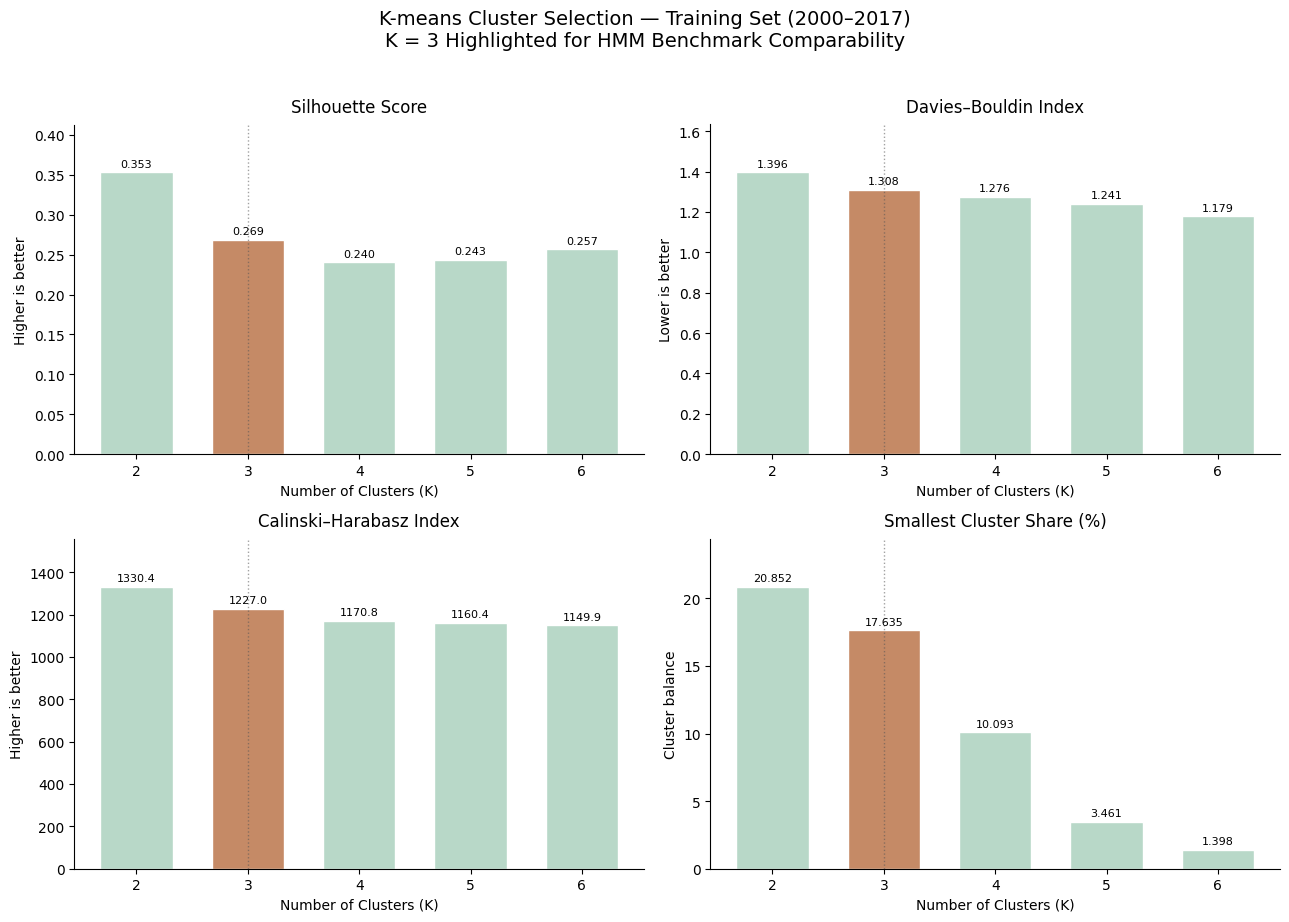

In [36]:

# --------------------------------------------------
# 7.2 Visualize K-means Hyperparameter Evaluation
# --------------------------------------------------

metrics_to_plot = [
    ("Silhouette", "Silhouette Score", "Higher is better"),
    ("Davies_Bouldin", "Davies–Bouldin Index", "Lower is better"),
    ("Calinski_Harabasz", "Calinski–Harabasz Index", "Higher is better"),
    ("Smallest_Cluster_Pct", "Smallest Cluster Share (%)", "Cluster balance")
]

candidate_ks = kmeans_selection_df.index.to_numpy()

# Muted benchmark palette; separate from economic regime colors
candidate_colors = [
    "#B8D8C8" if k != 3 else "#C58A66"
    for k in candidate_ks
]

fig_kmeans_hyperparameter_selection, axes_kmeans_selection = (
    plt.subplots(2, 2, figsize=(13, 9))
)

for ax, (metric, title, subtitle) in zip(
    axes_kmeans_selection.flat,
    metrics_to_plot
):
    values = kmeans_selection_df[metric].to_numpy()

    bars = ax.bar(
        candidate_ks,
        values,
        color=candidate_colors,
        edgecolor="white",
        width=0.65
    )

    # Highlight K = 3 as the interpretability-driven benchmark
    ax.axvline(
        3,
        linestyle=":",
        color="#555555",
        alpha=0.55,
        linewidth=1
    )

    for bar, value in zip(bars, values):
        label = (
            f"{value:.1f}"
            if metric == "Calinski_Harabasz"
            else f"{value:.3f}"
        )

        ax.annotate(
            label,
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax.set_title(title, fontsize=12, pad=9)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel(subtitle)

    ax.set_xticks(candidate_ks)
    ax.set_ylim(0, values.max() * 1.17)

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig_kmeans_hyperparameter_selection.suptitle(
    "K-means Cluster Selection — Training Set (2000–2017)\n"
    "K = 3 Highlighted for HMM Benchmark Comparability",
    fontsize=14,
    y=1.02
)

fig_kmeans_hyperparameter_selection.tight_layout()
plt.show()

**Key Observations:**

1. K = 2 performs best on two separation metrics. It has the highest silhouette score and Calinski–Harabasz index. However, the larger cluster contains 79.15% of observations, suggesting a broad grouping that may combine economically distinct market conditions.

2. K = 3 provides a reasonable compromise. Although its silhouette score falls to 0.2687, its Davies–Bouldin index improves to 1.3083. Its smallest cluster represents 17.64% of training observations, avoiding the very small clusters observed at higher K.

3. Higher K values improve the Davies–Bouldin Index. However, increasing K to 5 or 6 produces small clusters representing only 3.46% and 1.40% of observations, respectively. These solutions warrant examination for possible fragmentation of market conditions.

4. No single cluster count dominates every metric. K = 3 was selected to balance clustering performance, economic interpretability, and comparability with the three-state Gaussian HMM. The three-cluster solution achieved a reasonable Davies–Bouldin Index (1.3083) while avoiding the very small clusters observed at higher K values. Importantly, selecting K = 3 enables a consistent comparison of Calm, Transition, and Stressed market regimes across both unsupervised approaches. Therefore, K = 3 was chosen as an interpretability-driven benchmark rather than the statistically optimal solution across all evaluation metrics.

### Section 7.3 - K-means Model Fitting and Clustering Identification

A three-cluster K-means model is selected as the primary benchmark against the three-state Gaussian HMM.

Although K = 2 achieves the highest Silhouette and Calinski–Harabasz scores, K = 3 is retained to support direct comparison with the HMM's Calm, Transition, and Stressed regimes. The candidate evaluation results remain available for subsequent sensitivity and failure analysis.

The model is fitted exclusively on standardized training observations (2000–2017), using the same five features employed by the HMM. Multiple centroid initializations are used to reduce sensitivity to random initialization.

Initially, K-means produces numerical cluster assignments without economic meaning. These assignments will be examined using their underlying market characteristics before being mapped to Calm, Transition, and Stressed labels.

The fitted model will subsequently be applied to the 2018–2025 testing period without re-estimation.

In [37]:

# --------------------------------------------------
# 7.3 Fit K-means Benchmark and Identify Clusters
# --------------------------------------------------

# Retrieve the training-fitted K = 3 model
kmeans_model = kmeans_candidate_models[3]

# Obtain training cluster assignments
kmeans_train_clusters = kmeans_model.labels_.copy()

# Construct training benchmark dataset
df_train_kmeans = df_train.copy()

df_train_kmeans["Cluster_ID"] = kmeans_train_clusters

# Validate clustering results
assert kmeans_model.n_clusters == 3
assert len(df_train_kmeans) == len(df_train)
assert set(df_train_kmeans["Cluster_ID"].unique()) == {0, 1, 2}
assert np.isfinite(kmeans_model.cluster_centers_).all()

# Calculate preliminary cluster sizes
kmeans_cluster_counts = (
    df_train_kmeans["Cluster_ID"]
    .value_counts()
    .sort_index()
)

kmeans_cluster_prevalence = (
    kmeans_cluster_counts / len(df_train_kmeans) * 100
)

kmeans_cluster_summary = pd.DataFrame({
    "Observations": kmeans_cluster_counts,
    "Prevalence_Pct": kmeans_cluster_prevalence
})

print("K-means Benchmark — Training Set (K = 3)\n")
print("Training observations:", len(df_train_kmeans))
print("Iterations to convergence:", kmeans_model.n_iter_)
print("Inertia:", round(kmeans_model.inertia_, 4))

print("\nPreliminary Cluster Distribution:")
display(kmeans_cluster_summary.round(2))

print("\nStandardized Cluster Centers:")
display(
    pd.DataFrame(
        kmeans_model.cluster_centers_,
        columns=kmeans_features,
        index=pd.Index(range(3), name="Cluster_ID")
    ).round(4)
)

K-means Benchmark — Training Set (K = 3)

Training observations: 4508
Iterations to convergence: 14
Inertia: 14591.4926

Preliminary Cluster Distribution:


,Observations,Prevalence_Pct
Cluster_ID,,
0,795,17.64
1,2888,64.06
2,825,18.30



Standardized Cluster Centers:


,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D
Cluster_ID,,,,,
0,-0.3196,0.0998,-0.2927,-1.3682,1.1216
1,-0.3621,-0.0395,-0.3597,0.3119,-0.2161
2,1.5732,0.0420,1.5388,0.2268,-0.3244


**Key Observations:**

The HMM identified three regimes with clearly differentiated average volatility levels. K-means, by contrast, appears to separate two relatively low-volatility groups based partly on skewness and kurtosis.

This could become important evidence in our subsequent failure analysis because it suggests that the two methods organize market observations differently.

We should not assign the final Calm, Transition, and Stressed labels based only on the standardized cluster centers.

### Section 7.4 - Economic Interpretation and Labeling

K-means generates numerical cluster assignments without predefined economic meaning. This subsection examines the underlying market characteristics of the three identified clusters to establish an economically interpretable labeling scheme.

Cluster characteristics are evaluated using average VIX levels, daily VIX changes, 20-day rolling annualized realized volatility, and rolling return skewness and kurtosis.

Particular attention is given to whether the clusters exhibit distinct volatility levels comparable to the Calm, Transition, and Stressed regimes identified by the Gaussian HMM.

Because K-means minimizes distances across all standardized input features, the resulting clusters may be distinguished by combinations of market characteristics rather than by volatility alone. Economic labels are therefore assigned with this limitation explicitly considered.

In [38]:

# --------------------------------------------------
# 7.4 Economic Characteristics of K-means Clusters
# --------------------------------------------------

# Calculate cluster-level averages in original units
kmeans_cluster_characteristics = (
    df_train_kmeans
    .groupby("Cluster_ID")
    .agg(
        Observations=("Cluster_ID", "size"),
        Avg_VIX=("VIX_Level", "mean"),
        Avg_VIX_Change=("VIX_Change", "mean"),
        Avg_Annualized_Realized_Vol=("Realized_Vol_20D", "mean"),
        Avg_Return_Skew=("Return_Skew_20D", "mean"),
        Avg_Return_Kurt=("Return_Kurt_20D", "mean")
    )
)

# Convert annualized realized volatility into percentages
kmeans_cluster_characteristics[
    "Avg_Annualized_Realized_Vol"
] *= 100

# Calculate cluster prevalence
kmeans_cluster_characteristics["Prevalence_Pct"] = (
    kmeans_cluster_characteristics["Observations"]
    / len(df_train_kmeans)
    * 100
)

# Organize columns
kmeans_cluster_characteristics = (
    kmeans_cluster_characteristics[
        [
            "Observations",
            "Prevalence_Pct",
            "Avg_VIX",
            "Avg_VIX_Change",
            "Avg_Annualized_Realized_Vol",
            "Avg_Return_Skew",
            "Avg_Return_Kurt"
        ]
    ]
    .sort_values("Avg_VIX")
)

print("K-means Economic Cluster Characteristics — Training Set\n")

display(kmeans_cluster_characteristics.round(4))

K-means Economic Cluster Characteristics — Training Set



,Observations,Prevalence_Pct,Avg_VIX,Avg_VIX_Change,Avg_Annualized_Realized_Vol,Avg_Return_Skew,Avg_Return_Kurt
Cluster_ID,,,,,,,
1,2888,64.0639,16.6912,-0.0690,12.5826,0.1575,0.1666
0,795,17.6353,17.0614,0.1623,13.2792,-0.9112,2.0533
2,825,18.3008,33.6468,0.0681,32.4607,0.1031,0.0149


**Key Observations:**

1. Cluster 2 is economically distinct. Its average VIX (33.65) and realized volatility (32.46%) are substantially higher than those of the other clusters. Labeling this cluster Stressed is well supported.

2. Clusters 0 and 1 have similar volatility characteristics. Their average VIX levels differ by only 0.37 points, while annualized realized volatility differs by approximately 0.70 percentage points.

3. Cluster 0 is distinguished primarily by return distribution characteristics. It has substantially negative average skewness (−0.9112) and elevated kurtosis (2.0533), compared with Cluster 1's skewness of 0.1575 and kurtosis of 0.1666. This indicates a cluster associated with greater downside asymmetry and heavier-tailed return behavior.

4. Cluster 1 dominates the assignments. It accounts for 64.06% of observations, suggesting that K-means groups a large proportion of relatively ordinary market conditions together.

In [39]:

# --------------------------------------------------
# 7.4 Assign Economic Labels to K-means Clusters
# --------------------------------------------------

# Economic mapping based on training cluster characteristics
kmeans_cluster_to_regime = {
    1: "Calm",
    0: "Transition",
    2: "Stressed"
}

# Apply labels to training observations
df_train_kmeans["Regime"] = (
    df_train_kmeans["Cluster_ID"]
    .map(kmeans_cluster_to_regime)
)

# Add economic labels to the characteristics table
kmeans_cluster_characteristics["Regime"] = (
    kmeans_cluster_characteristics.index
    .map(kmeans_cluster_to_regime)
)

# Organize characteristics in regime order
kmeans_regime_characteristics = (
    kmeans_cluster_characteristics
    .set_index("Regime")
    .reindex(regime_order)
)

# Verify assignments
assert df_train_kmeans["Regime"].notna().all()

assert set(df_train_kmeans["Regime"].unique()) == set(regime_order)

assert (
    kmeans_regime_characteristics["Observations"].sum()
    == len(df_train_kmeans)
)

print("K-means Economic Regime Mapping\n")

display(
    pd.DataFrame(
        {
            "Cluster_ID": list(kmeans_cluster_to_regime.keys()),
            "Regime": list(kmeans_cluster_to_regime.values())
        }
    )
)

print("\nK-means Regime Characteristics — Training Set\n")

display(kmeans_regime_characteristics.round(4))

K-means Economic Regime Mapping



,Cluster_ID,Regime
0,1,Calm
1,0,Transition
2,2,Stressed



K-means Regime Characteristics — Training Set



,Observations,Prevalence_Pct,Avg_VIX,Avg_VIX_Change,Avg_Annualized_Realized_Vol,Avg_Return_Skew,Avg_Return_Kurt
Regime,,,,,,,
Calm,2888,64.0639,16.6912,-0.0690,12.5826,0.1575,0.1666
Transition,795,17.6353,17.0614,0.1623,13.2792,-0.9112,2.0533
Stressed,825,18.3008,33.6468,0.0681,32.4607,0.1031,0.0149


**Key Observations:**

K-means distinguishes Transition primarily through return skewness and kurtosis, rather than through a substantially higher volatility level than Calm.

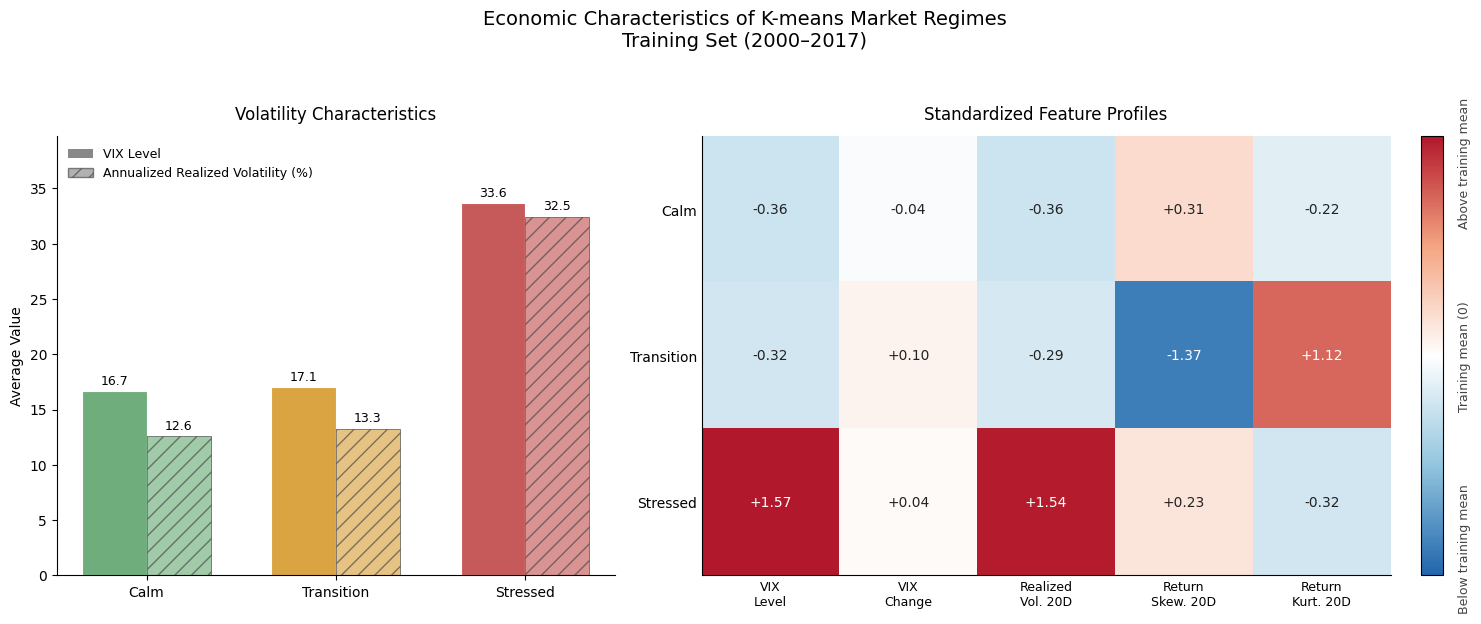

In [40]:

# --------------------------------------------------
# 7.4 Visualize K-means Economic Regime Characteristics
# --------------------------------------------------

fig_kmeans_regime_characteristics, (
    ax_kmeans_vol,
    ax_kmeans_features
) = plt.subplots(
    1, 2,
    figsize=(15, 6),
    gridspec_kw={"width_ratios": [1, 1.35]}
)

# --------------------------------------------------
# Panel A: Original-unit volatility characteristics
# --------------------------------------------------

x = np.arange(len(regime_order))
bar_width = 0.34

vix_values = (
    kmeans_regime_characteristics
    .reindex(regime_order)["Avg_VIX"]
    .to_numpy()
)

rv_values = (
    kmeans_regime_characteristics
    .reindex(regime_order)["Avg_Annualized_Realized_Vol"]
    .to_numpy()
)

for i, regime in enumerate(regime_order):

    color = regime_colors[regime]

    ax_kmeans_vol.bar(
        x[i] - bar_width / 2,
        vix_values[i],
        width=bar_width,
        color=color,
        edgecolor="white",
        linewidth=0.8
    )

    ax_kmeans_vol.bar(
        x[i] + bar_width / 2,
        rv_values[i],
        width=bar_width,
        color=color,
        alpha=0.65,
        hatch="//",
        edgecolor="#444444",
        linewidth=0.7
    )

    for xpos, value in [
        (x[i] - bar_width / 2, vix_values[i]),
        (x[i] + bar_width / 2, rv_values[i])
    ]:
        ax_kmeans_vol.text(
            xpos,
            value + 0.6,
            f"{value:.1f}",
            ha="center",
            fontsize=9
        )

ax_kmeans_vol.set_xticks(x)
ax_kmeans_vol.set_xticklabels(regime_order)

ax_kmeans_vol.set_ylabel("Average Value")
ax_kmeans_vol.set_title(
    "Volatility Characteristics",
    fontsize=12,
    pad=12
)

ax_kmeans_vol.set_ylim(
    0,
    max(vix_values.max(), rv_values.max()) * 1.18
)

from matplotlib.patches import Patch

ax_kmeans_vol.legend(
    handles=[
        Patch(
            facecolor="#888888",
            label="VIX Level"
        ),
        Patch(
            facecolor="#888888",
            edgecolor="#444444",
            hatch="//",
            alpha=0.65,
            label="Annualized Realized Volatility (%)"
        )
    ],
    frameon=False,
    loc="upper left",
    fontsize=9
)


# --------------------------------------------------
# Panel B: Standardized K-means Feature Profiles
#         Vibrant Diverging Heatmap
# --------------------------------------------------

from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# Map cluster centers to economic regime labels
cluster_center_df = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=kmeans_features
)

cluster_center_df["Regime"] = (
    cluster_center_df.index.map(kmeans_cluster_to_regime)
)

# Arrange clusters in the established economic regime order
cluster_center_df = (
    cluster_center_df
    .set_index("Regime")
    .reindex(regime_order)
)

# Readable feature labels
feature_labels = [
    "VIX\nLevel",
    "VIX\nChange",
    "Realized\nVol. 20D",
    "Return\nSkew. 20D",
    "Return\nKurt. 20D"
]

profile_values = (
    cluster_center_df[kmeans_features]
    .to_numpy()
)

# --------------------------------------------------
# Vibrant diverging palette
# --------------------------------------------------

profile_cmap = LinearSegmentedColormap.from_list(
    "market_profile_vibrant",
    [
        "#2166AC",  # Strong blue: below training mean
        "#92C5DE",  # Light blue
        "#FFFFFF",  # White: training mean
        "#F4A582",  # Coral
        "#B2182B"   # Deep red: above training mean
    ]
)

# Center color scale at the training mean (zero)
max_abs = np.abs(profile_values).max()

profile_norm = TwoSlopeNorm(
    vmin=-max_abs,
    vcenter=0,
    vmax=max_abs
)

# --------------------------------------------------
# Draw heatmap
# --------------------------------------------------

heatmap = ax_kmeans_features.imshow(
    profile_values,
    cmap=profile_cmap,
    norm=profile_norm,
    aspect="auto"
)

# Feature labels
ax_kmeans_features.set_xticks(
    np.arange(len(feature_labels))
)

ax_kmeans_features.set_xticklabels(
    feature_labels,
    fontsize=9
)

# Regime labels
ax_kmeans_features.set_yticks(
    np.arange(len(regime_order))
)

ax_kmeans_features.set_yticklabels(
    regime_order
)

ax_kmeans_features.set_title(
    "Standardized Feature Profiles",
    fontsize=12,
    pad=12
)

# --------------------------------------------------
# Annotate standardized values
# --------------------------------------------------

for i in range(len(regime_order)):
    for j in range(len(kmeans_features)):

        value = profile_values[i, j]

        ax_kmeans_features.text(
            j,
            i,
            f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="medium",
            color="white" if abs(value) > 1.0 else "#222222"
        )

# --------------------------------------------------
# Colorbar: Numerical values + vertical descriptions
# --------------------------------------------------

colorbar = fig_kmeans_regime_characteristics.colorbar(
    heatmap,
    ax=ax_kmeans_features,
    fraction=0.045,
    pad=0.04
)

# Preserve numerical z-score values
colorbar.set_ticks([])
colorbar.set_label("")


# Add vertical qualitative labels beside the colorbar
for position, label in [
    (0.06, "Below training mean"),
    (0.50, "Training mean (0)"),
    (0.94, "Above training mean")
]:
    colorbar.ax.text(
        2.0,
        position,
        label,
        rotation=90,
        transform=colorbar.ax.transAxes,
        ha="center",
        va="center",
        fontsize=9,
        color="#444444",
        clip_on=False
    )

colorbar.set_label("")

# --------------------------------------------------
# Final formatting
# --------------------------------------------------

ax_kmeans_features.grid(False)
ax_kmeans_features.tick_params(
    axis="both",
    length=0
)

# --------------------------------------------------
# Overall styling
# --------------------------------------------------

fig_kmeans_regime_characteristics.suptitle(
    "Economic Characteristics of K-means Market Regimes\n"
    "Training Set (2000–2017)",
    fontsize=14,
    y=1.03
)

for ax in [ax_kmeans_vol, ax_kmeans_features]:

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig_kmeans_regime_characteristics.tight_layout()

plt.show()

### Section 7.5 - Out of Sample K-means Regime Identification

This subsection applies the three-cluster K-means benchmark, fitted on the 2000–2017 training observations, to the 2018–2025 testing dataset.

Testing observations are assigned to the nearest training-derived cluster centroid using the same standardized features employed during model fitting. Neither the feature scaler nor the cluster centroids are re-estimated using testing data.

The economic cluster labels established during training are retained to ensure a consistent comparison across periods.

The resulting classifications will be used to evaluate changes in cluster prevalence, economic characteristics, and temporal switching behavior. Particular attention will be given to whether the distinction between Calm and Transition remains primarily associated with return skewness and kurtosis during testing.

In [41]:

# --------------------------------------------------
# 7.5 Out-of-Sample K-means Regime Identification
# --------------------------------------------------

# Predict testing clusters using training-fitted K-means
kmeans_test_clusters = kmeans_model.predict(X_kmeans_test)

# Construct testing benchmark dataset
df_test_kmeans = df_test.copy()

df_test_kmeans["Cluster_ID"] = kmeans_test_clusters

# Apply fixed training-derived economic mapping
df_test_kmeans["Regime"] = (
    df_test_kmeans["Cluster_ID"]
    .map(kmeans_cluster_to_regime)
)

# Validate assignments
assert len(df_test_kmeans) == len(df_test)

assert df_test_kmeans["Regime"].notna().all()

assert set(df_test_kmeans["Cluster_ID"].unique()).issubset(
    set(kmeans_cluster_to_regime.keys())
)

assert df_test_kmeans["Date"].min() > df_train_kmeans["Date"].max()

# Testing-period cluster distribution
kmeans_test_distribution = (
    df_test_kmeans["Regime"]
    .value_counts()
    .reindex(regime_order, fill_value=0)
    .to_frame("Observations")
)

kmeans_test_distribution["Prevalence_Pct"] = (
    kmeans_test_distribution["Observations"]
    / len(df_test_kmeans)
    * 100
)

print("K-means Out-of-Sample Regime Identification\n")

print("Training observations:", len(df_train_kmeans))
print("Testing observations:", len(df_test_kmeans))

print("\nTesting period:")
print(
    df_test_kmeans["Date"].min().date(),
    "to",
    df_test_kmeans["Date"].max().date()
)

print("\nTesting regime distribution:")
display(kmeans_test_distribution.round(2))

print("\nFirst five testing observations:")
display(
    df_test_kmeans[
        [
            "Date",
            "SP500_Close",
            "VIX_Level",
            "Realized_Vol_20D",
            "Cluster_ID",
            "Regime"
        ]
    ].head()
)


K-means Out-of-Sample Regime Identification

Training observations: 4508
Testing observations: 2011

Testing period:
2018-01-02 to 2025-12-31

Testing regime distribution:


,Observations,Prevalence_Pct
Regime,,
Calm,1313,65.29
Transition,441,21.93
Stressed,257,12.78



First five testing observations:


,Date,SP500_Close,VIX_Level,Realized_Vol_20D,Cluster_ID,Regime
4508,2018-01-02,2695.810059,9.77,0.061742,1,Calm
4509,2018-01-03,2713.060059,9.15,0.064050,1,Calm
4510,2018-01-04,2723.989990,9.22,0.061703,1,Calm
4511,2018-01-05,2743.149902,9.22,0.063967,1,Calm
4512,2018-01-08,2747.709961,9.52,0.063913,1,Calm


**Key Observations:**

Key observations
1. Calm remains dominant. Its prevalence changes only slightly, from 64.06% to 65.29%, suggesting that K-means consistently assigns most observations to its broad lower-volatility cluster.

2. Transition becomes more prevalent. Its share increases by 4.29 percentage points. Given its distinctive negative skewness and elevated kurtosis during training, we'll investigate whether these characteristics persist during testing.

3. Stressed becomes less frequent. Its prevalence declines from 18.30% to 12.78%. This could reflect differences in market conditions or how K-means assigns observations near cluster boundaries.

4. K-means and HMM produce substantially different regime distributions. In testing, HMM assigns 49.13% of observations to Transition, compared with only 21.93% for K-means. However, these labels do not necessarily represent equivalent economic states, so prevalence differences alone cannot establish which model performs better.

This provides valuable evidence for our later failure analysis.

### Section 7.6 - Training - Testing Economic Stability

This subsection evaluates whether the economic characteristics of the three K-means clusters remain consistent between the training (2000–2017) and testing (2018–2025) periods.

The analysis compares average VIX levels, daily VIX changes, 20-day rolling annualized realized volatility, return skewness, and return kurtosis.

Particular attention is given to the distinction between Calm and Transition, which exhibited similar volatility levels during training but differed substantially in their return distribution characteristics.

The comparison assesses whether the cluster profiles remain economically interpretable when the training-fitted centroids are applied to previously unseen observations.

As K-means does not explicitly model temporal dependence, this analysis evaluates feature-space consistency rather than regime persistence.



In [42]:

# --------------------------------------------------
# 7.6 Training–Testing K-means Economic Stability
# --------------------------------------------------

economic_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_20D",
    "Return_Skew_20D",
    "Return_Kurt_20D"
]

# Calculate training-period characteristics
kmeans_train_economic = (
    df_train_kmeans
    .groupby("Regime")[economic_features]
    .mean()
    .reindex(regime_order)
)

# Calculate testing-period characteristics
kmeans_test_economic = (
    df_test_kmeans
    .groupby("Regime")[economic_features]
    .mean()
    .reindex(regime_order)
)

# Express annualized realized volatility as a percentage
kmeans_train_economic["Realized_Vol_20D"] *= 100
kmeans_test_economic["Realized_Vol_20D"] *= 100

# Consistent variable names
feature_names = {
    "VIX_Level": "Avg_VIX",
    "VIX_Change": "Avg_VIX_Change",
    "Realized_Vol_20D": "Avg_Annualized_Realized_Vol_Pct",
    "Return_Skew_20D": "Avg_Return_Skew",
    "Return_Kurt_20D": "Avg_Return_Kurt"
}

kmeans_train_economic = kmeans_train_economic.rename(
    columns=feature_names
)

kmeans_test_economic = kmeans_test_economic.rename(
    columns=feature_names
)

# Combine training and testing results
kmeans_economic_stability_df = pd.concat(
    {
        "Training": kmeans_train_economic,
        "Testing": kmeans_test_economic
    },
    axis=1
)

# Validation
assert not kmeans_economic_stability_df.isna().any().any()

print("K-means Economic Stability — Training vs. Testing\n")

display(kmeans_economic_stability_df.round(4))

K-means Economic Stability — Training vs. Testing



Training                                                                                 Testing                                                                               
            Avg_VIX Avg_VIX_Change Avg_Annualized_Realized_Vol_Pct Avg_Return_Skew Avg_Return_Kurt  Avg_VIX Avg_VIX_Change Avg_Annualized_Realized_Vol_Pct Avg_Return_Skew Avg_Return_Kurt
Regime                                                                                                                                                                                    
Calm        16.6912        -0.0690                         12.5826          0.1575          0.1666  17.3131        -0.0647                         12.9350          0.0176         -0.0598
Transition  17.0614         0.1623                         13.2792         -0.9112          2.0533  19.5182         0.1270                         15.6400         -1.0059          2.2241
Stressed    33.6468         0.0681                         32.4607          0.1031          0.0149  32.6502         0.1278                         35.1751          0.0224          0.2077

**Key Observations:**

1. Cluster prevalence is relatively consistent. Calm accounts for 64.06% of training observations and 65.29% of testing observations.

2. Economic characteristics remain distinguishable. Stressed consistently exhibits the highest volatility, while Transition retains negative skewness and elevated kurtosis.

3. K-means organizes market conditions differently from HMM. The HMM distinguishes three progressively higher-volatility states, whereas K-means produces one high-volatility cluster and two lower-volatility clusters with different distributional characteristics.

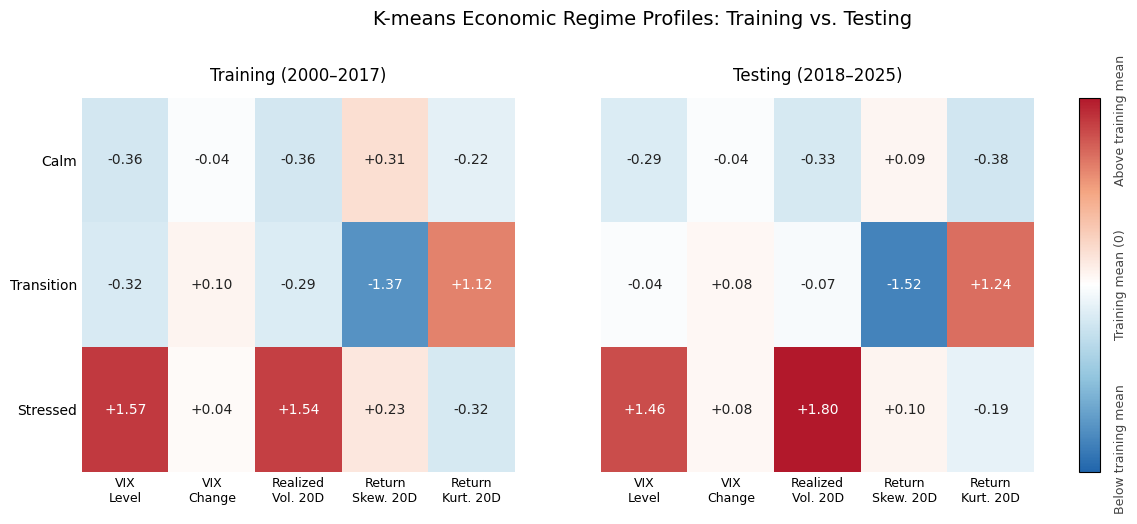

In [43]:

# --------------------------------------------------
# 7.6 Visualize K-means Economic Stability
#     Training vs. Testing Feature Profiles
# --------------------------------------------------

# Feature display labels
feature_labels = [
    "VIX\nLevel",
    "VIX\nChange",
    "Realized\nVol. 20D",
    "Return\nSkew. 20D",
    "Return\nKurt. 20D"
]

# Calculate feature means in original units
train_profile = (
    df_train_kmeans
    .groupby("Regime")[kmeans_features]
    .mean()
    .reindex(regime_order)
)

test_profile = (
    df_test_kmeans
    .groupby("Regime")[kmeans_features]
    .mean()
    .reindex(regime_order)
)

# Standardize both sets using training-fitted scaler parameters
train_profile_scaled = (
    train_profile - scaler.mean_
) / scaler.scale_

test_profile_scaled = (
    test_profile - scaler.mean_
) / scaler.scale_

# Common scale for meaningful comparison
max_abs = max(
    np.abs(train_profile_scaled.to_numpy()).max(),
    np.abs(test_profile_scaled.to_numpy()).max()
)

profile_cmap = LinearSegmentedColormap.from_list(
    "market_profile_vibrant",
    [
        "#2166AC",
        "#92C5DE",
        "#FFFFFF",
        "#F4A582",
        "#B2182B"
    ]
)

profile_norm = TwoSlopeNorm(
    vmin=-max_abs,
    vcenter=0,
    vmax=max_abs
)

# Create comparison figure
fig_kmeans_economic_stability, axes_kmeans_stability = (
    plt.subplots(
        1, 2,
        figsize=(14, 5.5),
        sharey=True
    )
)

for ax, profile, period in zip(
    axes_kmeans_stability,
    [train_profile_scaled, test_profile_scaled],
    ["Training (2000–2017)", "Testing (2018–2025)"]
):

    values = profile.to_numpy()

    heatmap = ax.imshow(
        values,
        cmap=profile_cmap,
        norm=profile_norm,
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(feature_labels)))
    ax.set_xticklabels(feature_labels, fontsize=9)

    ax.set_yticks(np.arange(len(regime_order)))
    ax.set_yticklabels(regime_order)

    ax.tick_params(axis="both", length=0)

    ax.set_title(period, fontsize=12, pad=12)

    # Numeric standardized values
    for i in range(len(regime_order)):
        for j in range(len(kmeans_features)):

            value = values[i, j]

            ax.text(
                j,
                i,
                f"{value:+.2f}",
                ha="center",
                va="center",
                fontsize=10,
                color=(
                    "white"
                    if abs(value) > max_abs * 0.60
                    else "#222222"
                )
            )

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(False)

# --------------------------------------------------
# Shared colorbar positioned beside Testing heatmap
# --------------------------------------------------

# Reserve space for colorbar and vertical descriptions
fig_kmeans_economic_stability.subplots_adjust(
    left=0.10,
    right=0.80,
    bottom=0.15,
    top=0.83,
    wspace=0.20
)

# Get the exact position of the Testing heatmap
test_position = axes_kmeans_stability[1].get_position()

# Manually position colorbar immediately to its right
colorbar_ax = fig_kmeans_economic_stability.add_axes([
    test_position.x1 + 0.012,  # Gap from Testing heatmap
    test_position.y0,          # Align bottom
    0.015,                     # Colorbar width
    test_position.height       # Match heatmap height
])

colorbar = fig_kmeans_economic_stability.colorbar(
    heatmap,
    cax=colorbar_ax
)

colorbar.set_ticks([])
colorbar.set_label("")

# Vertical qualitative descriptions
for position, label in [
    (0.06, "Below training mean"),
    (0.50, "Training mean (0)"),
    (0.94, "Above training mean")
]:

    colorbar.ax.text(
        2.0,
        position,
        label,
        rotation=90,
        transform=colorbar.ax.transAxes,
        ha="center",
        va="center",
        fontsize=9,
        color="#444444",
        clip_on=False
    )

fig_kmeans_economic_stability.suptitle(
    "K-means Economic Regime Profiles: Training vs. Testing",
    fontsize=14,
    y=0.99
)

# Reserve horizontal space for descriptive colorbar labels
fig_kmeans_economic_stability.subplots_adjust(
    left=0.10,
    right=0.78,
    bottom=0.15,
    top=0.83,
    wspace=0.20
)

plt.show()

**Key Observations:**

 **Consistent Identification of High-Volatility Conditions:** The Stressed cluster retains substantially higher volatility than the other clusters in both periods. Its average VIX changes from 33.65 during training to 32.65 during testing, while average 20-day rolling annualized realized volatility increases from 32.46% to 35.18%.

2. **Stability of the Broad Calm Cluster:** Calm remains associated with relatively moderate market conditions. Its average VIX increases slightly from 16.69 to 17.31, while annualized realized volatility changes from 12.58% to 12.94%, indicating broadly consistent volatility characteristics.

3. **Distinctive Transition Cluster Characteristics:** Transition continues to exhibit strongly negative return skewness and elevated kurtosis. Average skewness changes from -0.91 during training to -1.01 during testing, while kurtosis increases from 2.05 to 2.22. These characteristics remain more distinctive than its volatility levels relative to Calm.

4. **Increased Volatility Within Transition:** Average VIX increases from 17.06 during training to 19.52 during testing, while annualized realized volatility rises from 13.28% to 15.64%. Consequently, the volatility distinction between Calm and Transition becomes more pronounced during testing, although both remain substantially less volatile than Stressed.

5. **Relative Stability of Cluster Prevalence:** Calm remains the dominant K-means classification, increasing slightly from 64.06% of training observations to 65.29% during testing. Transition increases from 17.64% to 21.93%, while Stressed declines from 18.30% to 12.78%.

6. **Different Economic Structure From the HMM:** Unlike the Gaussian HMM, which produces three regimes with progressively higher average volatility, K-means primarily separates one high-volatility cluster from two lower-volatility clusters. The distinction between its Calm and Transition classifications is influenced substantially by return skewness and kurtosis.

**Implications for Subsequent Modeling**

The findings indicate that the K-means benchmark retains economically distinguishable cluster characteristics outside the training period. However, the economic meaning of its Transition cluster differs from that of the HMM's Transition regime.

This distinction is important for the subsequent model comparison. Although both approaches use the same standardized market features and three economic labels, their classification structures are not directly equivalent.

The results suggest that K-means places considerable emphasis on differences in return distribution characteristics, whereas the HMM produces a more pronounced ordering of market volatility conditions.

The subsequent benchmark comparison will evaluate differences in clustering quality, regime assignments, and temporal switching behavior. These findings will also support the later failure analysis, which investigates whether differences in model behavior arise from the underlying data, clustering assumptions, or temporal modeling structure.

**Methodological Considerations**

The standardized heatmaps display average feature values relative to the training-period mean and standard deviation. They represent descriptive cluster characteristics rather than feature importance, classification confidence, or statistical significance.

Furthermore, the apparent stability of average cluster characteristics does not establish that the underlying feature distributions are identical across periods. This distinction will be investigated further during the dedicated failure analysis.

### Section 7.7 - Direct Comparison: Gaussian HMM vs. K-means

This subsection compares the Gaussian HMM and K-means benchmark using the same standardized market features and training observations (2000–2017).

**Evaluation Metrics**

- **Silhouette Score (Higher is better):** Measures how closely observations resemble their assigned cluster compared with other clusters. Higher values indicate better cluster separation.
- **Davies–Bouldin Index (Lower is better):** Measures within-cluster dispersion relative to separation between clusters. Lower values indicate more compact and distinct clusters.
- **Calinski–Harabasz Index (Higher is better):** Measures between-cluster dispersion relative to within-cluster dispersion. Higher values indicate stronger cluster separation.
- **Regime Switches (Lower is not necessarily better):** Counts the number of times the inferred market regime changes between consecutive trading observations.
- **Switch Rate (%) (Lower is not necessarily better):** Expresses regime switches as a percentage of consecutive observation pairs, allowing comparison of temporal stability.

**Methodological Considerations**

- Both models are evaluated using identical standardized training observations.
- The HMM explicitly models temporal state transitions, whereas K-means clusters observations based on Euclidean distance.
- Distance-based clustering metrics may favor K-means because they align more closely with its optimization objective.
- Greater regime persistence does not automatically indicate superior performance, as excessive persistence may conceal meaningful market changes.
- The comparison evaluates clustering quality and temporal behavior, not forecasting accuracy.

In [44]:

# --------------------------------------------------
# 7.7 Gaussian HMM vs. K-means — Training Comparison
# --------------------------------------------------

# Retrieve training-period numerical assignments
hmm_labels = df_train_regimes["State_ID"].to_numpy()
kmeans_labels = df_train_kmeans["Cluster_ID"].to_numpy()

def evaluate_clustering(labels, X, model_name):
    """Evaluate clustering quality and temporal switching."""

    silhouette = silhouette_score(
        X,
        labels,
        sample_size=2000,
        random_state=RANDOM_STATE
    )

    davies_bouldin = davies_bouldin_score(X, labels)

    calinski_harabasz = calinski_harabasz_score(X, labels)

    # Count switches between consecutive trading observations
    switches = np.count_nonzero(labels[1:] != labels[:-1])

    switch_rate = switches / (len(labels) - 1) * 100

    return {
        "Model": model_name,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies_bouldin,
        "Calinski_Harabasz": calinski_harabasz,
        "Regime_Switches": switches,
        "Switch_Rate_Pct": switch_rate
    }

# Compare models using identical training observations
model_comparison_df = pd.DataFrame([
    evaluate_clustering(
        hmm_labels,
        X_train_scaled,
        "Gaussian HMM"
    ),
    evaluate_clustering(
        kmeans_labels,
        X_train_scaled,
        "K-means"
    )
]).set_index("Model")

# Validate results
assert np.isfinite(model_comparison_df.to_numpy()).all()

print("Gaussian HMM vs. K-means — Training Set (2000–2017)\n")
display(model_comparison_df.round(4))

Gaussian HMM vs. K-means — Training Set (2000–2017)



,Silhouette,Davies_Bouldin,Calinski_Harabasz,Regime_Switches,Switch_Rate_Pct
Model,,,,,
Gaussian HMM,0.1212,1.8834,767.9406,131,2.9066
K-means,0.2687,1.3083,1227.0183,368,8.1651


**Key Observations:**

1. K-means demonstrates stronger cluster separation. It outperforms the HMM across all three internal clustering metrics, indicating more compact and distinct groupings in the standardized feature space.

2. The HMM produces more temporally persistent classifications. It records 131 regime switches compared with 368 for K-means. Its switching rate of 2.91% is approximately one-third of K-means' 8.17%.

3. The difference reflects the models' objectives. K-means minimizes within-cluster squared Euclidean distances, while the HMM estimates feature distributions alongside state-transition probabilities. Consequently, their optimization objectives favor different clustering characteristics.

4. Greater persistence is not necessarily better. The HMM's lower switching frequency may represent meaningful continuity in financial market conditions, but it could also smooth over short-lived changes. Conversely, K-means' higher switching frequency may capture abrupt changes or reflect noisy classifications.

5. Economic interpretation remains important. Our earlier analysis showed that K-means' Transition cluster is primarily distinguished by negative skewness and elevated kurtosis, whereas the HMM's regimes follow a clearer volatility ordering.

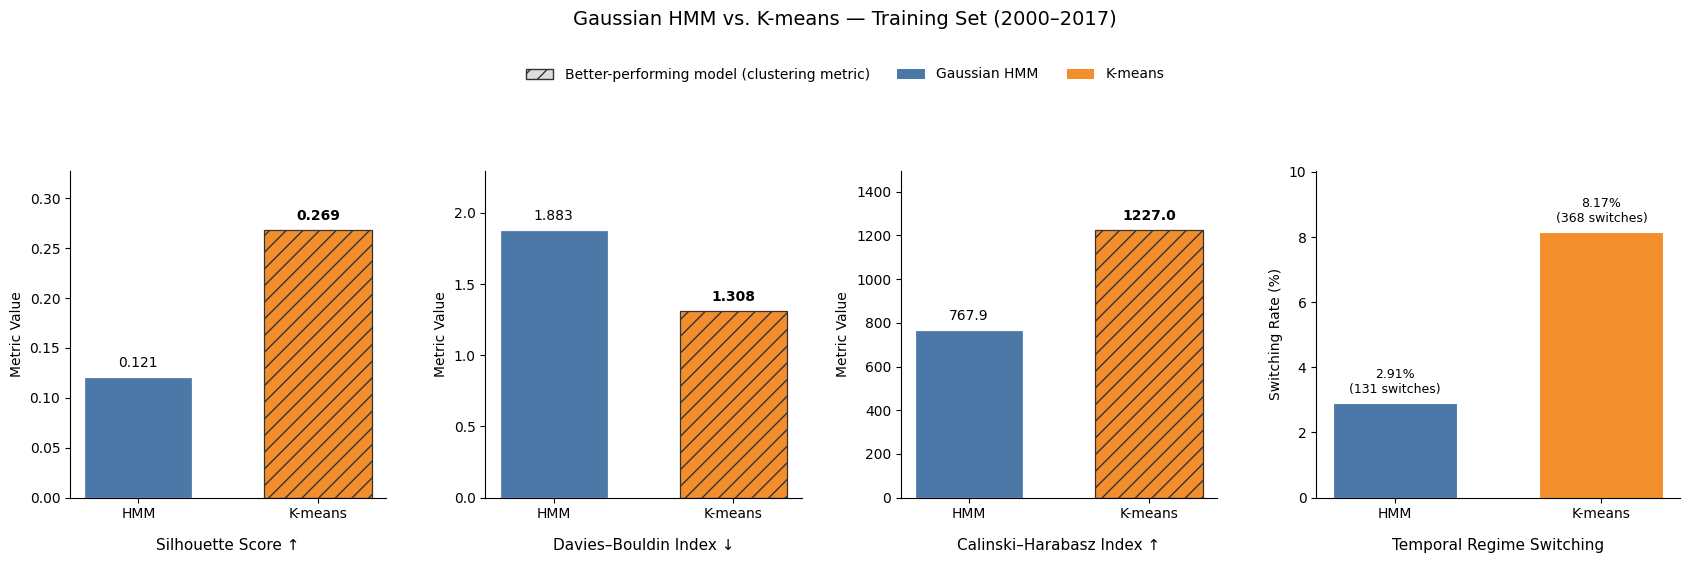

In [50]:

# --------------------------------------------------
# 7.7 HMM vs. K-means — Training Comparison
#     Actual metric scales and centered figure layout
# --------------------------------------------------

from matplotlib.patches import Patch

# Consistent model colors
model_colors = {
    "Gaussian HMM": "#4C78A8",
    "K-means": "#F28E2B"
}

models = ["Gaussian HMM", "K-means"]

metrics = [
    ("Silhouette", "Silhouette Score ↑", True),
    ("Davies_Bouldin", "Davies–Bouldin Index ↓", False),
    ("Calinski_Harabasz", "Calinski–Harabasz Index ↑", True)
]

# Retain figure for export in Misc
fig_hmm_kmeans_comparison, axes_train_compare = plt.subplots(
    1, 4,
    figsize=(17, 6),
    gridspec_kw={"width_ratios": [1, 1, 1, 1.15]}
)

# --------------------------------------------------
# Panels A–C: Internal clustering quality
# --------------------------------------------------

for ax, (metric, title, higher_is_better) in zip(
    axes_train_compare[:3],
    metrics
):

    values = model_comparison_df.loc[models, metric]

    best_model = (
        values.idxmax()
        if higher_is_better
        else values.idxmin()
    )

    for i, model in enumerate(models):

        score = values.loc[model]
        is_best = model == best_model

        ax.bar(
            i,
            score,
            width=0.60,
            color=model_colors[model],
            edgecolor="#333333" if is_best else "white",
            linewidth=0.9,
            hatch="//" if is_best else None
        )

        label = (
            f"{score:.1f}"
            if metric == "Calinski_Harabasz"
            else f"{score:.3f}"
        )

        ax.annotate(
            label,
            xy=(i, score),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold" if is_best else "normal"
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["HMM", "K-means"])

    ax.set_ylim(0, values.max() * 1.22)
    ax.set_ylabel("Metric Value")

    # Center panel heading below model names
    ax.set_xlabel(
        title,
        fontsize=11,
        labelpad=12
    )

# --------------------------------------------------
# Panel D: Temporal regime switching
# --------------------------------------------------

ax_train_switching = axes_train_compare[3]

switch_values = model_comparison_df.loc[
    models, "Switch_Rate_Pct"
]

for i, model in enumerate(models):

    rate = switch_values.loc[model]

    switches = int(
        model_comparison_df.loc[
            model, "Regime_Switches"
        ]
    )

    ax_train_switching.bar(
        i,
        rate,
        width=0.60,
        color=model_colors[model],
        edgecolor="white",
        linewidth=0.8
    )

    ax_train_switching.annotate(
        f"{rate:.2f}%\n({switches} switches)",
        xy=(i, rate),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_train_switching.set_xticks([0, 1])
ax_train_switching.set_xticklabels(["HMM", "K-means"])

ax_train_switching.set_ylabel("Switching Rate (%)")
ax_train_switching.set_ylim(0, switch_values.max() * 1.23)

ax_train_switching.set_xlabel(
    "Temporal Regime Switching",
    fontsize=11,
    labelpad=12
)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

legend_handles = [
    Patch(
        facecolor="#DDDDDD",
        edgecolor="#333333",
        hatch="//",
        label="Better-performing model (clustering metric)"
    ),
    Patch(
        facecolor=model_colors["Gaussian HMM"],
        label="Gaussian HMM"
    ),
    Patch(
        facecolor=model_colors["K-means"],
        label="K-means"
    )
]

fig_hmm_kmeans_comparison.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.895),
    ncol=3,
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# Figure title and styling
# --------------------------------------------------

fig_hmm_kmeans_comparison.suptitle(
    "Gaussian HMM vs. K-means — Training Set (2000–2017)",
    fontsize=14,
    y=0.97
)

for ax in axes_train_compare:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Reserve space above the panels for the legend
fig_hmm_kmeans_comparison.tight_layout(
    rect=[0, 0.04, 1, 0.79],
    w_pad=2.5
)

plt.show()

**Key Observations:**

- Gaussian HMM vs. K-means Training Set (2000 - 2017) summary findings

This section developed and evaluated K-means as an unsupervised benchmark against the three-state Gaussian Hidden Markov Model (HMM). Both approaches used the same five standardized market features and chronological training (2000–2017) and testing (2018–2025) datasets. The analysis assessed K-means clustering quality, economic interpretability, out-of-sample stability, and differences in temporal behavior relative to the HMM.

Activities Performed

Benchmark Configuration: Established a consistent comparison framework using the same five features, training-fitted StandardScaler, and chronological data split as the HMM.
Hyperparameter Selection: Evaluated K = 2 through 6 using the Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, inertia, and cluster prevalence.
Model Fitting: Selected K = 3 for economic interpretability and direct comparability with the HMM, then fitted the benchmark using multiple centroid initializations.
Economic Labeling: Examined standardized cluster centers and original-unit market characteristics to assign Calm, Transition, and Stressed labels.
Out-of-Sample Identification: Applied the training-fitted K-means model to the 2018–2025 testing dataset without re-estimating scaling parameters or cluster centroids.
Economic Stability Evaluation: Compared VIX, daily VIX changes, 20-day rolling annualized realized volatility, return skewness, and kurtosis across training and testing.
Model Comparison: Evaluated the Gaussian HMM and K-means using identical training observations and internal clustering metrics, alongside regime switching frequencies and rates.
Visualization: Developed hyperparameter-selection charts, economic cluster profiles, training–testing feature heatmaps, and a two-panel HMM–K-means comparison.
Key Observations

K = 3 Selected for Comparability and Interpretability: Although K = 2 achieved the highest Silhouette Score (0.3529) and Calinski–Harabasz Index (1330.41), K = 3 was retained to allow direct comparison with the three-state HMM. The selected solution achieved a Silhouette Score of 0.2687 and Davies–Bouldin Index of 1.3083 while avoiding the very small clusters observed at higher K values.

Uneven Cluster Prevalence: The K-means training solution assigned 64.06% of observations to Calm, 17.64% to Transition, and 18.30% to Stressed. Calm remained dominant during testing at 65.29%, while Transition increased to 21.93% and Stressed declined to 12.78%.

Clear Identification of High-Volatility Conditions: The Stressed cluster exhibited substantially higher average VIX and annualized realized volatility than the other clusters. During training, its average VIX was 33.65 and realized volatility was 32.46%, compared with 16.69 and 12.58% for Calm. This distinction remained evident during testing, with Stressed recording an average VIX of 32.65 and annualized realized volatility of 35.18%.

Transition Distinguished by Return Distribution Characteristics: Unlike the HMM's intermediate-volatility regime, K-means Transition was primarily distinguished by negative return skewness and elevated kurtosis. During training, its average skewness was -0.91 and kurtosis was 2.05, compared with 0.16 and 0.17 for Calm. These characteristics persisted during testing, with Transition skewness of -1.01 and kurtosis of 2.22.

Economic Characteristics Remain Distinguishable Outside Training: The K-means clusters retained their broad economic profiles during testing. Calm continued to represent relatively moderate volatility conditions, Transition maintained distinctive skewness and kurtosis, and Stressed remained associated with substantially elevated volatility. However, average volatility within Transition increased, with VIX rising from 17.06 to 19.52 and annualized realized volatility from 13.28% to 15.64%.

Superior Internal Clustering Metrics for K-means: In the direct training comparison, K-means outperformed the HMM on all three cluster-separation measures. K-means achieved a Silhouette Score of 0.2687 versus 0.1212 for the HMM, a Davies–Bouldin Index of 1.3083 versus 1.8834, and a Calinski–Harabasz Index of 1227.02 versus 767.94.

Greater Temporal Persistence Under the HMM: The HMM recorded 131 regime switches during training, corresponding to a switching rate of 2.91%, compared with 368 switches and an 8.17% switching rate for K-means. This difference is consistent with the HMM's explicit treatment of temporal dependence, whereas K-means assigns observations independently based on their positions in feature space.

Different Economic Structures Across Models: The HMM identified three regimes with progressively higher average volatility, while K-means identified one distinctly high-volatility cluster and two lower-volatility clusters separated largely by higher-order return moments. Therefore, the economic labels assigned to the two models are useful for broad comparison but do not imply equivalent underlying market states.

Implications for Subsequent Modeling

The results establish a trade-off between clustering quality and temporal continuity. K-means produces more geometrically separated clusters, whereas the Gaussian HMM generates more persistent regime assignments with a clearer economic ordering of volatility conditions.

The relative consistency of K-means cluster characteristics during testing suggests that its feature-based groupings remain interpretable outside the estimation period. However, these characteristics differ from those of the HMM, particularly for Transition conditions.

These differences motivate the subsequent failure analysis, which will investigate whether variations in regime prevalence, fragmentation, and economic interpretation are associated with shifts in the underlying market data, model specifications, or temporal modeling assumptions.

The HMM remains the primary regime-identification approach for the subsequent volatility-forecasting framework in Model A. Its potential predictive contribution must be assessed separately through out-of-sample supervised evaluation.

Methodological Considerations

K = 3 was selected for benchmark comparability and economic interpretation, not because it was optimal across every internal validation metric.
The Silhouette Score was estimated using a reproducible sample of 2,000 training observations; the Davies–Bouldin and Calinski–Harabasz metrics used the full training sample.
Internal clustering metrics measure cluster geometry and may favor K-means because they align more closely with its distance-minimization objective.
Regime-switching frequency measures temporal continuity rather than classification accuracy. Greater persistence is not automatically preferable.
K-means and HMM regime labels are assigned through different clustering mechanisms and do not necessarily identify economically equivalent conditions.
Because independently verified regime labels are unavailable, the results assess descriptive clustering properties rather than conventional classification accuracy.
The direct HMM–K-means comparison conducted in this section covers the training period. Testing-period model-comparison metrics remain to be evaluated separately.

### Section 7.8 - Out of Sample Comparison: Gaussian HMM vs K-means

This subsection extends the direct model comparison to the testing period (2018–2025) to assess whether differences in clustering quality and temporal switching persist outside the training sample.

Both methods are evaluated using identical standardized testing observations and the same internal clustering metrics applied during training. The analysis also compares regime-switching frequencies to evaluate temporal continuity.

Neither model is re-estimated on the testing dataset. The HMM uses retrospective sequence decoding, while K-means assigns observations to its fixed training-derived cluster centroids.

These results assess descriptive out-of-sample clustering behavior rather than forecasting accuracy.

In [46]:
# --------------------------------------------------
# 7.8 Gaussian HMM vs. K-means — Testing Comparison
# --------------------------------------------------

# Retrieve testing-period numerical assignments
hmm_test_labels = df_test_regimes["State_ID"].to_numpy()
kmeans_test_labels = df_test_kmeans["Cluster_ID"].to_numpy()

# Verify aligned testing observations
assert np.array_equal(
    df_test_regimes["Date"].to_numpy(),
    df_test_kmeans["Date"].to_numpy()
)

assert len(hmm_test_labels) == len(X_test_scaled)
assert len(kmeans_test_labels) == len(X_test_scaled)

# Reuse the evaluation function from Section 7.7
test_model_comparison_df = pd.DataFrame([
    evaluate_clustering(
        hmm_test_labels,
        X_test_scaled,
        "Gaussian HMM"
    ),
    evaluate_clustering(
        kmeans_test_labels,
        X_test_scaled,
        "K-means"
    )
]).set_index("Model")

# Validate results
assert np.isfinite(
    test_model_comparison_df.to_numpy()
).all()

print("Gaussian HMM vs. K-means — Testing Set (2018–2025)\n")

display(test_model_comparison_df.round(4))

Gaussian HMM vs. K-means — Testing Set (2018–2025)



,Silhouette,Davies_Bouldin,Calinski_Harabasz,Regime_Switches,Switch_Rate_Pct
Model,,,,,
Gaussian HMM,0.0556,2.1578,218.7283,83,4.1294
K-means,0.2887,1.4653,414.4773,159,7.9104


**Key Observations:**

1. HMM cluster separation deteriorates during testing. Its silhouette score falls from 0.1212 to 0.0556, while the Davies–Bouldin Index increases from 1.8834 to 2.1578. This suggests weaker separation between its decoded regimes in the testing feature space.

2. K-means retains stronger geometric separation. Its silhouette score increases slightly from 0.2687 to 0.2887, although its Davies–Bouldin Index also worsens from 1.3083 to 1.4653. The results suggest that K-means remains comparatively effective at separating observations geometrically.

3. The HMM remains more persistent. Its testing switching rate is 4.13%, compared with 7.91% for K-means. However, the HMM's switching rate increases from 2.91% during training, suggesting less persistence in testing.

4. K-means switching behavior remains relatively consistent. Its switching rate declines slightly from 8.17% to 7.91%, despite changes in cluster prevalence.

5. The Calinski–Harabasz Index declines substantially for both models. This indicates weaker between-cluster dispersion relative to within-cluster dispersion during testing. However, because the training and testing samples differ in size and market composition, these absolute index values should not be interpreted as directly comparable measures of deterioration without qualification.

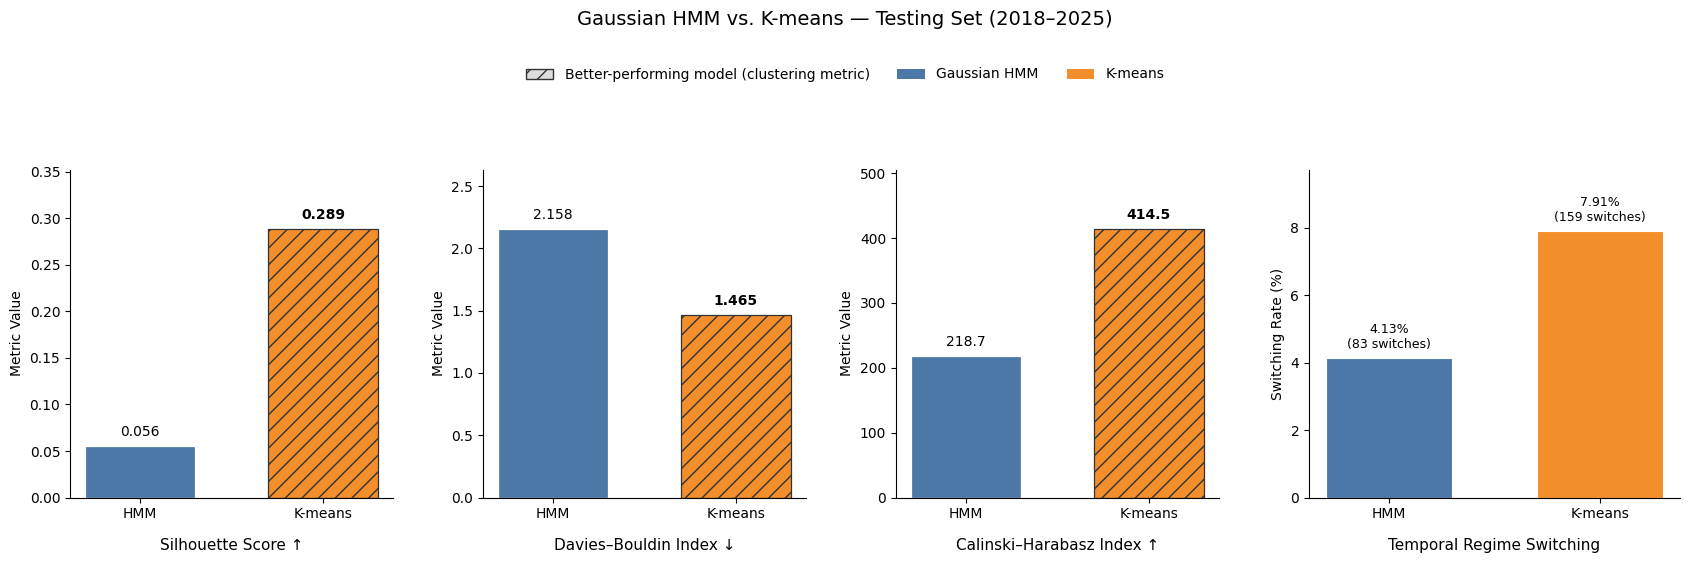

In [51]:

# --------------------------------------------------
# 7.8 HMM vs. K-means — Testing Comparison
#     Actual metric scales and centered figure layout
# --------------------------------------------------

from matplotlib.patches import Patch

# Same model colors as Section 7.7
model_colors = {
    "Gaussian HMM": "#4C78A8",
    "K-means": "#F28E2B"
}

models = ["Gaussian HMM", "K-means"]

metrics = [
    ("Silhouette", "Silhouette Score ↑", True),
    ("Davies_Bouldin", "Davies–Bouldin Index ↓", False),
    ("Calinski_Harabasz", "Calinski–Harabasz Index ↑", True)
]

# Retain figure for export in Misc
fig_hmm_kmeans_test_comparison, axes_test_compare = plt.subplots(
    1, 4,
    figsize=(17, 6),
    gridspec_kw={"width_ratios": [1, 1, 1, 1.15]}
)

# --------------------------------------------------
# Panels A–C: Internal clustering quality
# --------------------------------------------------

for ax, (metric, title, higher_is_better) in zip(
    axes_test_compare[:3],
    metrics
):

    values = test_model_comparison_df.loc[models, metric]

    best_model = (
        values.idxmax()
        if higher_is_better
        else values.idxmin()
    )

    for i, model in enumerate(models):

        score = values.loc[model]
        is_best = model == best_model

        ax.bar(
            i,
            score,
            width=0.60,
            color=model_colors[model],
            edgecolor="#333333" if is_best else "white",
            linewidth=0.9,
            hatch="//" if is_best else None
        )

        label = (
            f"{score:.1f}"
            if metric == "Calinski_Harabasz"
            else f"{score:.3f}"
        )

        ax.annotate(
            label,
            xy=(i, score),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold" if is_best else "normal"
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["HMM", "K-means"])

    ax.set_ylim(0, values.max() * 1.22)
    ax.set_ylabel("Metric Value")

    # Center panel heading below model names
    ax.set_xlabel(
        title,
        fontsize=11,
        labelpad=12
    )

# --------------------------------------------------
# Panel D: Temporal regime switching
# --------------------------------------------------

ax_test_switching = axes_test_compare[3]

switch_values = test_model_comparison_df.loc[
    models, "Switch_Rate_Pct"
]

for i, model in enumerate(models):

    rate = switch_values.loc[model]

    switches = int(
        test_model_comparison_df.loc[
            model, "Regime_Switches"
        ]
    )

    ax_test_switching.bar(
        i,
        rate,
        width=0.60,
        color=model_colors[model],
        edgecolor="white",
        linewidth=0.8
    )

    ax_test_switching.annotate(
        f"{rate:.2f}%\n({switches} switches)",
        xy=(i, rate),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_test_switching.set_xticks([0, 1])
ax_test_switching.set_xticklabels(["HMM", "K-means"])

ax_test_switching.set_ylabel("Switching Rate (%)")
ax_test_switching.set_ylim(0, switch_values.max() * 1.23)

ax_test_switching.set_xlabel(
    "Temporal Regime Switching",
    fontsize=11,
    labelpad=12
)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

legend_handles = [
    Patch(
        facecolor="#DDDDDD",
        edgecolor="#333333",
        hatch="//",
        label="Better-performing model (clustering metric)"
    ),
    Patch(
        facecolor=model_colors["Gaussian HMM"],
        label="Gaussian HMM"
    ),
    Patch(
        facecolor=model_colors["K-means"],
        label="K-means"
    )
]

fig_hmm_kmeans_test_comparison.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.895),
    ncol=3,
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# Figure title and styling
# --------------------------------------------------

fig_hmm_kmeans_test_comparison.suptitle(
    "Gaussian HMM vs. K-means — Testing Set (2018–2025)",
    fontsize=14,
    y=0.97
)

for ax in axes_test_compare:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig_hmm_kmeans_test_comparison.tight_layout(
    rect=[0, 0.04, 1, 0.79],
    w_pad=2.5
)

plt.show()

### Section 7.9 - Summary of K-means Benchmark

This subsection consolidates the findings from the K-means benchmark and its comparison with the Gaussian Hidden Markov Model (HMM).

The evaluation compares internal clustering quality and temporal switching behavior across the training (2000–2017) and testing (2018–2025) periods.

A consolidated visualization presents both models using consistent metrics, colors, and axis scales to examine whether differences observed during training persist outside the estimation period.

The comparison provides supporting evidence for the subsequent failure analysis, which investigates how feature distributions, model specifications, and temporal assumptions may influence regime identification.

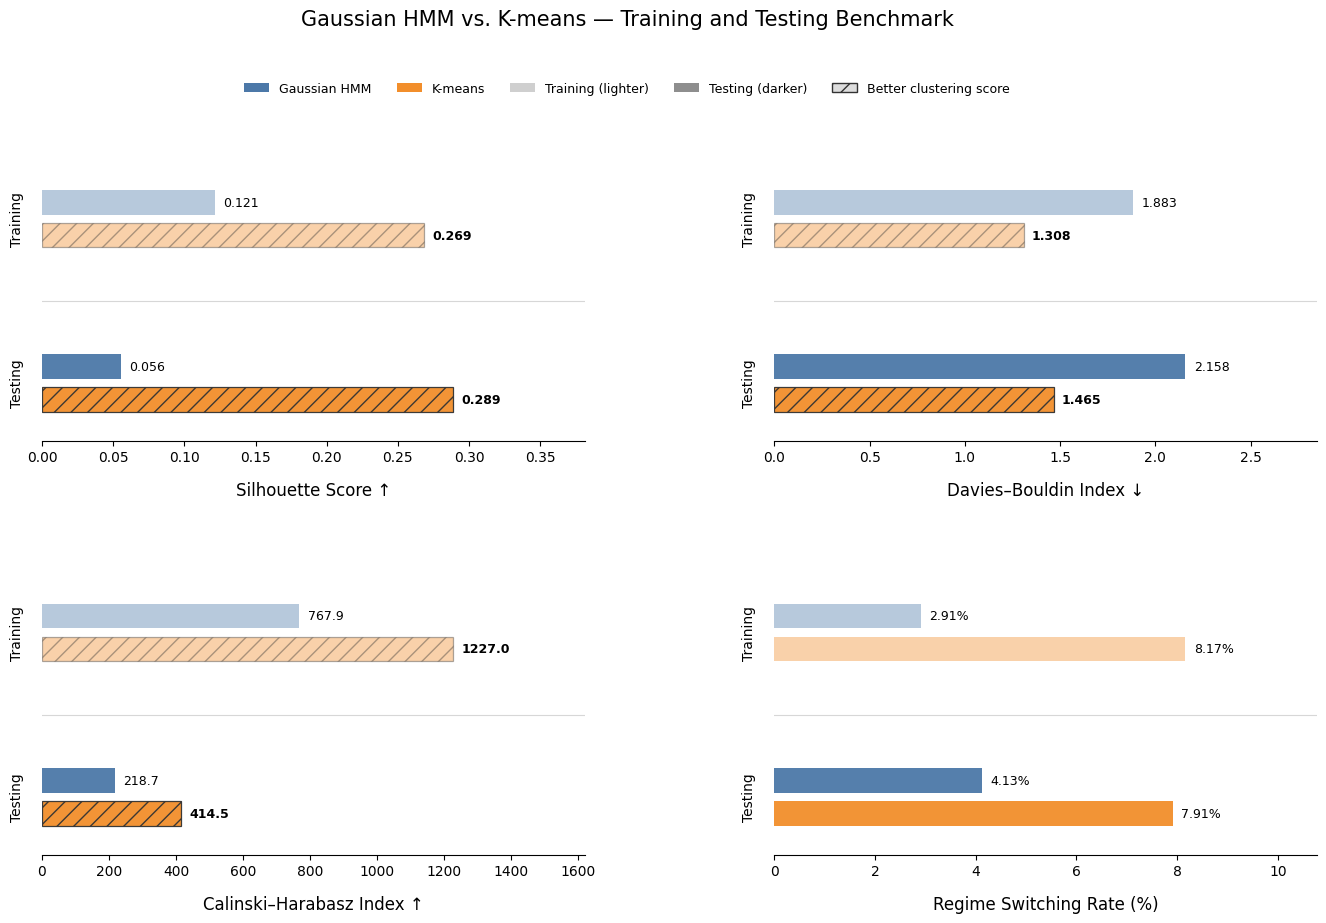

In [57]:

# --------------------------------------------------
# 7.9 Summary of K-means Benchmark
#     Consolidated Training–Testing Comparison
# --------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

model_colors = {
    "Gaussian HMM": "#4C78A8",
    "K-means": "#F28E2B"
}

models = ["Gaussian HMM", "K-means"]

metrics = [
    ("Silhouette", "Silhouette Score ↑", True),
    ("Davies_Bouldin", "Davies–Bouldin Index ↓", False),
    ("Calinski_Harabasz", "Calinski–Harabasz Index ↑", True),
    ("Switch_Rate_Pct", "Regime Switching Rate (%)", None)
]

periods = [
    ("Training", model_comparison_df, 0.40),
    ("Testing", test_model_comparison_df, 0.95)
]

# Four metric panels in a 2 × 2 layout
fig_hmm_kmeans_summary, axes_summary = plt.subplots(
    2, 2,
    figsize=(15, 9.5)
)

axes_summary = axes_summary.flatten()

# Each period contains two model bars, sharing a metric axis.
y_positions = {
    ("Training", "Gaussian HMM"): 3.2,
    ("Training", "K-means"): 2.8,
    ("Testing", "Gaussian HMM"): 1.2,
    ("Testing", "K-means"): 0.8
}

for ax, (metric, title, higher_is_better) in zip(
    axes_summary, metrics
):

    all_values = [
        results.loc[model, metric]
        for _, results, _ in periods
        for model in models
    ]

    metric_max = max(all_values)

    for period, results, opacity in periods:

        values = results.loc[models, metric]

        if higher_is_better is True:
            best_model = values.idxmax()
        elif higher_is_better is False:
            best_model = values.idxmin()
        else:
            best_model = None

        for model in models:

            score = values.loc[model]
            y = y_positions[(period, model)]

            is_best = (
                higher_is_better is not None
                and model == best_model
            )

            ax.barh(
                y,
                score,
                height=0.30,
                color=model_colors[model],
                alpha=opacity,
                edgecolor="#333333" if is_best else "none",
                linewidth=0.9 if is_best else 0,
                hatch="//" if is_best else None,
                zorder=2
            )

            # Annotate original metric values
            if metric == "Calinski_Harabasz":
                value_label = f"{score:.1f}"
            elif metric == "Switch_Rate_Pct":
                value_label = f"{score:.2f}%"
            else:
                value_label = f"{score:.3f}"

            ax.annotate(
                value_label,
                xy=(score, y),
                xytext=(6, 0),
                textcoords="offset points",
                va="center",
                ha="left",
                fontsize=9,
                fontweight="bold" if is_best else "normal"
            )

    # One consistent axis per metric across both periods
    ax.set_xlim(0, metric_max * 1.32)
    ax.set_ylim(0.3, 3.7)

    # Grouped period labels on the y-axis
    ax.set_yticks([3.0, 1.0])
    ax.set_yticklabels(
        ["Training", "Testing"],
        fontsize=10,
        fontweight="medium",
        rotation=90,
        va="center",
        ha="center"
    )
    ax.tick_params(axis="y", pad=18)

    # Subtle separator between periods
    ax.axhline(
        2.0,
        color="#D7D7D7",
        linewidth=0.8,
        zorder=1
    )

    # Measurement heading centered below each panel
    ax.set_xlabel(
        title,
        fontsize=12,
        labelpad=12
    )

    # Remove heading above the panel
    ax.set_title("")


    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

# --------------------------------------------------
# Shared centered legend
# --------------------------------------------------

legend_handles = [
    Patch(
        facecolor=model_colors["Gaussian HMM"],
        label="Gaussian HMM"
    ),
    Patch(
        facecolor=model_colors["K-means"],
        label="K-means"
    ),
    Patch(
        facecolor="#888888",
        alpha=0.40,
        label="Training (lighter)"
    ),
    Patch(
        facecolor="#888888",
        alpha=0.95,
        label="Testing (darker)"
    ),
    Patch(
        facecolor="#DDDDDD",
        edgecolor="#333333",
        hatch="//",
        label="Better clustering score"
    )
]

fig_hmm_kmeans_summary.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.915),
    ncol=5,
    frameon=False,
    fontsize=9
)

fig_hmm_kmeans_summary.suptitle(
    "Gaussian HMM vs. K-means — Training and Testing Benchmark",
    fontsize=15,
    y=0.98
)

fig_hmm_kmeans_summary.subplots_adjust(
    left=0.11,
    right=0.96,
    bottom=0.09,
    top=0.82,
    hspace=0.48,
    wspace=0.35
)

plt.show()

This section developed and evaluated K-means clustering as a non-temporal benchmark for the Gaussian Hidden Markov Model (HMM). Both methods used the same five standardized market features and chronological training–testing split, enabling a consistent comparison of their ability to identify latent market regimes. K-means was evaluated independently for clustering quality, economic interpretability, and out-of-sample stability before being compared directly with the HMM. The consolidated training–testing visualization summarizes the principal findings.

#### Activities Performed

- **Feature alignment:** Applied K-means to the same standardized VIX level, VIX change, 20-day realized volatility, return skewness, and return kurtosis features used by the HMM.
- **Model selection:** Evaluated K-means specifications with 2–6 clusters using Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, cluster sizes, and inertia. Selected three clusters to maintain economic interpretability and comparability with the HMM.
- **Regime interpretation:** Mapped the three K-means clusters to Calm, Transition, and Stressed conditions using training-period market characteristics.
- **Out-of-sample evaluation:** Applied the training-fitted K-means model to the 2018–2025 testing observations without re-estimating its cluster centroids.
- **Economic stability analysis:** Compared average VIX levels, realized volatility, skewness, and kurtosis across training and testing periods.
- **Model benchmarking:** Compared K-means and HMM assignments using internal clustering metrics and observed regime-switching frequencies in both periods.
- **Consolidated visualization:** Developed a combined training–testing comparison using consistent metric scales, model colors, and performance indicators.

#### Key Observations

**1. K-means produced stronger geometric cluster separation than the HMM.**

During training, K-means achieved a Silhouette Score of 0.2687, compared with 0.1212 for the HMM. Its Davies–Bouldin Index was also lower (1.3083 versus 1.8834), while its Calinski–Harabasz Index was higher (1,227.02 versus 767.94).

This advantage persisted during testing. K-means achieved a Silhouette Score of 0.2887, compared with 0.0556 for the HMM, and a Davies–Bouldin Index of 1.4653, compared with 2.1578.

Across both periods, K-means performed better on all three internal clustering measures. These results indicate stronger geometric separation within the standardized feature space, although they do not establish that its regime assignments are more economically meaningful.

**2. K-means and HMM characterized intermediate market conditions differently.**

The K-means Stressed cluster exhibited the highest average VIX and realized volatility, supporting its interpretation as a period of elevated market uncertainty.

However, its Transition cluster was distinguished primarily by strongly negative return skewness and elevated kurtosis rather than by a clear intermediate level of volatility. During training, this cluster had average skewness of approximately -0.91 and kurtosis of 2.05, compared with approximately 0.16 and 0.17 for the Calm cluster.

This distinction remained visible during testing, when the Transition cluster exhibited average skewness of approximately -1.01 and kurtosis of 2.22.

Consequently, the two models' identically named regimes should not be assumed to represent equivalent market conditions. K-means identifies geometric groupings of market characteristics, whereas the HMM jointly incorporates observed market features and temporal state dependence.

**3. The HMM generated more persistent regime assignments.**

During training, the HMM produced 131 regime switches, equivalent to a switching rate of 2.91%, compared with 368 switches and a rate of 8.17% for K-means.

During testing, the HMM recorded 83 switches (4.13%), while K-means recorded 159 switches (7.91%).

These findings indicate that HMM assignments changed less frequently in both periods, consistent with its explicit modeling of state-transition probabilities. However, greater persistence should be interpreted as a model characteristic rather than automatic evidence of superior regime identification.

**4. Out-of-sample performance revealed different forms of stability.**

The HMM's Silhouette Score declined from 0.1212 during training to 0.0556 during testing, while its Davies–Bouldin Index increased from 1.8834 to 2.1578. Its regime-switching rate also increased from 2.91% to 4.13%.

For K-means, the Silhouette Score increased slightly from 0.2687 to 0.2887, while the Davies–Bouldin Index increased from 1.3083 to 1.4653. Its switching rate remained comparatively stable, declining slightly from 8.17% to 7.91%.

These results suggest that the HMM's decoded regimes became less geometrically distinct during testing, whereas K-means maintained comparatively stronger separation. Nevertheless, the testing periods contain different market conditions, so these changes do not, by themselves, establish the underlying causes of performance differences.

#### Implications for Subsequent Modeling

The benchmark demonstrates an important tradeoff between geometric separation and temporal continuity. K-means provides more clearly separated clusters in the standardized feature space, while the HMM produces more persistent regime assignments and explicitly represents transitions between latent market states.

For the integrated forecasting framework, the HMM remains the selected regime-generation method because it provides a probabilistic representation of market states and their evolution through time. This choice reflects the project's objective of incorporating temporally structured regime information into Model A rather than a claim that the HMM outperforms K-means across all evaluation criteria.

The findings also motivate further investigation into the HMM's weaker testing-period cluster separation, changing regime-switching behavior, and sensitivity to the selected features and number of hidden states.

#### **Methodological Considerations**

Both models were fitted using training-period observations only. K-means testing assignments were generated using fixed training-derived centroids, while the HMM testing assignments were obtained through retrospective sequence decoding.

The HMM assignments evaluated in this section are therefore descriptive regime classifications, not strictly real-time state estimates. Subsequent integration with Model A requires filtered regime probabilities that condition only on information available through each observation date.

Additionally, the internal clustering metrics do not measure forecasting accuracy, and switching rates do not independently establish regime classification quality. There are no externally observed ground-truth market-regime labels against which to measure classification accuracy.

The next section extends the evaluation through model diagnostics, sensitivity analysis, and an investigation of potential failure modes.

## Section 8 - Model Diagnostics, Sensitivity Analysis, and Failure Analysis

Building on the Gaussian HMM development and K-means benchmark, this section investigates the robustness, stability, and limitations of the inferred market regimes.

The preceding analysis established that K-means produced stronger geometric separation across training and testing observations, while the HMM generated more persistent regime assignments. However, the HMM exhibited weaker geometric separation and more frequent regime switching during testing.

These findings motivate additional diagnostic analyses to determine whether changes in market characteristics, model specifications, or temporal classification behavior may contribute to the observed differences.

The evaluation focuses on the Gaussian HMM as the primary regime-identification method, with K-means retained as a benchmark where appropriate.


| Subsection | Analysis | Objective |
|:---|:---|:---|
| **8.1** | Diagnostics Framework | Establish the evaluation approach and diagnostic criteria for assessing the HMM. |
| **8.2** | Feature Distribution Shifts | Examine changes in feature distributions between training and testing periods. |
| **8.3** | Regime Assignment and Temporal Diagnostics | Evaluate regime persistence, episode duration, switching behavior, and fragmentation. |
| **8.4** | HMM Sensitivity Analysis | Assess robustness to changes in the number of hidden states and input features. |
| **8.5** | Historical Regime Diagnostics and Failure Analysis | Examine historical crisis alignment, assignment confidence, and potential classification weaknesses. |
| **8.6** | Summary of Model Diagnostics | Consolidate key findings, limitations, and implications for subsequent modeling. |


### Section 8.1 - Diagnostic Objectives and Evaluation Framework

The diagnostic evaluation addresses four questions:

1. **Feature distribution stability:** How did the distributions of the five market features change between training (2000–2017) and testing (2018–2025)?

2. **Regime assignment stability:** How did regime prevalence, switching behavior, and temporal continuity change outside the training period?

3. **Model sensitivity:** How sensitive are the HMM's identified regimes to the number of hidden states and the selected feature representation?

4. **Failure analysis:** Which historical observations or market episodes reveal potential limitations in regime identification, and what characteristics may help explain these limitations?

#### Evaluation Approach

The analysis retains the existing chronological training–testing split, five-feature baseline specification, and training-fitted standardization parameters.

Where alternative HMM specifications are examined, models will be fitted using training observations and subsequently evaluated on the held-out testing period.

Diagnostics will combine descriptive statistics, distribution comparisons, regime-transition measures, internal clustering metrics, and selected historical case studies.

Because market regimes are latent rather than directly observed, the analysis cannot establish classification errors against externally verified regime labels. Instead, potential failure cases will be identified through economically ambiguous assignments, unstable classifications, model disagreement, or unusual market conditions.

### Section 8.2 - Training - Testing Feature Distribution Shifts

This subsection examines whether the market characteristics used to estimate the Gaussian HMM changed between the training and testing periods.

Distribution shifts are relevant because the HMM was estimated using historical feature distributions and subsequently applied to observations outside its estimation period. Changes in feature location, dispersion, or tail behavior may affect the model's ability to distinguish latent market states.

The analysis compares the five input features using descriptive statistics and standardized differences. Training-period means and standard deviations serve as the reference for interpreting testing-period changes.

The objective is to identify potential distribution shifts rather than establish that these shifts caused changes in model performance.

In [60]:

# --------------------------------------------------
# 8.2 Training–Testing Feature Distribution Comparison
# --------------------------------------------------

feature_shift_records = []

for feature in hmm_features:

    train_values = df_train[feature].dropna()
    test_values = df_test[feature].dropna()

    train_mean = train_values.mean()
    test_mean = test_values.mean()

    train_std = train_values.std(ddof=1)
    test_std = test_values.std(ddof=1)

    # Difference expressed in training standard deviation units
    standardized_mean_shift = (
        (test_mean - train_mean) / train_std
        if train_std > 0 else np.nan
    )

    std_ratio = (
        test_std / train_std
        if train_std > 0 else np.nan
    )

    feature_shift_records.append({
        "Feature": feature,
        "Train_Mean": train_mean,
        "Test_Mean": test_mean,
        "Train_Std": train_std,
        "Test_Std": test_std,
        "Mean_Shift": test_mean - train_mean,
        "Standardized_Mean_Shift": standardized_mean_shift,
        "Std_Ratio_Test_Train": std_ratio
    })

feature_shift_df = (
    pd.DataFrame(feature_shift_records)
    .set_index("Feature")
)

# Validation
assert len(feature_shift_df) == len(hmm_features)
assert np.isfinite(feature_shift_df.to_numpy()).all()

print("Training–Testing Feature Distribution Comparison")
print(f"Training observations: {len(df_train):,}")
print(f"Testing observations:  {len(df_test):,}")

display(feature_shift_df.round(4))

Training–Testing Feature Distribution Comparison
Training observations: 4,508
Testing observations:  2,011


,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Shift,Standardized_Mean_Shift,Std_Ratio_Test_Train
Feature,,,,,,,
VIX_Level,19.8595,19.7567,8.7563,7.4610,-0.1028,-0.0117,0.8521
VIX_Change,-0.0031,0.0019,1.6579,2.1251,0.0050,0.0030,1.2818
Realized_Vol_20D,0.1634,0.1637,0.1047,0.1105,0.0003,0.0026,1.0550
Return_Skew_20D,-0.0409,-0.2062,0.6361,0.6365,-0.1653,-0.2598,1.0005
Return_Kurt_20D,0.4716,0.4752,1.4104,1.6194,0.0036,0.0026,1.1482


In [62]:

# --------------------------------------------------
# 8.2 Training-Reference Tail Exceedance Analysis
# --------------------------------------------------

tail_records = []

for feature in hmm_features:

    train_values = df_train[feature].dropna()
    test_values = df_test[feature].dropna()

    # Thresholds defined exclusively on training data
    lower_threshold = train_values.quantile(0.01)
    upper_threshold = train_values.quantile(0.99)

    # Proportion outside the same thresholds
    train_lower_pct = 100 * (train_values < lower_threshold).mean()
    train_upper_pct = 100 * (train_values > upper_threshold).mean()

    test_lower_pct = 100 * (test_values < lower_threshold).mean()
    test_upper_pct = 100 * (test_values > upper_threshold).mean()

    tail_records.append({
        "Feature": feature,
        "Train_Lower_Tail_Pct": train_lower_pct,
        "Test_Lower_Tail_Pct": test_lower_pct,
        "Train_Upper_Tail_Pct": train_upper_pct,
        "Test_Upper_Tail_Pct": test_upper_pct,
        "Test_Total_Tail_Pct": test_lower_pct + test_upper_pct
    })

feature_tail_df = (
    pd.DataFrame(tail_records)
    .set_index("Feature")
)

print("Tail exceedances relative to training-period 1st and 99th percentiles")
display(feature_tail_df.round(2))


Tail exceedances relative to training-period 1st and 99th percentiles


,Train_Lower_Tail_Pct,Test_Lower_Tail_Pct,Train_Upper_Tail_Pct,Test_Upper_Tail_Pct,Test_Total_Tail_Pct
Feature,,,,,
VIX_Level,1.02,0.35,1.00,0.80,1.14
VIX_Change,1.02,1.54,1.02,1.69,3.23
Realized_Vol_20D,1.02,0.00,1.02,1.04,1.04
Return_Skew_20D,1.02,2.73,1.02,0.65,3.38
Return_Kurt_20D,1.02,1.74,1.02,1.94,3.68


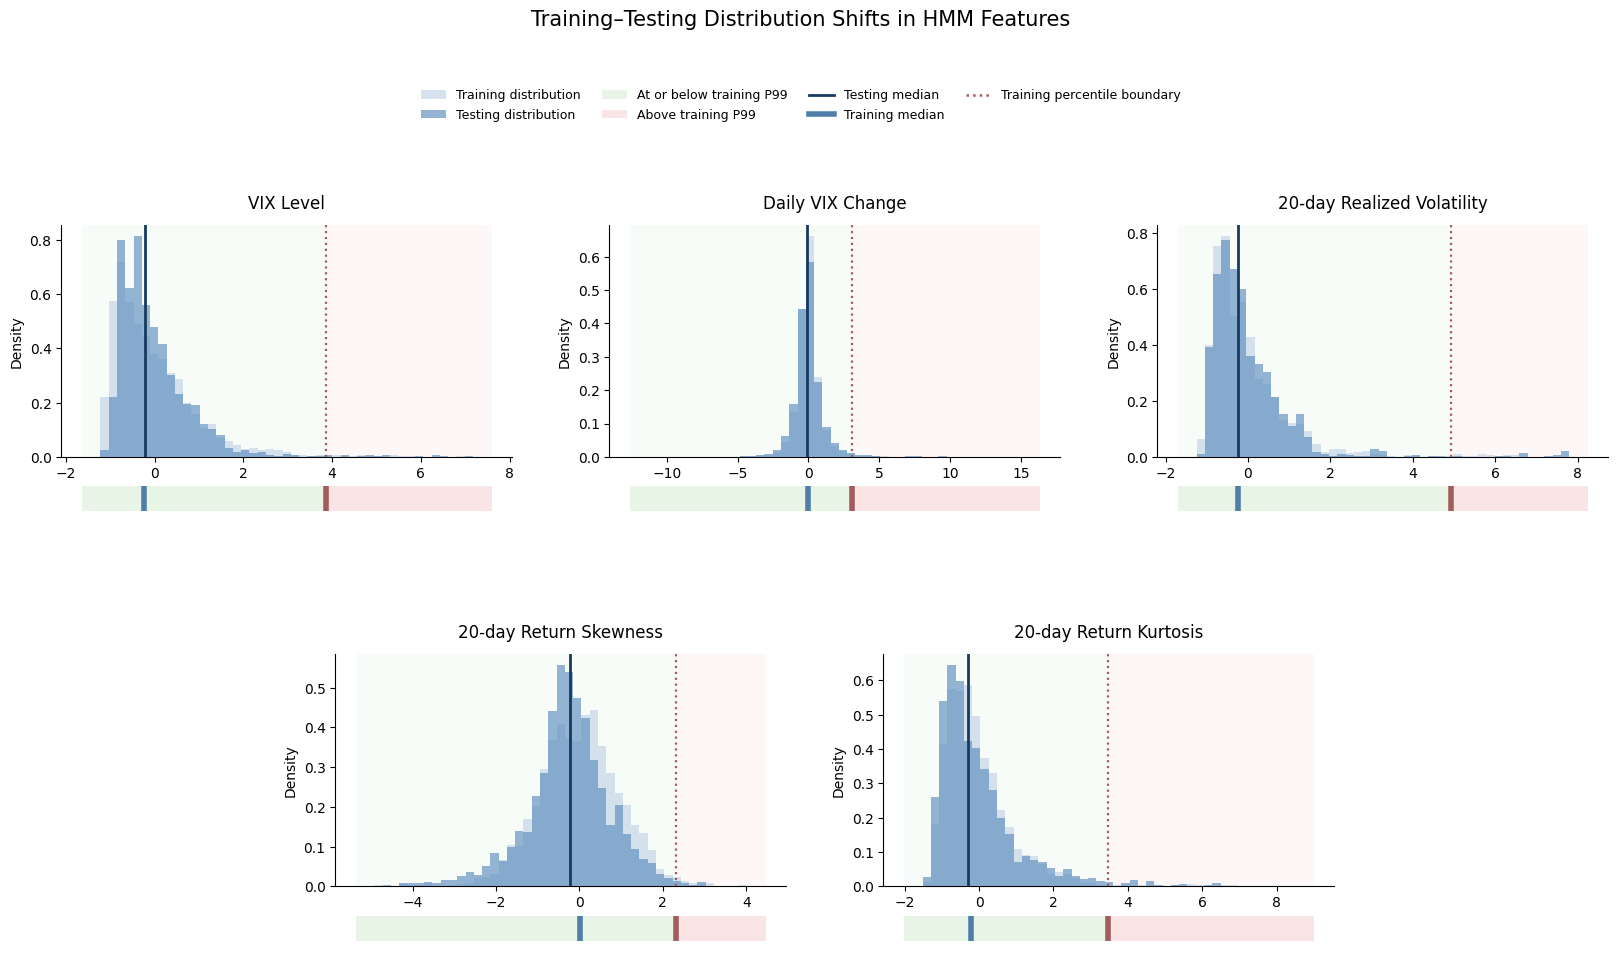

In [71]:
# --------------------------------------------------
# 8.2 Training–Testing Feature Distribution Comparison
#     Tail reference regions and matching percentile bars
# --------------------------------------------------

# --------------------------------------------------
# Configuration
# --------------------------------------------------

# "one-tailed": central area <= training 99th percentile
# "two-tailed": central area between training 1st and 99th percentiles
tail_mode = "one-tailed"

feature_labels = {
    "VIX_Level": "VIX Level",
    "VIX_Change": "Daily VIX Change",
    "Realized_Vol_20D": "20-day Realized Volatility",
    "Return_Skew_20D": "20-day Return Skewness",
    "Return_Kurt_20D": "20-day Return Kurtosis"
}

# Distribution colors
train_color = "#C9D9EA"
test_color = "#5B8DBD"

# Marker colors
train_median_color = "#4F7FA8"
test_median_color = "#173A5E"

# Background region colors
central_color = "#DCEFD9"   # Light green
tail_color = "#F6D7D7"      # Very light muted red

# Background shading opacity
central_alpha = 0.18
tail_alpha = 0.18

# Threshold color
threshold_color = "#A35B5B"

# --------------------------------------------------
# Standardize using training parameters
# --------------------------------------------------

train_mean = df_train[hmm_features].mean()
train_std = df_train[hmm_features].std(ddof=0)

train_standardized = (
    df_train[hmm_features] - train_mean
) / train_std

test_standardized = (
    df_test[hmm_features] - train_mean
) / train_std

# --------------------------------------------------
# Figure layout: Three top, two centered below
# --------------------------------------------------

fig_feature_distribution_shift = plt.figure(
    figsize=(17, 10.5)
)

gs = GridSpec(
    2, 6,
    figure=fig_feature_distribution_shift,
    hspace=0.85,
    wspace=0.55
)

axes_distribution = [
    fig_feature_distribution_shift.add_subplot(gs[0, 0:2]),
    fig_feature_distribution_shift.add_subplot(gs[0, 2:4]),
    fig_feature_distribution_shift.add_subplot(gs[0, 4:6]),
    fig_feature_distribution_shift.add_subplot(gs[1, 1:3]),
    fig_feature_distribution_shift.add_subplot(gs[1, 3:5])
]

# --------------------------------------------------
# Plot each market feature
# --------------------------------------------------

for feature, ax in zip(hmm_features, axes_distribution):

    train_data = train_standardized[feature].dropna()
    test_data = test_standardized[feature].dropna()

    combined = np.concatenate([
        train_data.to_numpy(),
        test_data.to_numpy()
    ])

    bins = np.histogram_bin_edges(combined, bins=45)

    # -----------------------------------------------
    # Reference values
    # -----------------------------------------------

    train_median = train_data.median()
    test_median = test_data.median()

    train_q01 = train_data.quantile(0.01)
    train_q99 = train_data.quantile(0.99)

    # -----------------------------------------------
    # Overlapping training/testing distributions
    # -----------------------------------------------

    ax.hist(
        train_data,
        bins=bins,
        density=True,
        color=train_color,
        alpha=0.75,
        zorder=2
    )

    ax.hist(
        test_data,
        bins=bins,
        density=True,
        color=test_color,
        alpha=0.65,
        zorder=3
    )

    # -----------------------------------------------
    # Reference regions
    # -----------------------------------------------

    x_min, x_max = ax.get_xlim()

    if tail_mode == "one-tailed":

        # Central region: at or below training P99
        ax.axvspan(
            x_min,
            train_q99,
            facecolor=central_color,
            alpha=central_alpha,
            linewidth=0,
            zorder=0
        )

        # Upper-tail region: above training P99
        ax.axvspan(
            train_q99,
            x_max,
            facecolor=tail_color,
            alpha=tail_alpha,
            linewidth=0,
            zorder=0
        )

    elif tail_mode == "two-tailed":

        # Lower-tail region
        ax.axvspan(
            x_min,
            train_q01,
            facecolor=tail_color,
            alpha=tail_alpha,
            linewidth=0,
            zorder=0
        )

        # Central reference region
        ax.axvspan(
            train_q01,
            train_q99,
            facecolor=central_color,
            alpha=central_alpha,
            linewidth=0,
            zorder=0
        )

        # Upper-tail region
        ax.axvspan(
            train_q99,
            x_max,
            facecolor=tail_color,
            alpha=tail_alpha,
            linewidth=0,
            zorder=0
        )

    else:
        raise ValueError(
            "tail_mode must be 'one-tailed' or 'two-tailed'"
        )

    # -----------------------------------------------
    # Dotted percentile threshold boundaries
    # -----------------------------------------------

    if tail_mode == "two-tailed":

        ax.axvline(
            train_q01,
            color=threshold_color,
            linestyle=":",
            linewidth=1.6,
            zorder=4
        )

    ax.axvline(
        train_q99,
        color=threshold_color,
        linestyle=":",
        linewidth=1.6,
        zorder=4
    )

    # -----------------------------------------------
    # Testing median on main histogram
    # -----------------------------------------------

    ax.axvline(
        test_median,
        color=test_median_color,
        linestyle="-",
        linewidth=2.0,
        zorder=5
    )

    # -----------------------------------------------
    # Histogram formatting
    # -----------------------------------------------

    ax.set_title(
        feature_labels[feature],
        fontsize=12,
        pad=12
    )

    ax.set_xlabel(
        "Standardized Feature Value",
        fontsize=10,
        labelpad=8
    )

    ax.set_ylabel(
        "Density",
        fontsize=10
    )

    ax.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # -----------------------------------------------
    # Matching reference bar underneath histogram
    # -----------------------------------------------

    strip_ax = ax.inset_axes([
        0.0,
        -0.27,
        1.0,
        0.18
    ])

    strip_ax.set_xlim(ax.get_xlim())
    strip_ax.set_ylim(0, 1)

    bar_bottom = 0.20
    bar_top = 0.80

    # Helper for colored horizontal segments
    def add_strip_region(start, end, color):

        strip_ax.fill_between(
            [start, end],
            bar_bottom,
            bar_top,
            color=color,
            alpha=0.65,
            linewidth=0,
            zorder=1
        )

    if tail_mode == "one-tailed":

        add_strip_region(
            x_min,
            train_q99,
            central_color
        )

        add_strip_region(
            train_q99,
            x_max,
            tail_color
        )

    else:

        add_strip_region(
            x_min,
            train_q01,
            tail_color
        )

        add_strip_region(
            train_q01,
            train_q99,
            central_color
        )

        add_strip_region(
            train_q99,
            x_max,
            tail_color
        )

    # -----------------------------------------------
    # Equal-size reference markers within the bar
    # -----------------------------------------------

    marker_width = 4.0

    # Training median: solid blue
    strip_ax.vlines(
        train_median,
        ymin=bar_bottom,
        ymax=bar_top,
        color=train_median_color,
        linewidth=marker_width,
        linestyle="-",
        zorder=3
    )

    # Training 99th percentile: solid red
    strip_ax.vlines(
        train_q99,
        ymin=bar_bottom,
        ymax=bar_top,
        color=threshold_color,
        linewidth=marker_width,
        linestyle="-",
        zorder=3
    )

    # Training 1st percentile, if two-tailed
    if tail_mode == "two-tailed":

        strip_ax.vlines(
            train_q01,
            ymin=bar_bottom,
            ymax=bar_top,
            color=threshold_color,
            linewidth=marker_width,
            linestyle="-",
            zorder=3
        )

    strip_ax.set_xticks([])
    strip_ax.set_yticks([])

    for spine in strip_ax.spines.values():
        spine.set_visible(False)

# --------------------------------------------------
# Legend
# --------------------------------------------------

central_label = (
    "At or below training P99"
    if tail_mode == "one-tailed"
    else "Training P1–P99 interval"
)

tail_label = (
    "Above training P99"
    if tail_mode == "one-tailed"
    else "Outside training P1–P99 interval"
)

legend_handles = [
    Patch(
        facecolor=train_color,
        alpha=0.75,
        label="Training distribution"
    ),
    Patch(
        facecolor=test_color,
        alpha=0.65,
        label="Testing distribution"
    ),
    Patch(
        facecolor=central_color,
        alpha=0.65,
        label=central_label
    ),
    Patch(
        facecolor=tail_color,
        alpha=0.65,
        label=tail_label
    ),
    Line2D(
        [0], [0],
        color=test_median_color,
        linewidth=2,
        label="Testing median"
    ),
    Line2D(
        [0], [0],
        color=train_median_color,
        linewidth=4,
        label="Training median"
    ),
    Line2D(
        [0], [0],
        color=threshold_color,
        linestyle=":",
        linewidth=1.8,
        label="Training percentile boundary"
    )
]

fig_feature_distribution_shift.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.92),
    ncol=4,
    frameon=False,
    fontsize=9,
    columnspacing=1.7
)

# --------------------------------------------------
# Title and figure layout
# --------------------------------------------------

fig_feature_distribution_shift.suptitle(
    "Training–Testing Distribution Shifts in HMM Features",
    fontsize=15,
    y=0.985
)

fig_feature_distribution_shift.subplots_adjust(
    left=0.065,
    right=0.975,
    bottom=0.15,
    top=0.78
)

plt.show()

**Key Observations**

**1. Average market volatility remained relatively stable between training and testing.**

Average VIX levels were 19.86 during training and 19.76 during testing, representing a standardized mean shift of only -0.012. Similarly, annualized 20-day realized volatility averaged approximately 16.34% during training and 16.37% during testing.

These findings indicate that the testing period did not exhibit a substantial shift in average volatility conditions. However, similar means do not necessarily imply that the complete distributions remained unchanged.

**2. Daily VIX changes became more variable during testing.**

The standard deviation of daily VIX changes increased from 1.66 to 2.13, representing an increase of approximately 28.2%.

Additionally, 3.23% of testing observations fell outside the training-period 1st–99th percentile interval, compared with approximately 2.04% during training.

This suggests that the testing period experienced greater variability in daily movements in expected market volatility, despite minimal differences in the average VIX change.

**3. Return skewness exhibited the most pronounced shift in average values.**

Average 20-day return skewness decreased from -0.041 during training to -0.206 during testing, equivalent to a standardized mean shift of approximately -0.260.

The lower-tail exceedance rate increased to 2.73%, while the upper-tail exceedance rate was only 0.65%. The combined testing exceedance rate reached 3.38%.

This indicates that unusually negative rolling skewness observations became more prevalent during testing. The finding is particularly relevant to the K-means benchmark, whose Transition cluster was strongly characterized by negative return skewness.

**4. Return kurtosis exhibited the highest overall tail-exceedance rate.**

Although average 20-day return kurtosis remained approximately unchanged at 0.47, its standard deviation increased from 1.41 to 1.62, representing an increase of approximately 14.8%.

The combined testing tail-exceedance rate reached 3.68%, with 1.74% of observations below the training 1st percentile and 1.94% above the 99th percentile.

These results suggest greater dispersion in rolling kurtosis measurements and more frequent observations outside the historical reference interval, even though average kurtosis remained stable.

**5. Extreme VIX levels and realized-volatility observations did not become more frequent relative to training thresholds.**

The proportions of testing observations outside the training reference intervals were 1.14% for VIX levels and 1.04% for 20-day realized volatility.

Both were below the approximately 2.04% observed during training.

Consequently, the clearest distributional changes involved daily VIX movements and rolling return-distribution characteristics rather than a generalized increase in observations with extreme volatility levels.

**Implications for Subsequent Modeling**

The analysis indicates that the testing period presented the HMM with somewhat different feature distributions, particularly in daily VIX changes, return skewness, and return kurtosis.

These changes may have influenced the combinations of market characteristics associated with inferred regimes. They are therefore relevant to the weaker testing-period geometric separation observed in the earlier HMM evaluation.

However, the analysis does not establish that distribution shifts caused the change in clustering performance. Additional diagnostics are needed to investigate whether regime assignments became less persistent, more fragmented, or concentrated around particular market episodes.

These findings motivate the temporal regime analysis in Section 8.3, followed by sensitivity analysis of the HMM specification.

**Methodological Considerations**

All standardized comparisons and percentile thresholds were derived from the training period. Testing observations were evaluated against these fixed references without re-estimating preprocessing parameters.

The tail-exceedance analysis used both the 1st and 99th percentile thresholds. When the accompanying visualization displays only the upper 99th-percentile region, that shading illustrates the upper-tail boundary rather than the complete two-tailed diagnostic.

These results are descriptive rather than formal statistical tests. Because financial observations and rolling features exhibit temporal dependence, tail-exceedance proportions should not be interpreted as independent observations.

Finally, the analysis examines individual feature distributions rather than their joint dependence structure.

### Section 8.3 - Regime Assignment and Temporal Diagnostics

This subsection evaluates the temporal stability of the Gaussian Hidden Markov Model (HMM) by examining the frequency, duration, and fragmentation of inferred market regimes across the training (2000–2017) and testing (2018–2025) periods.

Earlier evaluations established that the HMM produced persistent regime assignments, although its switching rate increased from 2.91% during training to 4.13% during testing. The feature-distribution analysis also identified changes in the variability and tail behavior of several HMM inputs.

To investigate temporal stability more directly, consecutive observations assigned to the same regime are grouped into distinct **regime episodes**. The resulting episode durations are measured in observed trading days and analyzed separately for Calm, Transition, and Stressed conditions.

Unlike the model-implied expected durations examined in Section 6, these diagnostics measure the lengths of actual runs within the decoded regime sequences. They also allow us to identify short-lived classifications that may indicate greater temporal fragmentation.

The analysis remains descriptive: HMM regimes are latent rather than externally observed, and retrospective decoding does not represent a real-time forecasting procedure.

| Subsection | Analysis | Objective |
|:---|:---|:---|
| **8.3.1** | Regime Episode Identification | Identify consecutive trading-day episodes assigned to the same HMM regime. |
| **8.3.2** | Episode Duration and Prevalence | Compare regime durations, frequency, and prevalence across training and testing periods. |
| **8.3.3** | Short-Lived Episode Analysis | Examine regime fragmentation through the frequency of episodes lasting one, three, or five trading days. |
| **8.3.4** | Temporal Diagnostics Visualization | Visualize episode-duration distributions and short-lived episode frequencies. |

In [73]:

# --------------------------------------------------
# 8.3.1 Identify Consecutive HMM Regime Episodes
# --------------------------------------------------

def identify_regime_episodes(regime_df, period_name):
    """
    Identify consecutive episodes of the same decoded HMM regime.

    Duration_Days measures observed trading days, not
    calendar days.
    """

    data = (
        regime_df[["Date", "Regime"]]
        .sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )

    # Identify the first observation of each new episode
    data["Episode_ID"] = (
        data["Regime"].ne(data["Regime"].shift())
    ).cumsum()

    # Summarize each uninterrupted regime sequence
    episodes = (
        data.groupby("Episode_ID", as_index=False)
        .agg(
            Regime=("Regime", "first"),
            Start_Date=("Date", "first"),
            End_Date=("Date", "last"),
            Duration_Days=("Date", "size")
        )
    )

    episodes["Period"] = period_name

    # Flag episodes touching the sample boundaries
    episodes["Left_Censored"] = False
    episodes["Right_Censored"] = False

    episodes.loc[
        episodes.index[0], "Left_Censored"
    ] = True

    episodes.loc[
        episodes.index[-1], "Right_Censored"
    ] = True

    return episodes[
        [
            "Period",
            "Episode_ID",
            "Regime",
            "Start_Date",
            "End_Date",
            "Duration_Days",
            "Left_Censored",
            "Right_Censored"
        ]
    ]


# --------------------------------------------------
# Identify training and testing episodes separately
# --------------------------------------------------

train_regime_episodes = identify_regime_episodes(
    df_train_regimes,
    "Training"
)

test_regime_episodes = identify_regime_episodes(
    df_test_regimes,
    "Testing"
)

regime_episodes_df = pd.concat(
    [train_regime_episodes, test_regime_episodes],
    ignore_index=True
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert train_regime_episodes["Duration_Days"].sum() == len(
    df_train_regimes
)

assert test_regime_episodes["Duration_Days"].sum() == len(
    df_test_regimes
)

assert set(regime_episodes_df["Regime"]) == set(regime_order)

assert (regime_episodes_df["Duration_Days"] >= 1).all()

# Verify correspondence with previously observed switches
assert len(train_regime_episodes) - 1 == int(
    model_comparison_df.loc["Gaussian HMM", "Regime_Switches"]
)

assert len(test_regime_episodes) - 1 == int(
    test_model_comparison_df.loc["Gaussian HMM", "Regime_Switches"]
)

# --------------------------------------------------
# Initial results
# --------------------------------------------------

print("HMM Regime Episode Identification")
print("-" * 45)

print(f"Training episodes: {len(train_regime_episodes):,}")
print(f"Testing episodes:  {len(test_regime_episodes):,}")

print("\nFirst five training episodes:")
display(train_regime_episodes.head())

print("\nFirst five testing episodes:")
display(test_regime_episodes.head())


HMM Regime Episode Identification
---------------------------------------------
Training episodes: 132
Testing episodes:  84

First five training episodes:


,Period,Episode_ID,Regime,Start_Date,End_Date,Duration_Days,Left_Censored,Right_Censored
0,Training,1,Transition,2000-02-01,2000-03-15,31,True,False
1,Training,2,Stressed,2000-03-16,2000-04-13,21,False,False
2,Training,3,Transition,2000-04-14,2000-04-24,6,False,False
3,Training,4,Stressed,2000-04-25,2000-06-26,44,False,False
4,Training,5,Transition,2000-06-27,2000-09-21,61,False,False



First five testing episodes:


,Period,Episode_ID,Regime,Start_Date,End_Date,Duration_Days,Left_Censored,Right_Censored
0,Testing,1,Transition,2018-01-02,2018-01-02,1,True,False
1,Testing,2,Calm,2018-01-03,2018-02-01,21,False,False
2,Testing,3,Transition,2018-02-02,2018-02-02,1,False,False
3,Testing,4,Stressed,2018-02-05,2018-02-05,1,False,False
4,Testing,5,Transition,2018-02-06,2018-03-21,31,False,False


**Key Observations:**

1. Episode identification is consistent with the earlier analysis. The number of episodes equals the number of regime switches plus one in each period, confirming that our episode-detection logic is working as expected.

2. The testing sample already contains examples of brief regime assignments. On February 2, 2018, the HMM assigned Transition for one trading day, followed by Stressed on February 5 and a return to Transition on February 6. This is a useful potential case for our later fragmentation analysis, although one example cannot establish a broader pattern.

3. Episode counts must be interpreted relative to sample length. The training sample contains more episodes overall, but it also covers considerably more trading days.

In [76]:

# --------------------------------------------------
# 8.3.2 HMM Regime Episode Duration Analysis
# --------------------------------------------------

# Summarize observed episode lengths by period and regime
regime_episode_duration_df = (
    regime_episodes_df
    .groupby(["Period", "Regime"])["Duration_Days"]
    .agg(
        Episode_Count="count",
        Mean_Duration="mean",
        Median_Duration="median",
        Std_Duration="std",
        Min_Duration="min",
        Max_Duration="max",
        Total_Trading_Days="sum"
    )
)

# Arrange periods and regimes consistently
period_order = ["Training", "Testing"]

regime_episode_duration_df = (
    regime_episode_duration_df
    .reindex(
        pd.MultiIndex.from_product(
            [period_order, regime_order],
            names=["Period", "Regime"]
        )
    )
)


# --------------------------------------------------
# Correct 8.3.2 Regime Share Calculation
# --------------------------------------------------

period_lengths = {
    "Training": len(df_train_regimes),
    "Testing": len(df_test_regimes)
}

# Map each row to its corresponding period length
period_denominators = (
    regime_episode_duration_df.index
    .get_level_values("Period")
    .map(period_lengths)
)

regime_episode_duration_df["Regime_Share_Pct"] = (
    regime_episode_duration_df["Total_Trading_Days"].to_numpy()
    / np.asarray(period_denominators, dtype=float)
    * 100
)

# Validate that regime shares sum to 100% in each period
assert np.allclose(
    regime_episode_duration_df
    .groupby(level="Period")["Regime_Share_Pct"]
    .sum()
    .to_numpy(),
    100.0
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert (
    regime_episode_duration_df.loc[
        "Training", "Total_Trading_Days"
    ].sum()
    == len(df_train_regimes)
)

assert (
    regime_episode_duration_df.loc[
        "Testing", "Total_Trading_Days"
    ].sum()
    == len(df_test_regimes)
)

assert (
    regime_episode_duration_df.loc[
        "Training", "Episode_Count"
    ].sum()
    == len(train_regime_episodes)
)

assert (
    regime_episode_duration_df.loc[
        "Testing", "Episode_Count"
    ].sum()
    == len(test_regime_episodes)
)

# --------------------------------------------------
# Display results
# --------------------------------------------------

print("HMM Regime Episode Durations — Training vs. Testing")
print("Durations measured in observed trading days.\n")

display(
    regime_episode_duration_df[
        [
            "Episode_Count",
            "Mean_Duration",
            "Median_Duration",
            "Std_Duration",
            "Min_Duration",
            "Max_Duration",
            "Regime_Share_Pct"
        ]
    ].round(2)
)

HMM Regime Episode Durations — Training vs. Testing
Durations measured in observed trading days.



Episode_Count  Mean_Duration  Median_Duration  Std_Duration  Min_Duration  Max_Duration  Regime_Share_Pct
Period   Regime                                                                                                               
Training Calm                   45          35.60             20.0         37.96             1           173             35.54
         Transition             57          30.05             20.0         29.12             2           138             38.00
         Stressed               30          39.77             21.5         45.69             1           195             26.46
Testing  Calm                   25          24.76             17.0         22.90             6           106             30.78
         Transition             39          25.33             24.0         17.06             1            76             49.13
         Stressed               20          20.20              9.0         23.90             1            75             20.09

**Key Observation:**

The HMM exhibited shorter regime episodes during testing, particularly for the Stressed regime, whose mean duration declined from 39.77 to 20.20 trading days (−49.2%) and median duration fell from 21.5 to 9 days. Calm episodes also shortened, while Transition episodes remained comparatively stable despite becoming more prevalent (49.13% of testing observations). These findings suggest reduced persistence of Stressed regime assignments outside training, motivating further investigation into short-lived episodes and temporal fragmentation.

In [77]:

# --------------------------------------------------
# 8.3.3 Short-Lived HMM Regime Episode Analysis
# --------------------------------------------------

short_episode_records = []

period_order = ["Training", "Testing"]
short_thresholds = [1, 3, 5]

for period in period_order:

    for regime in regime_order:

        episodes = regime_episodes_df.loc[
            (regime_episodes_df["Period"] == period)
            & (regime_episodes_df["Regime"] == regime)
        ].copy()

        durations = episodes["Duration_Days"]

        result = {
            "Period": period,
            "Regime": regime,
            "Total_Episodes": len(episodes),
            "Total_Trading_Days": durations.sum()
        }

        for threshold in short_thresholds:

            short_mask = durations <= threshold

            result[f"Episodes_Le_{threshold}D"] = int(
                short_mask.sum()
            )

            result[f"Episode_Share_Le_{threshold}D_Pct"] = (
                short_mask.mean() * 100
            )

            result[f"Trading_Day_Share_Le_{threshold}D_Pct"] = (
                durations.loc[short_mask].sum()
                / durations.sum()
                * 100
            )

        short_episode_records.append(result)

short_episode_df = (
    pd.DataFrame(short_episode_records)
    .set_index(["Period", "Regime"])
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert short_episode_df["Total_Episodes"].sum() == len(
    regime_episodes_df
)

for threshold in short_thresholds:

    episode_share = short_episode_df[
        f"Episode_Share_Le_{threshold}D_Pct"
    ]

    trading_day_share = short_episode_df[
        f"Trading_Day_Share_Le_{threshold}D_Pct"
    ]

    assert episode_share.between(0, 100).all()
    assert trading_day_share.between(0, 100).all()

# Short-lived episode counts must be cumulative
assert (
    short_episode_df["Episodes_Le_1D"]
    <= short_episode_df["Episodes_Le_3D"]
).all()

assert (
    short_episode_df["Episodes_Le_3D"]
    <= short_episode_df["Episodes_Le_5D"]
).all()

# --------------------------------------------------
# Results
# --------------------------------------------------

print("Short-Lived HMM Regime Episodes")
print("Thresholds: 1, 3, and 5 trading days or fewer.\n")

display(
    short_episode_df[
        [
            "Total_Episodes",
            "Episodes_Le_1D",
            "Episode_Share_Le_1D_Pct",
            "Episodes_Le_3D",
            "Episode_Share_Le_3D_Pct",
            "Episodes_Le_5D",
            "Episode_Share_Le_5D_Pct",
            "Trading_Day_Share_Le_5D_Pct"
        ]
    ].round(2)
)

Short-Lived HMM Regime Episodes
Thresholds: 1, 3, and 5 trading days or fewer.



Total_Episodes  Episodes_Le_1D  Episode_Share_Le_1D_Pct  Episodes_Le_3D  Episode_Share_Le_3D_Pct  Episodes_Le_5D  Episode_Share_Le_5D_Pct  Trading_Day_Share_Le_5D_Pct
Period   Regime                                                                                                                                                                            
Training Calm                    45               1                     2.22               2                     4.44               4                     8.89                         0.81
         Transition              57               0                     0.00               2                     3.51               6                    10.53                         1.46
         Stressed                30               2                     6.67               3                    10.00               4                    13.33                         0.84
Testing  Calm                    25               0                     0.00               0                     0.00               0                     0.00                         0.00
         Transition              39               2                     5.13               3                     7.69               3                     7.69                         0.40
         Stressed                20               2                    10.00               3                    15.00               5                    25.00                         3.71

**Key Observation**

1. Stressed regimes became more fragmented. The proportion of Stressed episodes lasting five trading days or fewer increased from 13.33% (4 of 30 episodes) during training to 25.00% (5 of 20 episodes) during testing. This reinforces the earlier finding that their median duration fell from 21.5 to 9 days.

2. Calm regimes became less fragmented. No Calm episodes lasted five days or fewer during testing, compared with 8.89% during training.

3. Brief episodes accounted for a small proportion of trading days. Even for Stressed regimes, episodes lasting five days or fewer represented only 3.71% of Stressed trading days during testing, compared with 0.84% during training. Most Stressed observations therefore remained concentrated in longer episodes.

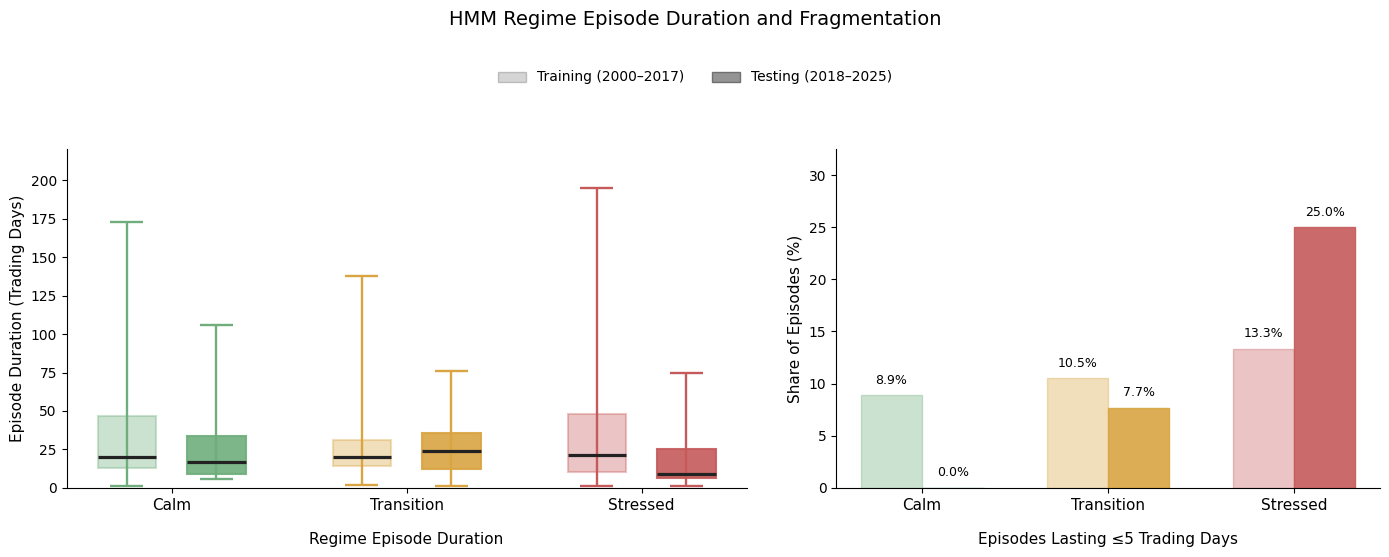

In [82]:

# --------------------------------------------------
# 8.3.4 HMM Regime Duration and Fragmentation
#     Candlestick-style comparison — simplified layout
# --------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle, Patch

# --------------------------------------------------
# Colors and ordering
# --------------------------------------------------

regime_colors = {
    "Calm": "#6FAE7C",
    "Transition": "#D9A441",
    "Stressed": "#C65A5A"
}

regime_order = ["Calm", "Transition", "Stressed"]
period_order = ["Training", "Testing"]

# --------------------------------------------------
# Episode-duration candle statistics
# --------------------------------------------------

duration_candle_df = (
    regime_episodes_df
    .groupby(["Period", "Regime"])["Duration_Days"]
    .agg(
        Minimum="min",
        Q1=lambda values: values.quantile(0.25),
        Median="median",
        Q3=lambda values: values.quantile(0.75),
        Maximum="max"
    )
    .reindex(
        pd.MultiIndex.from_product(
            [period_order, regime_order],
            names=["Period", "Regime"]
        )
    )
)

assert duration_candle_df.notna().all().all()

# Short-lived episode proportions
short_share = short_episode_df[
    "Episode_Share_Le_5D_Pct"
]

# --------------------------------------------------
# Figure setup
# --------------------------------------------------

fig_hmm_temporal_diagnostics, (
    ax_duration,
    ax_fragmentation
) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.25, 1]}
)

x = np.arange(len(regime_order))

# --------------------------------------------------
# Panel 1: Episode duration candlesticks
# --------------------------------------------------

offset = 0.19
candle_width = 0.25

for i, regime in enumerate(regime_order):

    color = regime_colors[regime]

    for period, dx, opacity in [
        ("Training", -offset, 0.35),
        ("Testing", offset, 0.90)
    ]:

        stats = duration_candle_df.loc[(period, regime)]
        position = x[i] + dx

        minimum = stats["Minimum"]
        q1 = stats["Q1"]
        median = stats["Median"]
        q3 = stats["Q3"]
        maximum = stats["Maximum"]

        # Observed minimum-to-maximum range
        ax_duration.vlines(
            position,
            minimum,
            maximum,
            color=color,
            linewidth=1.7,
            zorder=2
        )

        # Minimum and maximum caps
        ax_duration.hlines(
            [minimum, maximum],
            position - candle_width * 0.28,
            position + candle_width * 0.28,
            color=color,
            linewidth=1.7,
            zorder=2
        )

        # Candle body: interquartile range
        candle = Rectangle(
            (position - candle_width / 2, q1),
            candle_width,
            q3 - q1,
            facecolor=color,
            edgecolor=color,
            alpha=opacity,
            linewidth=1.5,
            zorder=3
        )

        ax_duration.add_patch(candle)

        # Median line retained inside the candle
        # Numerical median annotations removed
        ax_duration.hlines(
            median,
            position - candle_width / 2,
            position + candle_width / 2,
            color="#222222",
            linewidth=2.3,
            zorder=4
        )

ax_duration.set_xticks(x)
ax_duration.set_xticklabels(
    regime_order,
    fontsize=11
)

ax_duration.set_ylabel(
    "Episode Duration (Trading Days)",
    fontsize=11
)

ax_duration.set_xlabel(
    "Regime Episode Duration",
    fontsize=11,
    labelpad=14
)

ax_duration.set_ylim(
    0,
    duration_candle_df["Maximum"].max() * 1.13
)

# --------------------------------------------------
# Panel 2: Short-lived episode proportions
# --------------------------------------------------

bar_width = 0.33

for i, regime in enumerate(regime_order):

    color = regime_colors[regime]

    for period, dx, opacity in [
        ("Training", -bar_width / 2, 0.35),
        ("Testing", bar_width / 2, 0.90)
    ]:

        value = short_share.loc[(period, regime)]

        ax_fragmentation.bar(
            x[i] + dx,
            value,
            width=bar_width,
            color=color,
            alpha=opacity,
            edgecolor=color,
            linewidth=1.0
        )

        # Retain fragmentation percentage annotations
        ax_fragmentation.annotate(
            f"{value:.1f}%",
            xy=(x[i] + dx, value),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax_fragmentation.set_xticks(x)
ax_fragmentation.set_xticklabels(
    regime_order,
    fontsize=11
)

ax_fragmentation.set_ylabel(
    "Share of Episodes (%)",
    fontsize=11
)

ax_fragmentation.set_xlabel(
    "Episodes Lasting ≤5 Trading Days",
    fontsize=11,
    labelpad=14
)

ax_fragmentation.set_ylim(
    0,
    max(short_share.max() * 1.30, 5)
)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

legend_handles = [
    Patch(
        facecolor="#888888",
        alpha=0.35,
        edgecolor="#666666",
        label="Training (2000–2017)"
    ),
    Patch(
        facecolor="#888888",
        alpha=0.90,
        edgecolor="#666666",
        label="Testing (2018–2025)"
    )
]

fig_hmm_temporal_diagnostics.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.90),
    ncol=2,
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# Overall styling
# --------------------------------------------------

fig_hmm_temporal_diagnostics.suptitle(
    "HMM Regime Episode Duration and Fragmentation",
    fontsize=14,
    y=0.98
)

for ax in [ax_duration, ax_fragmentation]:

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig_hmm_temporal_diagnostics.tight_layout(
    rect=[0, 0.06, 1, 0.83],
    w_pad=3
)

plt.show()

In [84]:

# --------------------------------------------------
# 8.3 Compact HMM Temporal Diagnostics Summary
# --------------------------------------------------

# Select the most informative duration statistics
duration_compact = regime_episode_duration_df[
    [
        "Episode_Count",
        "Mean_Duration",
        "Median_Duration",
        "Max_Duration"
    ]
].copy()

# Add short-lived episode frequency
fragmentation_compact = short_episode_df[
    ["Episode_Share_Le_5D_Pct"]
].copy()

# Combine results
hmm_temporal_summary_df = duration_compact.join(
    fragmentation_compact,
    validate="one_to_one"
)

# Rename columns for readability
hmm_temporal_summary_df = hmm_temporal_summary_df.rename(
    columns={
        "Episode_Count": "Episodes",
        "Mean_Duration": "Mean_Days",
        "Median_Duration": "Median_Days",
        "Max_Duration": "Max_Days",
        "Episode_Share_Le_5D_Pct": "Short_Episodes_≤5D_Pct"
    }
)

# Arrange regimes together for easier comparison
hmm_temporal_summary_df = hmm_temporal_summary_df.reindex(
    pd.MultiIndex.from_product(
        [regime_order, ["Training", "Testing"]],
        names=["Regime", "Period"]
    ),
    level=None
) if False else hmm_temporal_summary_df.reorder_levels(
    ["Regime", "Period"]
).reindex(
    pd.MultiIndex.from_product(
        [regime_order, ["Training", "Testing"]],
        names=["Regime", "Period"]
    )
)

# Validation
assert hmm_temporal_summary_df.shape == (6, 5)
assert hmm_temporal_summary_df.notna().all().all()

print("HMM Temporal Diagnostics — Compact Summary")
display(hmm_temporal_summary_df.round(2))

HMM Temporal Diagnostics — Compact Summary


Episodes  Mean_Days  Median_Days  Max_Days  Short_Episodes_≤5D_Pct
Regime     Period                                                                      
Calm       Training        45      35.60         20.0       173                    8.89
           Testing         25      24.76         17.0       106                    0.00
Transition Training        57      30.05         20.0       138                   10.53
           Testing         39      25.33         24.0        76                    7.69
Stressed   Training        30      39.77         21.5       195                   13.33
           Testing         20      20.20          9.0        75                   25.00

**Key Observation**
The Stressed regime shows the strongest change, with median episode duration declining from 21.5 to 9 days and short-lived episodes increasing from 13.33% to 25.00%.

### Section 8.4 - HMM Sensitivity Analysis

This subsection evaluates the sensitivity of the Gaussian Hidden Markov Model (HMM) to alternative modeling specifications, focusing on the number of hidden states and the selected market features.

The baseline model uses three hidden states, full covariance matrices, and five standardized market characteristics: VIX level, daily VIX change, 20-day realized volatility, 20-day return skewness, and 20-day return kurtosis.

Earlier model-selection results showed that the Bayesian Information Criterion (BIC) continued decreasing as the number of hidden states increased from two to six. The three-state specification was therefore retained primarily for economic interpretability rather than because it minimized BIC.

The sensitivity analysis examines whether the model's clustering quality, temporal persistence, and regime assignments remain stable under alternative specifications.

All alternative models will be estimated using the training period (2000–2017), with the existing testing period (2018–2025) reserved for out-of-sample evaluation. The original three-state HMM remains unchanged.

| Subsection | Analysis | Objective |
|:---|:---|:---|
| **8.4.1** | Baseline HMM Specification | Validate the original three-state HMM and establish its reference performance. |
| **8.4.2** | Hidden-State Sensitivity | Compare two- to six-state HMM specifications to assess model fit, separation, and temporal persistence. |
| **8.4.3** | Feature Ablation Analysis | Evaluate how removing individual input features affects regime assignments and model stability. |

In [85]:
# --------------------------------------------------
# 8.4.1 Baseline HMM Specification and Validation
# --------------------------------------------------

baseline_hmm_spec = pd.Series({
    "Model": "Gaussian HMM",
    "Hidden_States": hmm_model.n_components,
    "Covariance_Type": hmm_model.covariance_type,
    "Features": len(hmm_features),
    "Training_Observations": len(df_train),
    "Testing_Observations": len(df_test),
    "Training_Log_Likelihood": hmm_model.score(X_train_scaled),
    "Testing_Log_Likelihood": hmm_model.score(X_test_scaled),
    "Training_Silhouette": model_comparison_df.loc[
        "Gaussian HMM", "Silhouette"
    ],
    "Testing_Silhouette": test_model_comparison_df.loc[
        "Gaussian HMM", "Silhouette"
    ],
    "Training_Switch_Rate_Pct": model_comparison_df.loc[
        "Gaussian HMM", "Switch_Rate_Pct"
    ],
    "Testing_Switch_Rate_Pct": test_model_comparison_df.loc[
        "Gaussian HMM", "Switch_Rate_Pct"
    ]
})

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert hmm_model.n_components == 3
assert hmm_model.covariance_type == "full"

assert X_train_scaled.shape == (
    len(df_train), len(hmm_features)
)

assert X_test_scaled.shape == (
    len(df_test), len(hmm_features)
)

assert np.isfinite(
    baseline_hmm_spec[
        [
            "Training_Log_Likelihood",
            "Testing_Log_Likelihood",
            "Training_Silhouette",
            "Testing_Silhouette",
            "Training_Switch_Rate_Pct",
            "Testing_Switch_Rate_Pct"
        ]
    ].to_numpy(dtype=float)
).all()

# --------------------------------------------------
# Display results
# --------------------------------------------------

print("Baseline Gaussian HMM Specification\n")

display(
    baseline_hmm_spec.to_frame(
        name="Baseline_Value"
    )
)

print("\nBaseline HMM input features:")
for feature in hmm_features:
    print(f"  - {feature}")


Baseline Gaussian HMM Specification



,Baseline_Value
Model,Gaussian HMM
Hidden_States,3
Covariance_Type,full
Features,5
Training_Observations,4508
Testing_Observations,2011
Training_Log_Likelihood,-19896.459653
Testing_Log_Likelihood,-10737.749287
Training_Silhouette,0.121201
Testing_Silhouette,0.055644



Baseline HMM input features:
  - VIX_Level
  - VIX_Change
  - Realized_Vol_20D
  - Return_Skew_20D
  - Return_Kurt_20D


In [86]:

# --------------------------------------------------
# 8.4.2 HMM Sensitivity to Number of Hidden States
# --------------------------------------------------

state_sensitivity_records = []

for k in range(2, 7):

    model = candidate_models[k]

    # Existing training-fitted model
    assert model.n_components == k
    assert model.monitor_.converged

    # Retrospective state assignments for each period
    train_labels = model.predict(X_train_scaled)
    test_labels = model.predict(X_test_scaled)

    # Reuse Section 7.7 clustering evaluation
    train_metrics = evaluate_clustering(
        train_labels,
        X_train_scaled,
        f"HMM_{k}"
    )

    test_metrics = evaluate_clustering(
        test_labels,
        X_test_scaled,
        f"HMM_{k}"
    )

    # Average log-likelihood per observation
    train_ll_per_obs = (
        model.score(X_train_scaled) / len(X_train_scaled)
    )

    test_ll_per_obs = (
        model.score(X_test_scaled) / len(X_test_scaled)
    )

    # Minimum state prevalence in each period
    train_counts = np.bincount(
        train_labels,
        minlength=k
    )

    test_counts = np.bincount(
        test_labels,
        minlength=k
    )

    state_sensitivity_records.append({
        "States": k,
        "Baseline": k == 3,
        "Train_BIC": calculate_hmm_bic(
            model, X_train_scaled
        ),
        "Train_LL_Per_Obs": train_ll_per_obs,
        "Test_LL_Per_Obs": test_ll_per_obs,
        "Train_Silhouette": train_metrics["Silhouette"],
        "Test_Silhouette": test_metrics["Silhouette"],
        "Train_Davies_Bouldin": train_metrics["Davies_Bouldin"],
        "Test_Davies_Bouldin": test_metrics["Davies_Bouldin"],
        "Train_Switch_Rate_Pct": train_metrics["Switch_Rate_Pct"],
        "Test_Switch_Rate_Pct": test_metrics["Switch_Rate_Pct"],
        "Train_Min_State_Share_Pct": (
            train_counts.min() / len(train_labels) * 100
        ),
        "Test_Min_State_Share_Pct": (
            test_counts.min() / len(test_labels) * 100
        )
    })

hmm_state_sensitivity_df = (
    pd.DataFrame(state_sensitivity_records)
    .set_index("States")
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert list(hmm_state_sensitivity_df.index) == list(range(2, 7))
assert hmm_state_sensitivity_df.drop(
    columns="Baseline"
).notna().all().all()

# Confirm three-state results match the existing baseline
assert np.isclose(
    hmm_state_sensitivity_df.loc[3, "Train_Silhouette"],
    model_comparison_df.loc["Gaussian HMM", "Silhouette"]
)

assert np.isclose(
    hmm_state_sensitivity_df.loc[3, "Test_Silhouette"],
    test_model_comparison_df.loc["Gaussian HMM", "Silhouette"]
)

# --------------------------------------------------
# Display results
# --------------------------------------------------

print("HMM State-Count Sensitivity — Training vs. Testing")
print("Baseline specification: 3 states\n")

display(hmm_state_sensitivity_df.round(4))

HMM State-Count Sensitivity — Training vs. Testing
Baseline specification: 3 states



,Baseline,Train_BIC,Train_LL_Per_Obs,Test_LL_Per_Obs,Train_Silhouette,Test_Silhouette,Train_Davies_Bouldin,Test_Davies_Bouldin,Train_Switch_Rate_Pct,Test_Switch_Rate_Pct,Train_Min_State_Share_Pct,Test_Min_State_Share_Pct
States,,,,,,,,,,,,
2,False,45715.9603,-5.0304,-6.0849,0.2456,0.1726,1.6435,2.2706,0.9984,1.9403,38.0435,40.9249
3,True,40365.0447,-4.4136,-5.3395,0.1212,0.0556,1.8834,2.1578,2.9066,4.1294,26.4641,20.0895
4,False,37135.7724,-4.0302,-4.7540,0.1170,0.0738,1.8454,1.9600,3.9938,5.8706,11.3576,12.2327
5,False,34668.9769,-3.7296,-4.8558,0.0852,0.0148,1.8521,2.2115,3.9272,5.6219,9.2946,10.0945
6,False,32894.9578,-3.5039,-4.5644,0.0650,0.0127,2.1061,2.4239,4.5263,6.6169,7.7196,7.4092


**Key Observations:**
The HMM exhibited a clear tradeoff between statistical fit, geometric separation, and temporal persistence. Training BIC decreased consistently as the number of hidden states increased from two to six, while the six-state model achieved the strongest testing log-likelihood per observation (-4.5644). However, the two-state specification produced the highest testing Silhouette Score (0.1726), compared with 0.0556 for the three-state baseline. Increasing model complexity also generally raised switching rates and reduced minimum state prevalence.

These findings indicate that additional states improve the model's flexibility without consistently producing more distinct or persistent regimes. The three-state specification remains a defensible choice for the project's economic interpretation of Calm, Transition, and Stressed conditions, although it is not optimal across the statistical evaluation criteria.

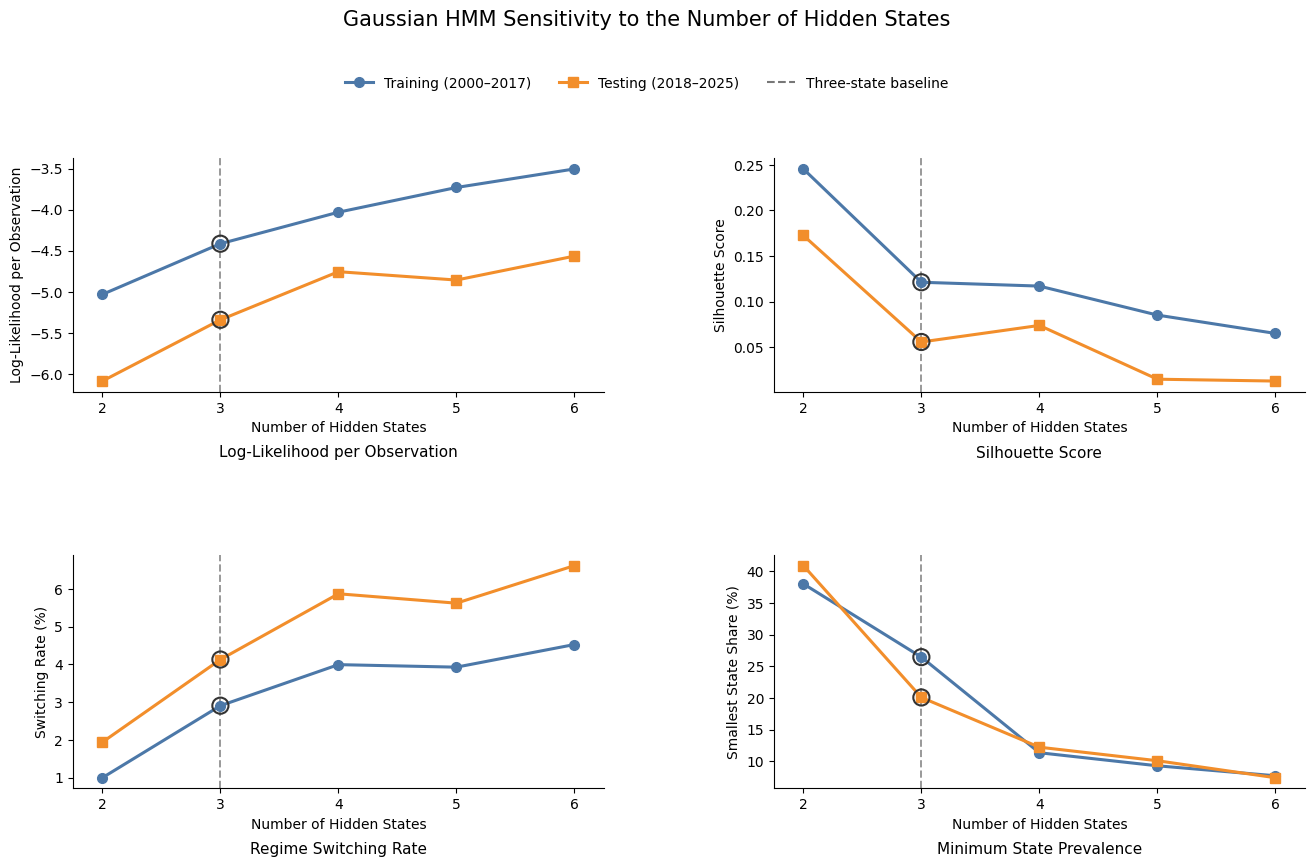

In [87]:

# --------------------------------------------------
# 8.4.2 HMM State-Count Sensitivity Visualization
#     Training vs. Testing (2–6 Hidden States)
# --------------------------------------------------

# --------------------------------------------------
# Visual configuration
# --------------------------------------------------

train_color = "#4C78A8"
test_color = "#F28E2B"
baseline_color = "#777777"

states = hmm_state_sensitivity_df.index.to_numpy()

metrics = [
    (
        "Train_LL_Per_Obs",
        "Test_LL_Per_Obs",
        "Log-Likelihood per Observation",
        "Log-Likelihood per Observation"
    ),
    (
        "Train_Silhouette",
        "Test_Silhouette",
        "Silhouette Score",
        "Silhouette Score"
    ),
    (
        "Train_Switch_Rate_Pct",
        "Test_Switch_Rate_Pct",
        "Regime Switching Rate",
        "Switching Rate (%)"
    ),
    (
        "Train_Min_State_Share_Pct",
        "Test_Min_State_Share_Pct",
        "Minimum State Prevalence",
        "Smallest State Share (%)"
    )
]

# --------------------------------------------------
# Figure setup
# --------------------------------------------------

fig_hmm_state_sensitivity, axes_sensitivity = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

axes_sensitivity = axes_sensitivity.flatten()

# --------------------------------------------------
# Plot each evaluation metric
# --------------------------------------------------

for ax, (
    train_metric,
    test_metric,
    panel_title,
    y_label
) in zip(axes_sensitivity, metrics):

    train_values = hmm_state_sensitivity_df[
        train_metric
    ].to_numpy()

    test_values = hmm_state_sensitivity_df[
        test_metric
    ].to_numpy()

    # Training series
    ax.plot(
        states,
        train_values,
        color=train_color,
        linewidth=2.2,
        marker="o",
        markersize=7,
        label="Training (2000–2017)",
        zorder=3
    )

    # Testing series
    ax.plot(
        states,
        test_values,
        color=test_color,
        linewidth=2.2,
        marker="s",
        markersize=7,
        label="Testing (2018–2025)",
        zorder=3
    )

    # Selected three-state baseline
    ax.axvline(
        3,
        color=baseline_color,
        linestyle="--",
        linewidth=1.4,
        alpha=0.75,
        zorder=1
    )

    # Highlight baseline observations
    ax.scatter(
        [3, 3],
        [
            hmm_state_sensitivity_df.loc[
                3, train_metric
            ],
            hmm_state_sensitivity_df.loc[
                3, test_metric
            ]
        ],
        s=135,
        facecolors="none",
        edgecolors="#333333",
        linewidths=1.5,
        zorder=5
    )

    ax.set_xticks(states)
    ax.set_xlim(1.75, 6.25)

    ax.set_xlabel(
        "Number of Hidden States",
        fontsize=10
    )

    ax.set_ylabel(
        y_label,
        fontsize=10
    )

    # Individual metric heading below the graph
    ax.set_title("")
    ax.text(
        0.5,
        -0.23,
        panel_title,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="medium"
    )

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        color=train_color,
        marker="o",
        linewidth=2.2,
        markersize=7,
        label="Training (2000–2017)"
    ),
    Line2D(
        [0], [0],
        color=test_color,
        marker="s",
        linewidth=2.2,
        markersize=7,
        label="Testing (2018–2025)"
    ),
    Line2D(
        [0], [0],
        color=baseline_color,
        linestyle="--",
        linewidth=1.5,
        label="Three-state baseline"
    )
]

fig_hmm_state_sensitivity.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=3,
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# Overall formatting
# --------------------------------------------------

fig_hmm_state_sensitivity.suptitle(
    "Gaussian HMM Sensitivity to the Number of Hidden States",
    fontsize=15,
    y=0.985
)

fig_hmm_state_sensitivity.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.12,
    top=0.82,
    hspace=0.70,
    wspace=0.32
)

plt.show()


**Key Observations:**

- **Statistical fit improved with additional states:** Training BIC decreased consistently from 45,715.96 (2 states) to 32,894.96 (6 states), while the six-state model achieved the highest testing log-likelihood per observation (-4.5644).
- **Geometric separation generally weakened:** The two-state model achieved the highest testing Silhouette Score (0.1726), compared with 0.0556 for the three-state baseline and 0.0127 for the six-state model.
- **Regime switching increased with model complexity:** Testing switching rates generally increased from 1.94% (2 states) to 6.62% (6 states), indicating less persistent classifications.
- **Smaller states emerged:** The minimum testing state prevalence declined from 40.92% (2 states) to 7.41% (6 states), potentially complicating economic interpretation.
- **Three-state selection remains an interpretability tradeoff:** Although not statistically optimal across the evaluated metrics, the baseline supports the economically meaningful Calm, Transition, and Stressed framework while maintaining moderate temporal persistence.


In [88]:

# --------------------------------------------------
# 8.4.3 HMM Feature Ablation — Experimental Setup
# --------------------------------------------------

# Preserve the original five-feature specification
baseline_features = hmm_features.copy()

# Define one alternative for each excluded feature
hmm_ablation_specs = {
    f"Without_{removed_feature}": [
        feature
        for feature in baseline_features
        if feature != removed_feature
    ]
    for removed_feature in baseline_features
}

# --------------------------------------------------
# Validate feature subsets and data alignment
# --------------------------------------------------

assert len(baseline_features) == 5
assert len(hmm_ablation_specs) == 5

for specification, selected_features in hmm_ablation_specs.items():

    assert len(selected_features) == 4
    assert set(selected_features).issubset(
        set(baseline_features)
    )

    assert set(selected_features).issubset(
        set(df_train.columns)
    )

    assert set(selected_features).issubset(
        set(df_test.columns)
    )

# Confirm original HMM remains unchanged
assert hmm_model.n_components == 3
assert hmm_model.covariance_type == "full"

# --------------------------------------------------
# Display experimental design
# --------------------------------------------------

hmm_ablation_design_df = pd.DataFrame([
    {
        "Specification": specification,
        "Excluded_Feature": removed_feature,
        "Remaining_Features": ", ".join(selected_features),
        "Feature_Count": len(selected_features)
    }
    for removed_feature, (specification, selected_features)
    in zip(baseline_features, hmm_ablation_specs.items())
]).set_index("Specification")

print("HMM Feature Ablation — Experimental Specifications\n")

display(hmm_ablation_design_df)


HMM Feature Ablation — Experimental Specifications



,Excluded_Feature,Remaining_Features,Feature_Count
Specification,,,
Without_VIX_Level,VIX_Level,"VIX_Change, Realized_Vol_20D, Return_Skew_20D,...",4
Without_VIX_Change,VIX_Change,"VIX_Level, Realized_Vol_20D, Return_Skew_20D, ...",4
Without_Realized_Vol_20D,Realized_Vol_20D,"VIX_Level, VIX_Change, Return_Skew_20D, Return...",4
Without_Return_Skew_20D,Return_Skew_20D,"VIX_Level, VIX_Change, Realized_Vol_20D, Retur...",4
Without_Return_Kurt_20D,Return_Kurt_20D,"VIX_Level, VIX_Change, Realized_Vol_20D, Retur...",4


In [89]:

# --------------------------------------------------
# 8.4.3.1 HMM Feature Ablation — Model Estimation
# --------------------------------------------------

# --------------------------------------------------
# Experimental configuration
# --------------------------------------------------

ablation_seeds = [42, 123, 456]
ablation_n_iter = 300
ablation_tol = 1e-3

# Preserve the original fitted model and scaler.
# X_train_scaled and X_test_scaled already use
# training-fitted standardization.

hmm_ablation_models = {}
hmm_ablation_data = {}
ablation_fit_records = []

# --------------------------------------------------
# Fit each four-feature specification
# --------------------------------------------------

for specification, selected_features in hmm_ablation_specs.items():

    print(f"Fitting: {specification}")

    # Select columns from the existing scaled arrays
    feature_indices = [
        hmm_features.index(feature)
        for feature in selected_features
    ]

    X_train_ablation = X_train_scaled[:, feature_indices]
    X_test_ablation = X_test_scaled[:, feature_indices]

    best_model = None
    best_train_ll = -np.inf
    best_seed = None

    # Multiple initializations
    for seed in ablation_seeds:

        candidate = GaussianHMM(
            n_components=3,
            covariance_type="full",
            n_iter=ablation_n_iter,
            tol=ablation_tol,
            random_state=seed
        )

        try:
            candidate.fit(X_train_ablation)

            if not candidate.monitor_.converged:
                print(f"  Seed {seed}: not converged")
                continue

            train_ll = candidate.score(X_train_ablation)

            if not np.isfinite(train_ll):
                continue

            if train_ll > best_train_ll:
                best_model = candidate
                best_train_ll = train_ll
                best_seed = seed

        except (ValueError, np.linalg.LinAlgError) as error:
            print(f"  Seed {seed}: {error}")

    if best_model is None:
        raise RuntimeError(
            f"No converged model for {specification}"
        )

    # Store fitted model and its input arrays separately
    hmm_ablation_models[specification] = best_model

    hmm_ablation_data[specification] = {
        "Train": X_train_ablation,
        "Test": X_test_ablation,
        "Features": selected_features
    }

    ablation_fit_records.append({
        "Specification": specification,
        "Removed_Feature": next(
            feature for feature in hmm_features
            if feature not in selected_features
        ),
        "Best_Seed": best_seed,
        "Converged": best_model.monitor_.converged,
        "Iterations": best_model.monitor_.iter,
        "Train_LL_Per_Obs": (
            best_train_ll / len(X_train_ablation)
        )
    })

# --------------------------------------------------
# Consolidate fitting results
# --------------------------------------------------

hmm_ablation_fit_df = (
    pd.DataFrame(ablation_fit_records)
    .set_index("Specification")
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert len(hmm_ablation_models) == 5

assert hmm_ablation_fit_df["Converged"].all()

assert all(
    model.n_components == 3
    and model.covariance_type == "full"
    for model in hmm_ablation_models.values()
)

assert all(
    data["Train"].shape == (len(df_train), 4)
    and data["Test"].shape == (len(df_test), 4)
    for data in hmm_ablation_data.values()
)

assert np.isfinite(
    hmm_ablation_fit_df["Train_LL_Per_Obs"]
).all()

# --------------------------------------------------
# Display
# --------------------------------------------------

print("\nHMM Feature Ablation — Estimation Summary")
display(hmm_ablation_fit_df.round(4))


Fitting: Without_VIX_Level
Fitting: Without_VIX_Change
Fitting: Without_Realized_Vol_20D
Fitting: Without_Return_Skew_20D
Fitting: Without_Return_Kurt_20D

HMM Feature Ablation — Estimation Summary


,Removed_Feature,Best_Seed,Converged,Iterations,Train_LL_Per_Obs
Specification,,,,,
Without_VIX_Level,VIX_Level,123,True,31,-4.0378
Without_VIX_Change,VIX_Change,456,True,58,-3.2691
Without_Realized_Vol_20D,Realized_Vol_20D,456,True,106,-4.1306
Without_Return_Skew_20D,Return_Skew_20D,123,True,38,-3.1081
Without_Return_Kurt_20D,Return_Kurt_20D,456,True,49,-3.2133


In [90]:

# --------------------------------------------------
# 8.4.3.2 Feature Ablation — Performance and Stability
# --------------------------------------------------
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# --------------------------------------------------
# Baseline state assignments
# --------------------------------------------------

# Recalculate directly from the original fitted HMM
# to ensure consistent retrospective Viterbi decoding.

baseline_train_states = hmm_model.predict(X_train_scaled)
baseline_test_states = hmm_model.predict(X_test_scaled)

# --------------------------------------------------
# Evaluation helper
# --------------------------------------------------

def evaluate_ablation_states(X, labels, baseline_labels, n_states=3):

    labels = np.asarray(labels)
    baseline_labels = np.asarray(baseline_labels)

    n_observations = len(labels)
    unique_states = np.unique(labels)

    # Switching frequency across consecutive trading days
    switches = int(np.sum(labels[1:] != labels[:-1]))

    switching_rate = (
        switches / (n_observations - 1) * 100
    )

    # Minimum share across all expected states
    state_counts = np.bincount(
        labels,
        minlength=n_states
    )

    min_state_share = (
        state_counts.min() / n_observations * 100
    )

    # Internal clustering metrics
    if 1 < len(unique_states) < n_observations:
        silhouette = silhouette_score(X, labels)
        davies_bouldin = davies_bouldin_score(X, labels)
    else:
        silhouette = np.nan
        davies_bouldin = np.nan

    # Label-invariant assignment agreement
    ari = adjusted_rand_score(
        baseline_labels,
        labels
    )

    return {
        "Silhouette": silhouette,
        "Davies_Bouldin": davies_bouldin,
        "Switch_Rate_Pct": switching_rate,
        "Min_State_Share_Pct": min_state_share,
        "ARI_vs_Baseline": ari
    }

# --------------------------------------------------
# Evaluate training and testing
# --------------------------------------------------

ablation_evaluation_records = []

for specification, model in hmm_ablation_models.items():

    data = hmm_ablation_data[specification]

    for period, X, baseline_labels in [
        ("Training", data["Train"], baseline_train_states),
        ("Testing", data["Test"], baseline_test_states)
    ]:

        # Decode states using the training-fitted model
        ablation_labels = model.predict(X)

        metrics = evaluate_ablation_states(
            X=X,
            labels=ablation_labels,
            baseline_labels=baseline_labels,
            n_states=model.n_components
        )

        ablation_evaluation_records.append({
            "Specification": specification,
            "Period": period,
            "Removed_Feature": next(
                feature for feature in hmm_features
                if feature not in data["Features"]
            ),
            **metrics
        })

# --------------------------------------------------
# Consolidated evaluation table
# --------------------------------------------------

hmm_ablation_evaluation_df = (
    pd.DataFrame(ablation_evaluation_records)
    .set_index(["Specification", "Period"])
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert hmm_ablation_evaluation_df.shape[0] == 10

assert (
    hmm_ablation_evaluation_df[
        ["Switch_Rate_Pct", "Min_State_Share_Pct", "ARI_vs_Baseline"]
    ]
    .notna()
    .all()
    .all()
)

assert (
    hmm_ablation_evaluation_df["ARI_vs_Baseline"]
    .between(-1, 1)
    .all()
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("HMM Feature Ablation — Training and Testing Evaluation")
print("ARI measures assignment agreement with the five-feature baseline.\n")

display(hmm_ablation_evaluation_df.round(4))


HMM Feature Ablation — Training and Testing Evaluation
ARI measures assignment agreement with the five-feature baseline.



Removed_Feature  Silhouette  Davies_Bouldin  Switch_Rate_Pct  Min_State_Share_Pct  ARI_vs_Baseline
Specification            Period                                                                                                       
Without_VIX_Level        Training         VIX_Level      0.1096          2.0581           2.9288              22.4712           0.7406
                         Testing          VIX_Level      0.0761          2.1620           3.6816              14.7190           0.6533
Without_VIX_Change       Training        VIX_Change      0.1777          1.5991           2.7735              25.9095           0.9102
                         Testing         VIX_Change      0.1203          1.6675           3.2338              18.0507           0.8388
Without_Realized_Vol_20D Training  Realized_Vol_20D      0.1193          1.9355           3.3947              25.7098           0.8005
                         Testing   Realized_Vol_20D      0.0492          2.3269           4.5274              19.4928           0.7463
Without_Return_Skew_20D  Training   Return_Skew_20D      0.1585          1.8925           2.5072              16.0160           0.3623
                         Testing    Return_Skew_20D      0.0808          2.0250           4.1294              18.7469           0.3195
Without_Return_Kurt_20D  Training   Return_Kurt_20D      0.1395          1.8971           2.0635              14.8846           0.3878
                         Testing    Return_Kurt_20D      0.0550          2.3535           3.8806              18.2496           0.2769

**Key Observation:**

- Return skewness and kurtosis strongly influence regime assignments. Removing either produces substantially lower ARI values, particularly during testing. This suggests that return-distribution shape is important to the existing HMM regime structure.



- VIX Change is the least disruptive feature to remove. Its removal produces the highest assignment agreement in both periods, suggesting its information is comparatively less influential in the fitted model.



- Realized volatility contributes to regime structure. Removing it produces moderate assignment changes and the highest testing switching rate (4.53%).

In [92]:

# --------------------------------------------------
# 8.4.3.3 Feature Ablation — Compact Summary Table
# --------------------------------------------------

feature_names = {
    "Without_VIX_Level": "VIX Level",
    "Without_VIX_Change": "VIX Change",
    "Without_Realized_Vol_20D": "Realized Volatility (20D)",
    "Without_Return_Skew_20D": "Return Skewness (20D)",
    "Without_Return_Kurt_20D": "Return Kurtosis (20D)"
}

records = [{
    "Removed Feature": "None (Baseline)",
    "Training ARI": 1.0,
    "Testing ARI": 1.0,
    "Testing Silhouette": test_model_comparison_df.loc[
        "Gaussian HMM", "Silhouette"
    ],
    "Testing Switch Rate (%)": test_model_comparison_df.loc[
        "Gaussian HMM", "Switch_Rate_Pct"
    ]
}]

for specification, feature_name in feature_names.items():
    train = hmm_ablation_evaluation_df.loc[
        (specification, "Training")
    ]
    test = hmm_ablation_evaluation_df.loc[
        (specification, "Testing")
    ]

    records.append({
        "Removed Feature": feature_name,
        "Training ARI": train["ARI_vs_Baseline"],
        "Testing ARI": test["ARI_vs_Baseline"],
        "Testing Silhouette": test["Silhouette"],
        "Testing Switch Rate (%)": test["Switch_Rate_Pct"]
    })

hmm_ablation_summary_df = pd.DataFrame(
    records
).set_index("Removed Feature")

assert hmm_ablation_summary_df.shape == (6, 4)
assert hmm_ablation_summary_df.notna().all().all()

print("HMM Feature Ablation — Summary")
display(
    hmm_ablation_summary_df.style.format({
        "Training ARI": "{:.4f}",
        "Testing ARI": "{:.4f}",
        "Testing Silhouette": "{:.4f}",
        "Testing Switch Rate (%)": "{:.2f}"
    })
)

# --------------------------------------------------
# 8.4.3 Feature Ablation — Exhaustive Results Table
# --------------------------------------------------

import numpy as np
import pandas as pd

# Existing detailed evaluation, with readable feature names
feature_names = {
    "Without_VIX_Level": "VIX Level",
    "Without_VIX_Change": "VIX Change",
    "Without_Realized_Vol_20D": "Realized Volatility (20D)",
    "Without_Return_Skew_20D": "Return Skewness (20D)",
    "Without_Return_Kurt_20D": "Return Kurtosis (20D)"
}

# Baseline metrics, computed on its original five-feature space
baseline_records = []

for period, X, labels in [
    ("Training", X_train_scaled, baseline_train_states),
    ("Testing", X_test_scaled, baseline_test_states)
]:
    baseline_metrics = evaluate_ablation_states(
        X=X,
        labels=labels,
        baseline_labels=labels,
        n_states=3
    )

    baseline_records.append({
        "Removed Feature": "None (Baseline)",
        "Period": period,
        **baseline_metrics
    })

# Ablation metrics, already computed in Section 8.4.3.2
ablation_records = (
    hmm_ablation_evaluation_df
    .reset_index()
    .assign(
        **{
            "Removed Feature": lambda d:
                d["Specification"].map(feature_names)
        }
    )
    [
        [
            "Removed Feature",
            "Period",
            "Silhouette",
            "Davies_Bouldin",
            "Switch_Rate_Pct",
            "Min_State_Share_Pct",
            "ARI_vs_Baseline"
        ]
    ]
)

# Combine baseline and ablation models
hmm_ablation_exhaustive_df = (
    pd.concat(
        [
            pd.DataFrame(baseline_records),
            ablation_records
        ],
        ignore_index=True
    )
    .set_index(["Removed Feature", "Period"])
    .rename(columns={
        "Silhouette": "Silhouette",
        "Davies_Bouldin": "Davies-Bouldin",
        "Switch_Rate_Pct": "Switch Rate (%)",
        "Min_State_Share_Pct": "Min State Share (%)",
        "ARI_vs_Baseline": "ARI"
    })
)

# Set consistent display order
feature_order = [
    "None (Baseline)",
    *feature_names.values()
]

ordered_index = pd.MultiIndex.from_product(
    [feature_order, ["Training", "Testing"]],
    names=["Removed Feature", "Period"]
)

hmm_ablation_exhaustive_df = (
    hmm_ablation_exhaustive_df.reindex(ordered_index)
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert hmm_ablation_exhaustive_df.shape == (12, 5)
assert hmm_ablation_exhaustive_df.notna().all().all()

assert np.allclose(
    hmm_ablation_exhaustive_df.loc[
        "None (Baseline)", "ARI"
    ].to_numpy(),
    1.0
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("HMM Feature Ablation — Exhaustive Evaluation")
print("All statistics are computed separately for each period.\n")

display(
    hmm_ablation_exhaustive_df.style.format({
        "Silhouette": "{:.4f}",
        "Davies-Bouldin": "{:.4f}",
        "Switch Rate (%)": "{:.2f}",
        "Min State Share (%)": "{:.2f}",
        "ARI": "{:.4f}"
    })
)

HMM Feature Ablation — Summary


,Training ARI,Testing ARI,Testing Silhouette,Testing Switch Rate (%)
Removed Feature,,,,
None (Baseline),1.0000,1.0000,0.0556,4.13
VIX Level,0.7406,0.6533,0.0761,3.68
VIX Change,0.9102,0.8388,0.1203,3.23
Realized Volatility (20D),0.8005,0.7463,0.0492,4.53
Return Skewness (20D),0.3623,0.3195,0.0808,4.13
Return Kurtosis (20D),0.3878,0.2769,0.0550,3.88


HMM Feature Ablation — Exhaustive Evaluation
All statistics are computed separately for each period.



**Key Observations**

- **Return-distribution features strongly influence regime assignments:** Removing return skewness or kurtosis produces the lowest testing ARI values (0.3195 and 0.2769, respectively), indicating substantial changes relative to the baseline clustering.
- **VIX Change has the smallest influence on assignment stability:** Excluding it yields the highest testing ARI (0.8388), suggesting substantial overlap with information captured by the remaining features.
- **Realized volatility affects regime persistence:** Removing 20-day realized volatility produces the highest testing switching rate (4.53%), compared with 4.13% for the baseline.
- **Clustering separation varies across feature specifications:** Removing VIX Change increases the testing Silhouette Score from 0.0556 to 0.1203, although these scores are calculated in different feature spaces.
- **Overall implication:** The three-state HMM is particularly sensitive to higher-order return-distribution characteristics. These results establish sensitivity of retrospective regime assignments, not causal feature importance or predictive superiority.

### Section 8.5 - Historical Regime Diagnostics and Failure Analysis


| Subsection | Analysis | Objective |
|:---|:---|:---|
| **8.5.1** | Historical Evaluation Framework | Define historical events, evaluation windows, and diagnostic criteria. |
| **8.5.2** | Historical Event Analysis | Examine regime behavior during the 2008 Global Financial Crisis and 2020 COVID-19 market shock. |
| **8.5.3** | Regime Confidence During Market Stress | Assess regime assignment confidence and identify periods of uncertainty. |
| **8.5.4** | Failure Analysis | Investigate delayed transitions, short-lived stress episodes, and economically questionable assignments. |



In [93]:

# --------------------------------------------------
# 8.5.1 Historical Evaluation Framework
# --------------------------------------------------

# --------------------------------------------------
# Define historical event windows
# --------------------------------------------------

historical_event_windows = {
    "Global Financial Crisis (2008)": {
        "Start": "2008-01-01",
        "End": "2008-12-31",
        "Period": "Training"
    },
    "COVID-19 Market Shock (2020)": {
        "Start": "2020-02-01",
        "End": "2020-06-30",
        "Period": "Testing"
    }
}

# --------------------------------------------------
# Combine previously identified regime assignments
# --------------------------------------------------

historical_regime_df = pd.concat(
    [
        df_train_regimes.assign(Period="Training"),
        df_test_regimes.assign(Period="Testing")
    ],
    ignore_index=True
)

historical_regime_df["Date"] = pd.to_datetime(
    historical_regime_df["Date"]
)

historical_regime_df = (
    historical_regime_df
    .sort_values("Date")
    .reset_index(drop=True)
)

# --------------------------------------------------
# Extract observations for each event
# --------------------------------------------------

historical_event_dfs = {}
event_records = []

for event_name, settings in historical_event_windows.items():

    start = pd.Timestamp(settings["Start"])
    end = pd.Timestamp(settings["End"])
    period = settings["Period"]

    event_df = historical_regime_df.loc[
        historical_regime_df["Date"].between(start, end)
        & historical_regime_df["Period"].eq(period)
    ].copy()

    if event_df.empty:
        raise ValueError(
            f"No observations found for {event_name}"
        )

    historical_event_dfs[event_name] = event_df

    regime_counts = (
        event_df["Regime"]
        .value_counts()
        .reindex(regime_order, fill_value=0)
    )

    record = {
        "Event": event_name,
        "Period": period,
        "Start_Date": event_df["Date"].min(),
        "End_Date": event_df["Date"].max(),
        "Observations": len(event_df)
    }

    for regime in regime_order:
        record[f"{regime}_Days"] = regime_counts[regime]
        record[f"{regime}_Share_Pct"] = (
            regime_counts[regime] / len(event_df) * 100
        )

    event_records.append(record)

# --------------------------------------------------
# Consolidated historical evaluation table
# --------------------------------------------------

historical_event_summary_df = (
    pd.DataFrame(event_records)
    .set_index("Event")
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert len(historical_event_dfs) == 2

assert (
    historical_event_summary_df[
        [f"{regime}_Days" for regime in regime_order]
    ].sum(axis=1)
    == historical_event_summary_df["Observations"]
).all()

assert np.allclose(
    historical_event_summary_df[
        [f"{regime}_Share_Pct" for regime in regime_order]
    ].sum(axis=1),
    100
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("Historical Regime Evaluation — Event Windows\n")

display(historical_event_summary_df.round(2))


Historical Regime Evaluation — Event Windows



,Period,Start_Date,End_Date,Observations,Calm_Days,Calm_Share_Pct,Transition_Days,Transition_Share_Pct,Stressed_Days,Stressed_Share_Pct
Event,,,,,,,,,,
Global Financial Crisis (2008),Training,2008-01-02,2008-12-31,253,0,0.0,138,54.55,115,45.45
COVID-19 Market Shock (2020),Testing,2020-02-03,2020-06-30,104,0,0.0,30,28.85,74,71.15


**Key Observations:**

- **Both crises exhibit elevated market stress.** The Stressed regime accounts for 45.45% of observations during 2008 and 71.15% during the selected 2020 window.



- **COVID-19 exhibits a greater concentration of Stressed assignments.** This may reflect the intensity of the market shock, although the shorter evaluation window also affects comparability.



- **Calm conditions are entirely absent from both event windows.** Every observation is classified as either Transition or Stressed.



- **The 2008 crisis has a larger Transition share.** Transition accounts for 54.55% of 2008 observations, compared with 28.85% during the 2020 shock.

In [94]:

# --------------------------------------------------
# 8.5.2 Historical Event Analysis
# Market characteristics by event and regime
# --------------------------------------------------

historical_market_features = [
    "SP500_Close",
    "VIX_Level",
    "Realized_Vol_20D"
]

# Validate availability and completeness
for event_name, event_df in historical_event_dfs.items():

    missing_features = [
        feature
        for feature in historical_market_features
        if feature not in event_df.columns
    ]

    if missing_features:
        raise KeyError(
            f"{event_name}: missing {missing_features}"
        )

    assert event_df[historical_market_features].notna().all().all()

# --------------------------------------------------
# Aggregate market characteristics by event/regime
# --------------------------------------------------

historical_market_records = []

for event_name, event_df in historical_event_dfs.items():

    for regime in regime_order:

        regime_df = event_df.loc[
            event_df["Regime"].eq(regime)
        ]

        if regime_df.empty:
            continue

        historical_market_records.append({
            "Event": event_name,
            "Regime": regime,
            "Observations": len(regime_df),
            "SP500_Mean": regime_df["SP500_Close"].mean(),
            "SP500_Min": regime_df["SP500_Close"].min(),
            "VIX_Mean": regime_df["VIX_Level"].mean(),
            "VIX_Max": regime_df["VIX_Level"].max(),
            "Realized_Vol_20D_Mean_Pct": (
                regime_df["Realized_Vol_20D"].mean() * 100
            ),
            "Realized_Vol_20D_Max_Pct": (
                regime_df["Realized_Vol_20D"].max() * 100
            )
        })

historical_market_summary_df = (
    pd.DataFrame(historical_market_records)
    .set_index(["Event", "Regime"])
)

# --------------------------------------------------
# Validation and display
# --------------------------------------------------

assert historical_market_summary_df["Observations"].sum() == (
    sum(len(event_df) for event_df in historical_event_dfs.values())
)

print("Historical Event Analysis — Market Characteristics by Regime\n")
print("Realized volatility is annualized and expressed as a percentage.\n")

display(historical_market_summary_df.round(2))

Historical Event Analysis — Market Characteristics by Regime

Realized volatility is annualized and expressed as a percentage.



Observations  SP500_Mean  SP500_Min  VIX_Mean  VIX_Max  Realized_Vol_20D_Mean_Pct  Realized_Vol_20D_Max_Pct
Event                          Regime                                                                                                                 
Global Financial Crisis (2008) Transition           138     1327.15    1214.91     23.10    31.01                      19.98                     26.24
                               Stressed             115     1091.52     752.44     44.21    80.86                      51.89                     85.19
COVID-19 Market Shock (2020)   Transition            30     3214.70    3009.05     24.18    36.09                      20.71                     31.19
                               Stressed              74     2822.66    2237.40     41.77    82.69                      50.58                     97.90

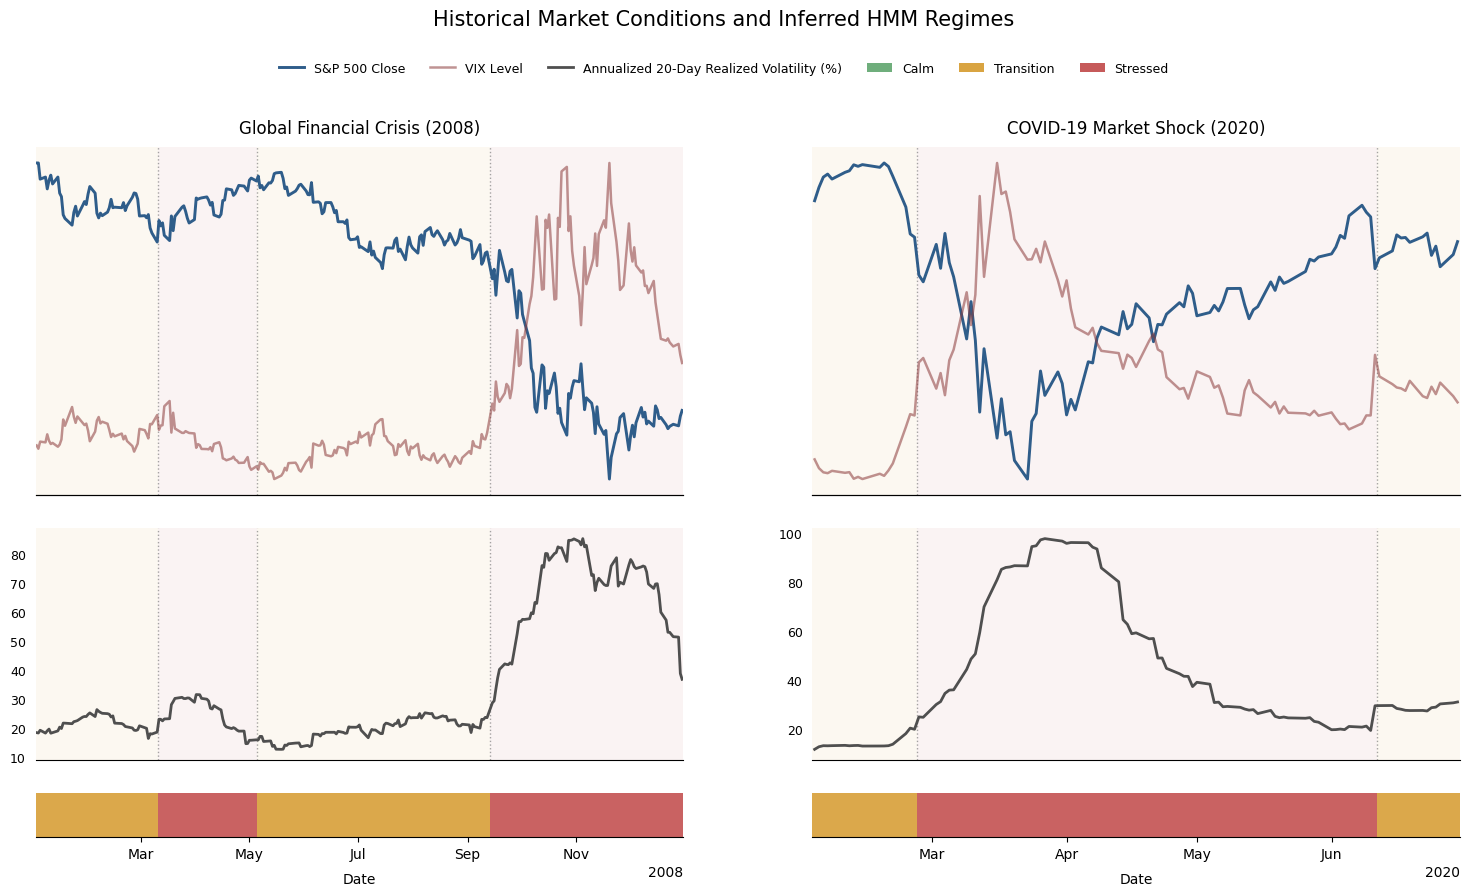

In [98]:

# --------------------------------------------------
# 8.5.2 Historical Event Visualization
# Minimalist axes, subtle regime shading, transition
# boundaries, and bottom regime timeline
# --------------------------------------------------

# --------------------------------------------------
# Colors
# --------------------------------------------------

regime_colors = {
    "Calm": "#6FAE7C",
    "Transition": "#D9A441",
    "Stressed": "#C65A5A"
}

sp500_color = "#2F5D8A"
vix_color = "#8B3A3A"
rv_color = "#4F4F4F"

background_alpha = 0.07
vix_alpha = 0.55

# --------------------------------------------------
# Events
# --------------------------------------------------

event_order = [
    "Global Financial Crisis (2008)",
    "COVID-19 Market Shock (2020)"
]

# --------------------------------------------------
# Figure layout
# --------------------------------------------------

fig_historical_events_improved = plt.figure(
    figsize=(16, 9.2)
)

gs = fig_historical_events_improved.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[3.0, 2.0, 0.38],
    hspace=0.16,
    wspace=0.20
)

# --------------------------------------------------
# Helper: remove unwanted axis features
# --------------------------------------------------

def clean_event_axis(ax, remove_y_axis=False):

    ax.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if remove_y_axis:
        ax.spines["left"].set_visible(False)
        ax.tick_params(
            axis="y",
            left=False,
            labelleft=False
        )
    else:
        # Keep numeric volatility scale, but no axis title
        ax.spines["left"].set_visible(False)
        ax.tick_params(
            axis="y",
            left=False,
            labelleft=True,
            labelsize=9
        )

# --------------------------------------------------
# Plot historical events
# --------------------------------------------------

for col, event_name in enumerate(event_order):

    event_df = (
        historical_event_dfs[event_name]
        .sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )

    event_df["Date"] = pd.to_datetime(event_df["Date"])

    dates = event_df["Date"]
    regimes = event_df["Regime"].to_numpy()

    realized_vol_pct = (
        event_df["Realized_Vol_20D"] * 100
    )

    # ----------------------------------------------
    # Build contiguous time boundaries
    # Use midpoints between adjacent trading dates
    # to avoid visual gaps in regime shading.
    # ----------------------------------------------

    date_num = mdates.date2num(dates.to_numpy())

    boundaries = np.empty(len(date_num) + 1)

    boundaries[1:-1] = (
        date_num[:-1] + date_num[1:]
    ) / 2

    boundaries[0] = (
        date_num[0]
        - (boundaries[1] - date_num[0])
    )

    boundaries[-1] = (
        date_num[-1]
        + (date_num[-1] - boundaries[-2])
    )

    # Identify regime episodes and transition positions
    change_indices = np.flatnonzero(
        regimes[1:] != regimes[:-1]
    ) + 1

    segment_starts = np.r_[0, change_indices]
    segment_ends = np.r_[change_indices, len(event_df)]

    segments = [
        {
            "Regime": regimes[start],
            "Left": boundaries[start],
            "Right": boundaries[end]
        }
        for start, end in zip(
            segment_starts, segment_ends
        )
    ]

    transition_dates = boundaries[change_indices]

    # ----------------------------------------------
    # Top panel: S&P 500 and VIX
    # ----------------------------------------------

    ax_top = fig_historical_events_improved.add_subplot(
        gs[0, col]
    )

    ax_vix = ax_top.twinx()

    ax_top.plot(
        dates,
        event_df["SP500_Close"],
        color=sp500_color,
        linewidth=2.1,
        zorder=4
    )

    ax_vix.plot(
        dates,
        event_df["VIX_Level"],
        color=vix_color,
        linewidth=1.8,
        alpha=vix_alpha,
        zorder=5
    )

    ax_top.set_title(
        event_name,
        fontsize=12,
        pad=10
    )

    # Remove both top-panel Y axes and their labels
    clean_event_axis(
        ax_top,
        remove_y_axis=True
    )

    ax_vix.grid(False)

    for spine in ["top", "right", "left"]:
        ax_vix.spines[spine].set_visible(False)

    ax_vix.tick_params(
        axis="y",
        right=False,
        labelright=False
    )

    ax_top.set_ylabel("")
    ax_vix.set_ylabel("")

    # ----------------------------------------------
    # Middle panel: Annualized realized volatility
    # ----------------------------------------------

    ax_mid = fig_historical_events_improved.add_subplot(
        gs[1, col],
        sharex=ax_top
    )

    ax_mid.plot(
        dates,
        realized_vol_pct,
        color=rv_color,
        linewidth=2.0,
        zorder=4
    )

    # Remove label but retain percentage tick values
    ax_mid.set_ylabel("")

    clean_event_axis(
        ax_mid,
        remove_y_axis=False
    )

    # ----------------------------------------------
    # Bottom panel: Regime bar
    # ----------------------------------------------

    ax_bar = fig_historical_events_improved.add_subplot(
        gs[2, col],
        sharex=ax_top
    )

    ax_bar.set_ylim(0, 1)

    ax_bar.set_yticks([])
    ax_bar.set_ylabel("")

    ax_bar.grid(False)

    for spine in ["top", "right", "left"]:
        ax_bar.spines[spine].set_visible(False)

    # ----------------------------------------------
    # Regime shading and transition separators
    # ----------------------------------------------

    for segment in segments:

        color = regime_colors[segment["Regime"]]

        # Very subtle background in both plots
        for ax in [ax_top, ax_mid]:
            ax.axvspan(
                segment["Left"],
                segment["Right"],
                color=color,
                alpha=background_alpha,
                linewidth=0,
                zorder=0
            )

        # Solid regime bar
        ax_bar.axvspan(
            segment["Left"],
            segment["Right"],
            color=color,
            alpha=0.95,
            linewidth=0
        )

    # Dotted regime-change separators
    for boundary in transition_dates:

        for ax in [ax_top, ax_mid]:
            ax.axvline(
                boundary,
                color="#777777",
                linestyle=":",
                linewidth=1.0,
                alpha=0.65,
                zorder=2
            )

    # ----------------------------------------------
    # X-axis formatting
    # ----------------------------------------------

    ax_top.set_xlim(
        boundaries[0],
        boundaries[-1]
    )

    ax_bar.xaxis.set_major_locator(
        mdates.AutoDateLocator(minticks=4, maxticks=7)
    )

    ax_bar.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(
            ax_bar.xaxis.get_major_locator()
        )
    )

    ax_bar.set_xlabel(
        "Date",
        fontsize=10,
        labelpad=8
    )

    ax_top.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    ax_mid.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        color=sp500_color,
        linewidth=2.1,
        label="S&P 500 Close"
    ),
    Line2D(
        [0], [0],
        color=vix_color,
        linewidth=1.8,
        alpha=vix_alpha,
        label="VIX Level"
    ),
    Line2D(
        [0], [0],
        color=rv_color,
        linewidth=2.0,
        label="Annualized 20-Day Realized Volatility (%)"
    ),
    Patch(
        facecolor=regime_colors["Calm"],
        label="Calm"
    ),
    Patch(
        facecolor=regime_colors["Transition"],
        label="Transition"
    ),
    Patch(
        facecolor=regime_colors["Stressed"],
        label="Stressed"
    )
]

fig_historical_events_improved.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.945),
    ncol=6,
    frameon=False,
    fontsize=9
)

# --------------------------------------------------
# Overall formatting
# --------------------------------------------------

fig_historical_events_improved.suptitle(
    "Historical Market Conditions and Inferred HMM Regimes",
    fontsize=15,
    y=0.99
)

fig_historical_events_improved.subplots_adjust(
    left=0.07,
    right=0.96,
    bottom=0.09,
    top=0.84,
    hspace=0.18,
    wspace=0.20
)

plt.show()


**Key Observations**

1. **Inverse Movement Between the S&P 500 and VIX:** Both historical events demonstrate an inverse directional relationship, with declining S&P 500 levels coinciding with increases in the VIX, reflecting heightened market uncertainty.

2. **Overlap Between Implied and Realized Volatility:** Elevated VIX levels generally coincide with periods of increased 20-day realized volatility. However, realized volatility responds to accumulated historical returns, meaning its movements may lag abrupt changes in market conditions.

3. **Alignment of Stressed Regimes with Market Turbulence:** Stressed assignments coincide with periods of lower equity prices and elevated volatility. During the 2008 crisis, 45.45% of observations were classified as Stressed, compared with 71.15% during the selected 2020 shock window.

4. **Different Patterns of Market Stress:** The 2008 crisis exhibits a larger proportion of Transition observations (54.55%), whereas the 2020 shock is more concentrated in the Stressed regime (71.15%). These differences suggest distinct temporal patterns of market turbulence across the two events.

5. **Historical Consistency of Regime Classification:** The overlap between market movements, volatility indicators, and inferred HMM regimes supports the economic plausibility of the three-state framework. However, the visualization provides qualitative evidence of historical alignment rather than proof of real-time crisis detection.


In [106]:

# --------------------------------------------------
# 8.5.3 Regime Confidence During Market Stress
# 95% confidence threshold (alpha = 0.05)
# --------------------------------------------------

alpha = 0.05
confidence_threshold = 1 - alpha

# Smoothed probabilities and Viterbi assignments
train_prob = hmm_model.predict_proba(X_train_scaled)
test_prob = hmm_model.predict_proba(X_test_scaled)

train_states = hmm_model.predict(X_train_scaled)
test_states = hmm_model.predict(X_test_scaled)

def add_confidence(df, probabilities, states, period):

    result = df.sort_values("Date").reset_index(
        drop=True
    ).copy()

    assert len(result) == len(states) == len(probabilities)

    assert np.array_equal(
        result["State_ID"].to_numpy(), states
    ), "State assignments are not aligned."

    result["Assigned_Confidence"] = probabilities[
        np.arange(len(states)), states
    ]

    result["High_Confidence"] = (
        result["Assigned_Confidence"] >= confidence_threshold
    )

    result["Period"] = period

    return result

# Full-period confidence datasets
train_confidence_df = add_confidence(
    df_train_regimes, train_prob, train_states, "Training"
)

test_confidence_df = add_confidence(
    df_test_regimes, test_prob, test_states, "Testing"
)

historical_confidence_df = pd.concat(
    [train_confidence_df, test_confidence_df],
    ignore_index=True
)

# --------------------------------------------------
# Historical event confidence summary
# --------------------------------------------------

confidence_records = []
historical_event_confidence_dfs = {}

for event_name, settings in historical_event_windows.items():

    event_df = historical_confidence_df.loc[
        historical_confidence_df["Date"].between(
            pd.Timestamp(settings["Start"]),
            pd.Timestamp(settings["End"])
        )
        & historical_confidence_df["Period"].eq(
            settings["Period"]
        )
    ].copy()

    historical_event_confidence_dfs[event_name] = event_df

    for regime in regime_order:

        subset = event_df.loc[
            event_df["Regime"] == regime
        ]

        if subset.empty:
            continue

        confidence_records.append({
            "Event": event_name,
            "Regime": regime,
            "Observations": len(subset),
            "Mean_Confidence": (
                subset["Assigned_Confidence"].mean()
            ),
            "Median_Confidence": (
                subset["Assigned_Confidence"].median()
            ),
            "High_Confidence_95_Pct": (
                subset["High_Confidence"].mean() * 100
            ),
            "Below_95_Pct": (
                (~subset["High_Confidence"]).mean() * 100
            )
        })

historical_confidence_summary_df = (
    pd.DataFrame(confidence_records)
    .set_index(["Event", "Regime"])
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert np.allclose(train_prob.sum(axis=1), 1)
assert np.allclose(test_prob.sum(axis=1), 1)

assert historical_confidence_df[
    "Assigned_Confidence"
].between(0, 1).all()

assert historical_confidence_summary_df[
    "Observations"
].sum() == sum(
    len(event_df)
    for event_df in historical_event_confidence_dfs.values()
)

assert np.allclose(
    historical_confidence_summary_df[
        "High_Confidence_95_Pct"
    ]
    + historical_confidence_summary_df["Below_95_Pct"],
    100
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("Historical Regime Assignment Confidence")
print(
    f"High-confidence threshold: "
    f"{confidence_threshold:.0%} "
    f"(alpha = {alpha:.2f})\n"
)

display(historical_confidence_summary_df.round(4))


Historical Regime Assignment Confidence
High-confidence threshold: 95% (alpha = 0.05)



Observations  Mean_Confidence  Median_Confidence  High_Confidence_95_Pct  Below_95_Pct
Event                          Regime                                                                                            
Global Financial Crisis (2008) Transition           138           0.9306             0.9998                 84.0580       15.9420
                               Stressed             115           0.9983             1.0000                 98.2609        1.7391
COVID-19 Market Shock (2020)   Transition            30           0.9998             1.0000                100.0000        0.0000
                               Stressed              74           0.9072             1.0000                 79.7297       20.2703

**Key Observations**

1. **High Confidence During the 2008 Stressed Regime:** The HMM exhibited strong assignment confidence during the 2008 crisis, with 98.26% of Stressed observations meeting the 95% threshold and a mean assigned-state probability of 99.83%.

2. **Greater Uncertainty During the 2020 Stressed Regime:** Although the HMM classified 71.15% of the selected 2020 observations as Stressed, only 79.73% of these assignments met the 95% confidence threshold. This indicates greater posterior uncertainty in a subset of Stressed observations.

3. **Differences in Transition Confidence:** Transition assignments achieved a 95% confidence rate of 84.06% during 2008, compared with 100% during the selected 2020 window.

4. **High Median Confidence Across Both Events:** Median confidence was approximately 100% in all four regime-event combinations, indicating that most assignments were strongly supported by the model's smoothed posterior probabilities.

5. **Implications for Regime Interpretation:** The results support generally confident retrospective regime identification during major market disruptions, while highlighting that high Stressed-regime prevalence does not necessarily imply uniformly high assignment confidence.

In [108]:

# --------------------------------------------------
# 8.5.4 Failure Analysis
# Lower-confidence assignments and regime transitions
# --------------------------------------------------

confidence_threshold = 0.95
transition_window = 2

# --------------------------------------------------
# Identify observations near regime transitions
# --------------------------------------------------

def add_transition_proximity(df, window=2):

    result = df.sort_values("Date").reset_index(drop=True).copy()

    states = result["State_ID"].to_numpy()
    positions = np.arange(len(result))

    # A transition occurs when consecutive states differ
    change_positions = np.flatnonzero(
        states[1:] != states[:-1]
    ) + 1

    if len(change_positions):

        distance = np.min(
            np.abs(
                positions[:, None] -
                change_positions[None, :]
            ),
            axis=1
        )

    else:
        distance = np.full(
            len(result),
            np.inf
        )

    result["Distance_to_Transition"] = distance
    result["Near_Transition"] = distance <= window

    result["Below_95"] = (
        result["Assigned_Confidence"] < confidence_threshold
    )

    return result

# Use full-period observations before filtering by event
train_failure_df = add_transition_proximity(
    train_confidence_df,
    window=transition_window
)

test_failure_df = add_transition_proximity(
    test_confidence_df,
    window=transition_window
)

failure_full_df = pd.concat(
    [train_failure_df, test_failure_df],
    ignore_index=True
)

# --------------------------------------------------
# Historical event diagnostics
# --------------------------------------------------

failure_event_dfs = {}
failure_records = []

for event_name, settings in historical_event_windows.items():

    event_df = failure_full_df.loc[
        failure_full_df["Date"].between(
            pd.Timestamp(settings["Start"]),
            pd.Timestamp(settings["End"])
        )
        & failure_full_df["Period"].eq(
            settings["Period"]
        )
    ].copy()

    failure_event_dfs[event_name] = event_df

    for regime in regime_order:

        subset = event_df.loc[
            event_df["Regime"].eq(regime)
        ]

        if subset.empty:
            continue

        low_conf = subset.loc[subset["Below_95"]]

        near_low = low_conf["Near_Transition"].sum()

        failure_records.append({
            "Event": event_name,
            "Regime": regime,
            "Observations": len(subset),
            "Below_95_Count": len(low_conf),
            "Below_95_Pct": (
                len(low_conf) / len(subset) * 100
            ),
            "Low_Conf_Near_Transition": int(near_low),
            "Low_Conf_Away_Transition": int(
                len(low_conf) - near_low
            ),
            "Low_Conf_Near_Transition_Pct": (
                near_low / len(low_conf) * 100
                if len(low_conf) else np.nan
            ),
            "All_Obs_Near_Transition_Pct": (
                subset["Near_Transition"].mean() * 100
            )
        })

failure_analysis_df = (
    pd.DataFrame(failure_records)
    .set_index(["Event", "Regime"])
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert (
    failure_analysis_df["Low_Conf_Near_Transition"]
    + failure_analysis_df["Low_Conf_Away_Transition"]
    == failure_analysis_df["Below_95_Count"]
).all()

assert (
    failure_analysis_df["Observations"].sum()
    == sum(len(df) for df in failure_event_dfs.values())
)

# Verify confidence counts against Section 8.5.3
assert np.allclose(
    failure_analysis_df["Below_95_Pct"],
    historical_confidence_summary_df["Below_95_Pct"]
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("Historical Failure Diagnostics")
print("Low confidence: assigned probability < 95%")
print("Near transition: within 2 trading observations\n")

display(failure_analysis_df.round(2))


Historical Failure Diagnostics
Low confidence: assigned probability < 95%
Near transition: within 2 trading observations



Observations  Below_95_Count  Below_95_Pct  Low_Conf_Near_Transition  Low_Conf_Away_Transition  Low_Conf_Near_Transition_Pct  All_Obs_Near_Transition_Pct
Event                          Regime                                                                                                                                                               
Global Financial Crisis (2008) Transition           138              22         15.94                         5                        17                         22.73                         5.07
                               Stressed             115               2          1.74                         2                         0                        100.00                         6.96
COVID-19 Market Shock (2020)   Transition            30               0          0.00                         0                         0                           NaN                        16.67
                               Stressed              74              15         20.27                         2                        13                         13.33                         6.76


**Key Observations**

1. **Assignment Uncertainty Extends Beyond Regime Transitions:** Lower-confidence observations were not exclusively concentrated around regime changes. During the 2020 shock, 86.67% of lower-confidence Stressed observations occurred more than two trading observations away from a transition.

2. **Greater Transition Ambiguity During 2008:** The 2008 Transition regime contained 22 lower-confidence observations (15.94%), of which 17 occurred away from regime transitions, suggesting uncertainty within otherwise persistent Transition episodes.

3. **Strong Confidence in the 2008 Stressed Regime:** Only two Stressed observations (1.74%) fell below the 95% confidence threshold, and both were located near regime changes.

4. **Internal Uncertainty During the 2020 Stressed Regime:** The 2020 Stressed regime contained 15 lower-confidence observations (20.27%), with 13 occurring away from transitions, indicating that uncertainty can persist during sustained market turbulence.

5. **Implications for Model Reliability:** These findings identify potential limitations in regime assignment certainty, particularly during prolonged periods of instability. However, lower posterior confidence should not be interpreted as definitive classification failure in the absence of externally observed market-regime labels.


### Section 8.6 - Summary of Model Diagnostics, Sensitivity Analysis, and Failure Analysis

#### Activities Performed

1. **Feature Distribution Diagnostics:** Compared the distributions of the five HMM input features between training (2000–2017) and testing (2018–2025), examining changes in central tendency, dispersion, and extreme observations.

2. **Regime Persistence and Fragmentation:** Evaluated episode durations, regime prevalence, short-lived episodes, and changes in the temporal structure of Calm, Transition, and Stressed assignments.

3. **Model Specification Sensitivity:** Compared HMM specifications with two to six hidden states and conducted leave-one-feature-out experiments to assess assignment stability and model dependence.

4. **Historical Event Evaluation:** Examined the alignment of inferred regimes with S&P 500 movements, VIX levels, and realized volatility during the 2008 Global Financial Crisis and 2020 COVID-19 market shock.

5. **Assignment Confidence and Failure Diagnostics:** Evaluated smoothed posterior probabilities using a 95% diagnostic threshold (α = 0.05) and investigated lower-confidence assignments relative to regime transitions.

#### Key Observations

1. **Market Feature Distributions Shifted Between Training and Testing.** Although the average VIX level and realized volatility remained relatively stable, the testing period exhibited greater dispersion in daily VIX changes and return kurtosis. The standard deviation of VIX changes increased by approximately 28%, while return skewness became more negative, suggesting changes in market dynamics despite relatively stable average volatility conditions.

2. **Regime Persistence Changed Across Evaluation Periods.** The Stressed regime exhibited a substantial reduction in median episode duration, declining from 21.5 trading days during training to 9 days during testing. The proportion of Stressed episodes lasting five trading days or fewer increased from 13.33% to 25.00%, indicating more fragmented stress classifications. Meanwhile, the Transition regime became more prevalent during testing, increasing from 38.00% to 49.13% of observations.

3. **Model Complexity Introduced Tradeoffs Between Fit and Separation.** Increasing the number of hidden states improved training BIC, with the six-state specification achieving the lowest value (32,894.96). However, the two-state model produced the highest testing Silhouette Score (0.1726). More complex specifications generally exhibited higher switching rates and smaller state populations, indicating that improved statistical fit did not consistently translate into more distinct or persistent regimes.

4. **Regime Assignments Were Sensitive to Feature Selection.** Removing return skewness or kurtosis produced the largest changes in regime assignments, with testing Adjusted Rand Index (ARI) values of 0.3195 and 0.2769, respectively. In contrast, excluding daily VIX change produced the highest testing ARI (0.8388), indicating comparatively greater agreement with the baseline specification.

5. **Historical Regimes Aligned with Major Market Disruptions.** Stressed assignments accounted for 45.45% of observations during the selected 2008 crisis window and 71.15% during the 2020 shock window. In both events, Stressed observations coincided with lower average equity prices and substantially elevated VIX and realized volatility, supporting the economic plausibility of the inferred regime structure.

6. **Assignment Confidence Varied Across Historical Events.** During 2008, 98.26% of Stressed observations met the 95% posterior confidence threshold, compared with 79.73% during 2020. Furthermore, 86.67% of lower-confidence Stressed observations during 2020 occurred more than two trading observations away from regime changes, demonstrating that uncertainty can persist within otherwise established regimes.

#### Implications for Subsequent Modeling

The diagnostic findings support retaining the original three-state Gaussian HMM as the baseline for identifying Calm, Transition, and Stressed market conditions. The model provides an economically interpretable characterization of historical market behavior, while its temporal structure captures meaningful variation in regime persistence and market stress.

Nevertheless, the results also highlight several limitations. Regime assignments are sensitive to the selected features and number of hidden states, clustering separation weakens during testing, and periods of assignment uncertainty persist even during major market disruptions. Consequently, the inferred regimes should be treated as model-dependent representations of market conditions rather than definitive classifications.

**For Model A**, these findings establish the rationale for evaluating whether regime-derived information improves forward realized-volatility forecasts beyond conventional market indicators and a naive persistence benchmark. The incremental value of regime features must be demonstrated empirically rather than assumed from their historical interpretability.

Crucially, the retrospective Viterbi assignments and smoothed posterior probabilities used throughout Model B's diagnostic analysis incorporate information unavailable at earlier dates. Model A must therefore use temporally valid filtered probabilities generated from the training-fitted HMM, with all preprocessing parameters estimated exclusively from the training period.

Overall, Model B provides a documented and diagnostically evaluated framework for identifying historical market regimes, while recognizing the uncertainty, specification sensitivity, and temporal-information constraints that must be addressed when transferring its outputs into a supervised forecasting setting.

## Section 9 - Preparing HMM Outputs for Model A

This section prepares the outputs of the three-state Gaussian HMM for use in Model A's supervised volatility forecasting framework. Unlike retrospective Viterbi assignments and smoothed probabilities, filtered state probabilities use information available only up to each observation date, preventing look-ahead bias in regime-derived predictors.

The original training-fitted HMM and feature scaler are retained without modification.

| Subsection | Analysis | Objective |
|:---|:---|:---|
| **9.1** | Filtered Regime Probabilities | Generate temporally valid probabilities for Calm, Transition, and Stressed regimes. |
| **9.2** | Probability Validation | Verify probability consistency, temporal alignment, and absence of future information. |
| **9.3** | Model A Feature Preparation | Combine filtered probabilities with dates and export the resulting dataset for supervised modeling. |


### Section 9.1 - Filtered Regime Probabilities

Filtered state probabilities are calculated using the forward algorithm, which estimates the probability of each hidden market state conditional on observations available through the current trading day.

Unlike smoothed probabilities or retrospective Viterbi assignments, filtered probabilities do not incorporate future observations. The original three-state HMM and training-fitted scaler are retained, and the filtering sequence continues chronologically from training into testing.

The resulting probabilities are mapped to Calm, Transition, and Stressed regimes for use as temporally valid predictors in Model A

In [112]:

# --------------------------------------------------
# 9.1 Filtered HMM Regime Probabilities
# Forward algorithm with training-to-testing continuity
# --------------------------------------------------

# --------------------------------------------------
# Combine standardized features chronologically
# --------------------------------------------------

X_all_scaled = np.vstack([
    X_train_scaled,
    X_test_scaled
])

dates_all = pd.concat(
    [
        df_train["Date"],
        df_test["Date"]
    ],
    ignore_index=True
)

assert len(X_all_scaled) == len(dates_all)
assert dates_all.is_monotonic_increasing
assert dates_all.is_unique

# --------------------------------------------------
# Gaussian HMM emission log-probabilities
# --------------------------------------------------

# Uses the parameters of the existing fitted HMM.
# No model refitting or future-observation smoothing.

log_emissions = hmm_model._compute_log_likelihood(
    X_all_scaled
)

log_transition = np.log(
    np.clip(hmm_model.transmat_, 1e-300, 1)
)

log_initial = np.log(
    np.clip(hmm_model.startprob_, 1e-300, 1)
)

# --------------------------------------------------
# Forward filtering
# --------------------------------------------------

n_obs, n_states = log_emissions.shape

log_filtered = np.empty((n_obs, n_states))

# First observation
log_alpha = log_initial + log_emissions[0]
log_alpha -= logsumexp(log_alpha)

log_filtered[0] = log_alpha

# Remaining observations
for t in range(1, n_obs):

    log_predicted = logsumexp(
        log_alpha[:, None] + log_transition,
        axis=0
    )

    log_alpha = log_predicted + log_emissions[t]
    log_alpha -= logsumexp(log_alpha)

    log_filtered[t] = log_alpha

filtered_probabilities = np.exp(log_filtered)

# --------------------------------------------------
# Map latent states to economic regime labels
# --------------------------------------------------

regime_to_state = {
    regime: state
    for state, regime in state_to_regime.items()
}

filtered_regime_df = pd.DataFrame({
    "Date": dates_all,
    "P_Calm": filtered_probabilities[
        :, regime_to_state["Calm"]
    ],
    "P_Transition": filtered_probabilities[
        :, regime_to_state["Transition"]
    ],
    "P_Stressed": filtered_probabilities[
        :, regime_to_state["Stressed"]
    ]
})

filtered_regime_df["Period"] = (
    ["Training"] * len(df_train)
    + ["Testing"] * len(df_test)
)

# --------------------------------------------------
# Basic validation
# --------------------------------------------------

probability_cols = [
    "P_Calm",
    "P_Transition",
    "P_Stressed"
]

assert filtered_regime_df[probability_cols].notna().all().all()

assert np.allclose(
    filtered_regime_df[probability_cols].sum(axis=1),
    1.0
)

assert filtered_regime_df[probability_cols].ge(0).all().all()
assert filtered_regime_df[probability_cols].le(1).all().all()

assert len(filtered_regime_df) == (
    len(df_train) + len(df_test)
)

# --------------------------------------------------
# Display
# --------------------------------------------------

print("Filtered HMM Regime Probabilities")
print(f"Observations: {len(filtered_regime_df):,}")
print(f"Training: {len(df_train):,}")
print(f"Testing: {len(df_test):,}\n")

display(filtered_regime_df.head())
display(filtered_regime_df.tail())


Filtered HMM Regime Probabilities
Observations: 6,519
Training: 4,508
Testing: 2,011



,Date,P_Calm,P_Transition,P_Stressed,Period
0,2000-02-01,5.592983e-312,1.000000,1.669176e-78,Training
1,2000-02-02,9.414863e-09,0.996413,3.587433e-03,Training
2,2000-02-03,3.540942e-09,0.996788,3.211577e-03,Training
3,2000-02-04,1.679615e-08,0.997089,2.911107e-03,Training
4,2000-02-07,1.078003e-08,0.999345,6.552823e-04,Training


,Date,P_Calm,P_Transition,P_Stressed,Period
6514,2025-12-24,0.808609,0.191366,0.000024,Testing
6515,2025-12-26,0.950730,0.049260,0.000010,Testing
6516,2025-12-29,0.989456,0.010532,0.000012,Testing
6517,2025-12-30,0.984933,0.015053,0.000014,Testing
6518,2025-12-31,0.995136,0.004847,0.000017,Testing


### Section 9.2 - Probability Validation

The filtered regime probabilities are validated for numerical consistency, chronological alignment, and temporal information integrity. Particular attention is given to the training–testing boundary and the absence of future observations in the forward-filtering calculation.

The validation confirms that the generated probabilities are suitable as end-of-day regime features, conditional on the parameters of the training-fitted HMM.

In [113]:

# --------------------------------------------------
# 9.2 Filtered HMM Probability Validation
# --------------------------------------------------

import numpy as np
import pandas as pd
from scipy.special import logsumexp

prob_cols = ["P_Calm", "P_Transition", "P_Stressed"]

# --------------------------------------------------
# 1. Numerical consistency
# --------------------------------------------------

P = filtered_regime_df[prob_cols].to_numpy()

assert np.isfinite(P).all()
assert (P >= 0).all()
assert (P <= 1).all()
assert np.allclose(P.sum(axis=1), 1.0, atol=1e-10)

max_probability_sum_error = np.max(
    np.abs(P.sum(axis=1) - 1.0)
)

# --------------------------------------------------
# 2. Temporal alignment and boundary continuity
# --------------------------------------------------

expected_dates = pd.concat(
    [df_train["Date"], df_test["Date"]],
    ignore_index=True
)

assert np.array_equal(
    pd.to_datetime(filtered_regime_df["Date"]).to_numpy(),
    pd.to_datetime(expected_dates).to_numpy()
)

assert filtered_regime_df["Date"].is_unique
assert filtered_regime_df["Date"].is_monotonic_increasing

boundary_idx = len(df_train)

assert filtered_regime_df.iloc[
    boundary_idx - 1
]["Period"] == "Training"

assert filtered_regime_df.iloc[
    boundary_idx
]["Period"] == "Testing"

# --------------------------------------------------
# 3. No-look-ahead check using historical prefixes
# --------------------------------------------------

def calculate_filtered_prefix(X):

    emissions = hmm_model._compute_log_likelihood(X)

    log_A = np.where(
        hmm_model.transmat_ > 0,
        np.log(np.maximum(hmm_model.transmat_, 1e-300)),
        -np.inf
    )

    log_pi = np.where(
        hmm_model.startprob_ > 0,
        np.log(np.maximum(hmm_model.startprob_, 1e-300)),
        -np.inf
    )

    log_alpha = log_pi + emissions[0]
    log_alpha -= logsumexp(log_alpha)

    output = [np.exp(log_alpha)]

    for t in range(1, len(X)):

        log_prediction = logsumexp(
            log_alpha[:, None] + log_A,
            axis=0
        )

        log_alpha = log_prediction + emissions[t]
        log_alpha -= logsumexp(log_alpha)

        output.append(np.exp(log_alpha))

    return np.asarray(output)

# Test prefixes including the training/testing boundary
prefix_lengths = [
    50,
    500,
    boundary_idx,
    boundary_idx + 1,
    boundary_idx + 100
]

state_columns = [
    regime_to_state["Calm"],
    regime_to_state["Transition"],
    regime_to_state["Stressed"]
]

prefix_errors = []

for n in prefix_lengths:

    prefix_probs = calculate_filtered_prefix(
        X_all_scaled[:n]
    )[:, state_columns]

    stored_probs = P[:n]

    prefix_errors.append(
        np.max(np.abs(prefix_probs - stored_probs))
    )

max_prefix_difference = max(prefix_errors)

assert max_prefix_difference < 1e-10

# --------------------------------------------------
# Validation summary
# --------------------------------------------------

filter_validation_df = pd.DataFrame({
    "Check": [
        "Probability bounds and finite values",
        "Probabilities sum to one",
        "Chronological date alignment",
        "Training/testing boundary alignment",
        "Historical prefix consistency"
    ],
    "Status": ["Passed"] * 5,
    "Diagnostic": [
        "All values within [0, 1]",
        f"Maximum error: {max_probability_sum_error:.2e}",
        "Dates match original dataset",
        "Training-to-testing sequence preserved",
        f"Maximum difference: {max_prefix_difference:.2e}"
    ]
})

print("Filtered HMM Probability Validation\n")
display(filter_validation_df)

print("\nTraining–Testing Boundary:")
display(
    filtered_regime_df.iloc[
        boundary_idx - 2 : boundary_idx + 3
    ]
)


Filtered HMM Probability Validation



,Check,Status,Diagnostic
0,Probability bounds and finite values,Passed,"All values within [0, 1]"
1,Probabilities sum to one,Passed,Maximum error: 2.44e-15
2,Chronological date alignment,Passed,Dates match original dataset
3,Training/testing boundary alignment,Passed,Training-to-testing sequence preserved
4,Historical prefix consistency,Passed,Maximum difference: 5.59e-312



Training–Testing Boundary:


,Date,P_Calm,P_Transition,P_Stressed,Period
4506,2017-12-28,0.999832,0.000004,0.000164,Training
4507,2017-12-29,0.999757,0.000003,0.000240,Training
4508,2018-01-02,0.999537,0.000068,0.000395,Testing
4509,2018-01-03,0.999701,0.000210,0.000089,Testing
4510,2018-01-04,0.999723,0.000229,0.000048,Testing


### Section 9.3 - Model A Feature Preperation

The validated filtered HMM probabilities are organized into a date-aligned feature dataset containing the probabilities of Calm, Transition, and Stressed market conditions.

The dataset preserves the original chronological training–testing split and will be transferred to Model A for supervised volatility forecasting. The probabilities represent information available through the current trading day, conditional on the training-fitted HMM parameters.

The dataset is prepared for export through the notebook's Misc section. No forward-looking volatility targets are generated in this step.

In [114]:

# --------------------------------------------------
# 9.3 Prepare Filtered HMM Features for Model A
# --------------------------------------------------

probability_cols = [
    "P_Calm",
    "P_Transition",
    "P_Stressed"
]

# Final feature dataset
model_a_regime_features_df = (
    filtered_regime_df[
        ["Date", "Period"] + probability_cols
    ]
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert len(model_a_regime_features_df) == 6519

assert model_a_regime_features_df["Date"].is_unique
assert model_a_regime_features_df["Date"].is_monotonic_increasing

assert model_a_regime_features_df[
    ["Date", "Period"] + probability_cols
].notna().all().all()

assert np.allclose(
    model_a_regime_features_df[
        probability_cols
    ].sum(axis=1),
    1.0
)

assert (
    model_a_regime_features_df["Period"]
    .value_counts()
    .reindex(["Training", "Testing"])
    .to_list()
    == [4508, 2011]
)

# --------------------------------------------------
# Summary
# --------------------------------------------------

model_a_feature_summary_df = (
    model_a_regime_features_df
    .groupby("Period")
    .agg(
        Observations=("Date", "size"),
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Mean_P_Calm=("P_Calm", "mean"),
        Mean_P_Transition=("P_Transition", "mean"),
        Mean_P_Stressed=("P_Stressed", "mean")
    )
    .reindex(["Training", "Testing"])
)

print("Model A — Filtered HMM Feature Dataset")
print(f"Shape: {model_a_regime_features_df.shape}\n")

display(model_a_feature_summary_df.round(4))

print("\nSample observations:")
display(model_a_regime_features_df.head(3))
display(model_a_regime_features_df.tail(3))

Model A — Filtered HMM Feature Dataset
Shape: (6519, 5)



,Observations,Start_Date,End_Date,Mean_P_Calm,Mean_P_Transition,Mean_P_Stressed
Period,,,,,,
Training,4508,2000-02-01,2017-12-29,0.3457,0.3822,0.2721
Testing,2011,2018-01-02,2025-12-31,0.2986,0.4972,0.2041



Sample observations:


,Date,Period,P_Calm,P_Transition,P_Stressed
0,2000-02-01,Training,5.592983e-312,1.000000,1.669176e-78
1,2000-02-02,Training,9.414863e-09,0.996413,3.587433e-03
2,2000-02-03,Training,3.540942e-09,0.996788,3.211577e-03


,Date,Period,P_Calm,P_Transition,P_Stressed
6516,2025-12-29,Testing,0.989456,0.010532,0.000012
6517,2025-12-30,Testing,0.984933,0.015053,0.000014
6518,2025-12-31,Testing,0.995136,0.004847,0.000017


### Section 9.4 - Summary of Preparing HMM Outputs for Model A

This section generated, validated, and organized the filtered regime probabilities from the three-state Gaussian HMM for integration into Model A's supervised volatility forecasting framework.

**Activities Performed**

1. **Forward Filtering:** Calculated the probabilities of Calm, Transition, and Stressed regimes using observations available through each trading date.
2. **Probability Validation:** Verified probability bounds, chronological alignment, training–testing continuity, and historical-prefix consistency.
3. **Feature Preparation:** Constructed a date-aligned dataset containing 6,519 observations and three filtered regime probabilities.

**Key Observations**

1. **Numerical and Temporal Consistency:** All validation checks passed, with a maximum probability-sum error of 2.44 × 10⁻¹⁵ and a maximum historical-prefix difference of 5.59 × 10⁻³¹².

2. **Training–Testing Continuity:** Forward filtering preserved the chronological sequence across December 2017 and January 2018 without resetting the HMM's state distribution.

3. **Changes in Regime Probabilities:** The average filtered Transition probability increased from 38.22% during training to 49.72% during testing. Meanwhile, average Calm and Stressed probabilities decreased from 34.57% to 29.86% and from 27.21% to 20.41%, respectively.

4. **Model A Feature Readiness:** The resulting dataset contains 4,508 training and 2,011 testing observations, with unique trading dates and validated regime probabilities.

**Implications for Subsequent Modeling**

The filtered regime probabilities provide temporally ordered market-state features that can be merged with Model A's conventional volatility predictors using trading dates.

Unlike retrospective Viterbi assignments and smoothed probabilities, forward filtering avoids using future observations in the probability calculations when model parameters are fixed.

However, because the HMM parameters were estimated on the complete 2000–2017 training period, probabilities generated for that same period are not historically out-of-sample model estimates. Model A's training and evaluation design must account for this distinction to avoid overstating forecasting performance.

The final dataset, `model_a_regime_features_df`, will be exported through the notebook's Misc section.